In [175]:
import pandas as pd
from pathlib import Path

# Load the labelled dataset and merged feature dataset
labeled_df = pd.read_csv(
    "../data/processed/labeled_stress_windows.csv"
)

features_hrv = pd.read_csv(
    "../data/processed/wearable_features_with_hrv.csv"
)

# Match labelled windows to their HRV features
keys = ["session_key", "window_id"]

missing_keys = [
    col for col in keys
    if col not in labeled_df.columns or col not in features_hrv.columns
]

if missing_keys:
    print("Missing matching columns:", missing_keys)
    print("Labelled dataset columns:", labeled_df.columns.tolist())
else:
    hrv_cols = [
        "ibi_continuous_pairs",
        "hrv_rmssd_ms",
        "hrv_sdnn_ms"
    ]

    # Keep only keys and HRV features
    hrv_lookup = features_hrv[keys + hrv_cols].copy()

    # Avoid duplicate columns if rerunning this cell
    labeled_df = labeled_df.drop(
        columns=[c for c in hrv_cols if c in labeled_df.columns],
        errors="ignore"
    )

    labeled_hrv = labeled_df.merge(
        hrv_lookup,
        on=keys,
        how="left",
        validate="one_to_one"
    )

    output_path = Path(
        "../data/processed/labeled_stress_windows_with_hrv.csv"
    )
    labeled_hrv.to_csv(output_path, index=False)

    print("Labelled windows:", len(labeled_df))
    print("Windows after merge:", len(labeled_hrv))
    print(
        "Windows with usable RMSSD:",
        labeled_hrv["hrv_rmssd_ms"].notna().sum()
    )
    print(
        "Windows with usable SDNN:",
        labeled_hrv["hrv_sdnn_ms"].notna().sum()
    )
    print("Saved:", output_path)

Labelled windows: 401
Windows after merge: 401
Windows with usable RMSSD: 207
Windows with usable SDNN: 207
Saved: ../data/processed/labeled_stress_windows_with_hrv.csv


In [174]:
import pandas as pd
from pathlib import Path

# Copy the existing datasets
features_df = feature_windows.copy()
hrv_df = hrv_all.copy()

# Ensure the matching keys have consistent data types
features_df["window_id"] = pd.to_numeric(
    features_df["window_id"], errors="coerce"
)
hrv_df["window_id"] = pd.to_numeric(
    hrv_df["window_id"], errors="coerce"
)

features_df["session_key"] = features_df["session_key"].astype(str)
hrv_df["session_key"] = hrv_df["session_key"].astype(str)

# Keep the HRV features and their matching keys
hrv_merge = hrv_df[
    [
        "session_key",
        "window_id",
        "ibi_continuous_pairs",
        "hrv_rmssd_ms",
        "hrv_sdnn_ms",
    ]
].copy()

# Check whether any matching keys are duplicated
print("Duplicate feature keys:", features_df.duplicated(
    ["session_key", "window_id"]
).sum())

print("Duplicate HRV keys:", hrv_merge.duplicated(
    ["session_key", "window_id"]
).sum())

# Merge HRV into the existing feature dataset
merged_features = features_df.merge(
    hrv_merge,
    on=["session_key", "window_id"],
    how="left",
    validate="one_to_one"
)

# Save separately
output_path = Path(
    "../data/processed/wearable_features_with_hrv.csv"
)
output_path.parent.mkdir(parents=True, exist_ok=True)
merged_features.to_csv(output_path, index=False)

# Verify the result
print("\nOriginal feature rows:", len(features_df))
print("Merged feature rows:", len(merged_features))
print("Usable RMSSD values:", merged_features["hrv_rmssd_ms"].notna().sum())
print("Usable SDNN values:", merged_features["hrv_sdnn_ms"].notna().sum())
print("Saved file:", output_path)
print("\nNew HRV columns:")
print(merged_features[
    ["session_key", "window_id", "ibi_continuous_pairs",
     "hrv_rmssd_ms", "hrv_sdnn_ms"]
].head(10))

Duplicate feature keys: 0
Duplicate HRV keys: 0

Original feature rows: 6663
Merged feature rows: 6663
Usable RMSSD values: 2282
Usable SDNN values: 2282
Saved file: ../data/processed/wearable_features_with_hrv.csv

New HRV columns:
  session_key  window_id  ibi_continuous_pairs  hrv_rmssd_ms  hrv_sdnn_ms
0  STRESS/S01          0                   0.0           NaN          NaN
1  STRESS/S01          1                   0.0           NaN          NaN
2  STRESS/S01          2                   5.0           NaN          NaN
3  STRESS/S01          3                   6.0           NaN          NaN
4  STRESS/S01          4                   8.0           NaN          NaN
5  STRESS/S01          5                   6.0           NaN          NaN
6  STRESS/S01          6                   8.0           NaN          NaN
7  STRESS/S01          7                  16.0           NaN          NaN
8  STRESS/S01          8                  17.0           NaN          NaN
9  STRESS/S01          9   

In [173]:
import pandas as pd

print("DataFrames containing HRV or IBI columns:\n")

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        relevant_cols = [
            str(col)
            for col in obj.columns
            if "hrv" in str(col).lower()
            or "ibi" in str(col).lower()
        ]

        if relevant_cols:
            print(f"\nVariable: {name}")
            print("Shape:", obj.shape)
            print("Relevant columns:", relevant_cols)
            print("All columns:", [str(c) for c in obj.columns])

DataFrames containing HRV or IBI columns:


Variable: ibi_raw
Shape: (780, 2)
Relevant columns: ['ibi_seconds']
All columns: ['elapsed_seconds', 'ibi_seconds']

Variable: ibi
Shape: (780, 2)
Relevant columns: ['ibi_seconds']
All columns: ['elapsed_seconds', 'ibi_seconds']

Variable: s05_windows
Shape: (5, 30)
Relevant columns: ['ibi_count']
All columns: ['session_id', 'session_key', 'activity', 'window_id', 'window_start', 'window_end', 'hr_mean', 'hr_std', 'hr_min', 'hr_max', 'eda_mean', 'eda_std', 'eda_min', 'eda_max', 'acc_mean_magnitude', 'acc_std_magnitude', 'acc_max_magnitude', 'bvp_mean', 'bvp_std', 'bvp_min', 'bvp_max', 'hr_sample_count', 'eda_sample_count', 'acc_sample_count', 'bvp_sample_count', 'bvp_quality_flag', 'hr_review_flag', 'start_sec', 'end_sec', 'ibi_count']

Variable: s05_all_windows
Shape: (52, 30)
Relevant columns: ['ibi_count']
All columns: ['session_id', 'session_key', 'activity', 'window_id', 'window_start', 'window_end', 'hr_mean', 'hr_std', 'hr_min', 'hr_ma

In [172]:

from pathlib import Path
import numpy as np
import pandas as pd

# Locate all raw IBI files
raw_root = Path("../data/raw/wearable/Wearable_Dataset")
ibi_paths = list(raw_root.glob("*/**/IBI.csv"))

# Normalize timestamps so timezone-aware and naive values can be compared
def make_naive_timestamp(value):
    ts = pd.to_datetime(value, errors="coerce")

    if pd.isna(ts):
        return ts

    if ts.tzinfo is not None:
        ts = ts.tz_localize(None)

    return ts


hrv_results = []

for path in ibi_paths:
    session_key = f"{path.parent.parent.name}/{path.parent.name}"

    # Read IBI CSV: first row is recording timestamp;
    # remaining rows contain elapsed seconds and IBI seconds.
    try:
        raw = pd.read_csv(path, header=None)
    except (pd.errors.EmptyDataError, pd.errors.ParserError, OSError) as e:
        print(f"Skipping unreadable IBI file: {path} ({e})")
        continue

    if raw.shape[1] < 2 or len(raw) < 2:
        print(f"Skipping IBI file with insufficient data: {path}")
        continue

    if raw.shape[1] < 2 or len(raw) < 2:
        continue

    session_start = make_naive_timestamp(raw.iloc[0, 0])

    numeric = raw.iloc[1:, :2].copy()
    numeric.columns = ["elapsed_seconds", "ibi_seconds"]

    numeric["elapsed_seconds"] = pd.to_numeric(
        numeric["elapsed_seconds"], errors="coerce"
    )
    numeric["ibi_seconds"] = pd.to_numeric(
        numeric["ibi_seconds"], errors="coerce"
    )

    numeric = (
        numeric.dropna(subset=["elapsed_seconds", "ibi_seconds"])
        .sort_values("elapsed_seconds")
        .reset_index(drop=True)
    )

    if pd.isna(session_start) or numeric.empty:
        continue

    times = numeric["elapsed_seconds"].to_numpy(dtype=float)
    intervals = numeric["ibi_seconds"].to_numpy(dtype=float)

    # Check continuity between consecutive IBI records
    if len(numeric) >= 2:
        gaps = np.diff(times)

        continuous = (
            np.isfinite(intervals[:-1])
            & np.isfinite(intervals[1:])
            & (intervals[:-1] >= 0.3)
            & (intervals[:-1] <= 2.0)
            & (intervals[1:] >= 0.3)
            & (intervals[1:] <= 2.0)
            & (np.abs(gaps - intervals[:-1]) <= 0.150)
        )
    else:
        continuous = np.array([], dtype=bool)

    windows = feature_windows[
        feature_windows["session_key"] == session_key
    ]

    for _, window in windows.iterrows():
        window_start = make_naive_timestamp(window["window_start"])
        window_end = make_naive_timestamp(window["window_end"])

        if pd.isna(window_start) or pd.isna(window_end):
            continue

        start_sec = (window_start - session_start).total_seconds()
        end_sec = (window_end - session_start).total_seconds()

        # Identify IBI records within this 30-second window
        local_indices = np.flatnonzero(
            (times >= start_sec) & (times < end_sec)
        )
        local_index_set = set(local_indices.tolist())

        # Keep only continuous pairs whose two records are in this window
        pair_indices = [
            i for i in range(len(continuous))
            if continuous[i]
            and i in local_index_set
            and (i + 1) in local_index_set
        ]

        pair_count = len(pair_indices)
        rmssd = np.nan
        sdnn = np.nan

        # Require at least 20 continuous pairs
        if pair_count >= 20:
            differences_ms = np.array([
                (intervals[i + 1] - intervals[i]) * 1000
                for i in pair_indices
            ])

            rmssd = np.sqrt(np.mean(differences_ms ** 2))

            used_indices = sorted({
                j
                for i in pair_indices
                for j in (i, i + 1)
            })

            selected_ms = intervals[used_indices] * 1000
            sdnn = np.std(selected_ms, ddof=1)

        hrv_results.append({
            "session_key": session_key,
            "window_id": window["window_id"],
            "ibi_continuous_pairs": pair_count,
            "hrv_rmssd_ms": rmssd,
            "hrv_sdnn_ms": sdnn
        })

# Summarize results
hrv_all = pd.DataFrame(hrv_results)

print("IBI files found:", len(ibi_paths))
print("Window-level HRV rows:", len(hrv_all))

if not hrv_all.empty:
    usable = hrv_all["hrv_rmssd_ms"].notna().sum()
    print("Windows with usable HRV:", usable, "out of", len(hrv_all))

    print("\nCoverage by session (first 15):")
    display(
        hrv_all.groupby("session_key").agg(
            total_windows=("window_id", "size"),
            usable_hrv=("hrv_rmssd_ms", "count")
        ).sort_values("usable_hrv", ascending=False).head(15)
    )

    print("\nHRV feature summary:")
    display(
        hrv_all[["hrv_rmssd_ms", "hrv_sdnn_ms"]]
        .describe()
        .round(2)
    )
else:
    print("No HRV rows were generated. Check session keys and file paths.")


Skipping unreadable IBI file: ../data/raw/wearable/Wearable_Dataset/ANAEROBIC/S01/IBI.csv (No columns to parse from file)
IBI files found: 100
Window-level HRV rows: 6626
Windows with usable HRV: 2282 out of 6626

Coverage by session (first 15):


,total_windows,usable_hrv
session_key,,
STRESS/f05,152,137
STRESS/f12,159,127
STRESS/f11,103,94
STRESS/f04,121,91
STRESS/f15,140,80
STRESS/f09,107,75
STRESS/f01,108,70
STRESS/f10,90,64
STRESS/f18,104,62



HRV feature summary:


,hrv_rmssd_ms,hrv_sdnn_ms
count,2282.00,2282.00
mean,37.79,43.78
std,14.14,21.43
min,9.49,7.14
25%,27.28,27.10
50%,35.62,41.17
75%,47.06,56.17
max,94.77,171.55


In [165]:

hrv_corrected_rows = []

for _, window in s05_all_windows.iterrows():
    w = ibi.loc[
        (ibi["elapsed_seconds"] >= window["start_sec"])
        & (ibi["elapsed_seconds"] < window["end_sec"]),
        ["elapsed_seconds", "ibi_seconds"]
    ].sort_values("elapsed_seconds").reset_index(drop=True)

    times = w["elapsed_seconds"].to_numpy(dtype=float)
    intervals = w["ibi_seconds"].to_numpy(dtype=float)

    # Pair i -> i+1 is continuous when the timestamp gap
    # matches interval i within 150 milliseconds.
    if len(w) >= 2:
        gaps = np.diff(times)
        continuous = (
            np.isfinite(intervals[:-1])
            & np.isfinite(intervals[1:])
            & (intervals[:-1] >= 0.3)
            & (intervals[:-1] <= 2.0)
            & (intervals[1:] >= 0.3)
            & (intervals[1:] <= 2.0)
            & (np.abs(gaps - intervals[:-1]) <= 0.150)
        )
    else:
        continuous = np.array([], dtype=bool)

    pair_count = int(continuous.sum())

    rmssd = np.nan
    sdnn = np.nan

    if pair_count >= 20:
        # Use only adjacent interval differences supported by
        # continuous timestamps.
        differences_ms = np.diff(intervals) * 1000
        rmssd = np.sqrt(np.mean(differences_ms[continuous] ** 2))

        # SDNN is calculated from intervals participating in
        # at least one continuous pair.
        used = np.zeros(len(intervals), dtype=bool)
        used[:-1] |= continuous
        used[1:] |= continuous
        selected_ms = intervals[used] * 1000

        if len(selected_ms) >= 2:
            sdnn = np.std(selected_ms, ddof=1)

    hrv_corrected_rows.append({
        "window_id": window["window_id"],
        "continuous_pairs": pair_count,
        "hrv_rmssd_ms": rmssd,
        "hrv_sdnn_ms": sdnn
    })

s05_hrv_corrected = pd.DataFrame(hrv_corrected_rows)

print("Windows with sufficient continuity:",
      s05_hrv_corrected["hrv_rmssd_ms"].notna().sum(),
      "out of", len(s05_hrv_corrected))

display(s05_hrv_corrected.head(15))

print("\nCorrected HRV summary:")
display(
    s05_hrv_corrected[
        ["hrv_rmssd_ms", "hrv_sdnn_ms"]
    ].describe().round(2)
)


Windows with sufficient continuity: 12 out of 52


,window_id,continuous_pairs,hrv_rmssd_ms,hrv_sdnn_ms
0,0,7,NaN,NaN
1,1,9,NaN,NaN
2,2,0,NaN,NaN
3,3,0,NaN,NaN
4,4,9,NaN,NaN
5,5,7,NaN,NaN
6,6,2,NaN,NaN
7,7,13,NaN,NaN
8,8,17,NaN,NaN
9,9,16,NaN,NaN



Corrected HRV summary:


,hrv_rmssd_ms,hrv_sdnn_ms
count,12.00,12.00
mean,36.22,50.73
std,7.23,13.03
min,25.84,32.90
25%,31.78,43.15
50%,35.93,49.67
75%,38.18,52.69
max,49.76,80.73


In [164]:

print("S05 windows with sufficient continuity:")
print(
    "At least 10 continuous pairs:",
    (s05_continuity["continuous_pairs"] >= 10).sum()
)
print(
    "At least 15 continuous pairs:",
    (s05_continuity["continuous_pairs"] >= 15).sum()
)
print(
    "At least 20 continuous pairs:",
    (s05_continuity["continuous_pairs"] >= 20).sum()
)

print("\nWindows with at least 20 continuous pairs:")
display(
    s05_continuity.loc[
        s05_continuity["continuous_pairs"] >= 20
    ].sort_values("window_id")
)


S05 windows with sufficient continuity:
At least 10 continuous pairs: 32
At least 15 continuous pairs: 23
At least 20 continuous pairs: 13

Windows with at least 20 continuous pairs:


,window_id,ibi_records,continuous_pairs
10,10,28,27
17,17,31,30
18,18,26,25
23,23,24,24
27,27,31,29
28,28,26,24
32,32,40,39
33,33,36,35
34,34,22,21
35,35,33,32


In [163]:

# Check whether consecutive IBI timestamps agree with the
# preceding inter-beat interval.
ibi_check = ibi.copy()

ibi_check["elapsed_gap"] = ibi_check["elapsed_seconds"].diff()
ibi_check["expected_gap"] = ibi_check["ibi_seconds"].shift(1)

# Allow 150 ms tolerance for timestamp/measurement differences.
ibi_check["continuous_pair"] = (
    (ibi_check["elapsed_gap"] > 0)
    & (
        (ibi_check["elapsed_gap"] - ibi_check["expected_gap"]).abs()
        <= 0.150
    )
)

continuity_rows = []

for _, window in s05_all_windows.iterrows():
    in_window = (
        (ibi_check["elapsed_seconds"] >= window["start_sec"])
        & (ibi_check["elapsed_seconds"] < window["end_sec"])
    )

    window_ibi = ibi_check.loc[in_window]

    continuity_rows.append({
        "window_id": window["window_id"],
        "ibi_records": len(window_ibi),
        "continuous_pairs": int(window_ibi["continuous_pair"].sum())
    })

s05_continuity = pd.DataFrame(continuity_rows)

print("S05 IBI continuity summary:")
display(s05_continuity.describe().round(2))

print("\nFirst 10 windows:")
display(s05_continuity.head(10))

print(
    "\nWindows with at least 10 continuous pairs:",
    (s05_continuity["continuous_pairs"] >= 10).sum(),
    "out of", len(s05_continuity)
)


S05 IBI continuity summary:


,window_id,ibi_records,continuous_pairs
count,52.00,52.00,52.00
mean,25.50,15.00,13.87
std,15.15,10.31,10.18
min,0.00,0.00,0.00
25%,12.75,9.00,7.00
50%,25.50,15.00,14.00
75%,38.25,21.00,19.25
max,51.00,40.00,39.00



First 10 windows:


,window_id,ibi_records,continuous_pairs
0,0,9,7
1,1,10,9
2,2,1,0
3,3,0,0
4,4,10,9
5,5,9,7
6,6,4,3
7,7,15,14
8,8,18,18
9,9,19,16



Windows with at least 10 continuous pairs: 32 out of 52


In [162]:

import numpy as np

def calculate_hrv(ibi_values):
    # Keep physiologically plausible intervals (seconds)
    values = np.asarray(ibi_values, dtype=float)
    values = values[np.isfinite(values)]
    values = values[(values >= 0.3) & (values <= 2.0)]

    # Require at least 10 valid intervals
    if len(values) < 10:
        return pd.Series({
            "ibi_valid_count": len(values),
            "hrv_rmssd_ms": np.nan,
            "hrv_sdnn_ms": np.nan
        })

    # Convert seconds to milliseconds
    values_ms = values * 1000

    rmssd = np.sqrt(np.mean(np.diff(values_ms) ** 2))
    sdnn = np.std(values_ms, ddof=1)

    return pd.Series({
        "ibi_valid_count": len(values),
        "hrv_rmssd_ms": rmssd,
        "hrv_sdnn_ms": sdnn
    })


hrv_rows = []

for _, window in s05_all_windows.iterrows():
    selected_ibi = ibi.loc[
        (ibi["elapsed_seconds"] >= window["start_sec"])
        & (ibi["elapsed_seconds"] < window["end_sec"]),
        "ibi_seconds"
    ]

    hrv = calculate_hrv(selected_ibi)

    hrv_rows.append({
        "window_id": window["window_id"],
        "window_start": window["window_start"],
        **hrv.to_dict()
    })

s05_hrv = pd.DataFrame(hrv_rows)

print("S05 HRV results:")
display(s05_hrv.head(10))

print("\nValid HRV windows:",
      s05_hrv["hrv_rmssd_ms"].notna().sum(),
      "out of", len(s05_hrv))

print("\nHRV feature summary:")
display(
    s05_hrv[["hrv_rmssd_ms", "hrv_sdnn_ms"]].describe().round(2)
)


S05 HRV results:


,window_id,window_start,ibi_valid_count,hrv_rmssd_ms,hrv_sdnn_ms
0,0,2013-02-23 11:46:36,9.0,NaN,NaN
1,1,2013-02-23 11:47:06,10.0,30.369541,33.592741
2,2,2013-02-23 11:47:36,1.0,NaN,NaN
3,3,2013-02-23 11:48:06,0.0,NaN,NaN
4,4,2013-02-23 11:48:36,10.0,48.018461,67.286345
5,5,2013-02-23 11:49:06,9.0,NaN,NaN
6,6,2013-02-23 11:49:36,4.0,NaN,NaN
7,7,2013-02-23 11:50:06,15.0,51.653734,58.164349
8,8,2013-02-23 11:50:36,18.0,47.332328,70.874772
9,9,2013-02-23 11:51:06,19.0,60.627327,121.284086



Valid HRV windows: 35 out of 52

HRV feature summary:


,hrv_rmssd_ms,hrv_sdnn_ms
count,35.00,35.00
mean,43.67,52.85
std,13.33,19.14
min,24.71,29.58
25%,33.79,38.42
50%,40.22,50.39
75%,48.89,63.14
max,79.24,121.28


In [161]:

# Check IBI record counts across all S05 stress windows
s05_all_windows = (
    s05_features[s05_features["session_key"] == "STRESS/S05"]
    .sort_values("window_start")
    .copy()
)

s05_all_windows["window_start"] = pd.to_datetime(
    s05_all_windows["window_start"]
)
s05_all_windows["window_end"] = pd.to_datetime(
    s05_all_windows["window_end"]
)

s05_all_windows["start_sec"] = (
    s05_all_windows["window_start"] - session_start
).dt.total_seconds()

s05_all_windows["end_sec"] = (
    s05_all_windows["window_end"] - session_start
).dt.total_seconds()

s05_all_windows["ibi_count"] = s05_all_windows.apply(
    lambda w: (
        (ibi["elapsed_seconds"] >= w["start_sec"])
        & (ibi["elapsed_seconds"] < w["end_sec"])
    ).sum(),
    axis=1
)

print("Total S05 windows:", len(s05_all_windows))
print("\nIBI records per window:")
display(s05_all_windows["ibi_count"].describe())

print("\nWindow coverage:")
print("0 records:", (s05_all_windows["ibi_count"] == 0).sum())
print("1–9 records:", s05_all_windows["ibi_count"].between(1, 9).sum())
print("10–19 records:", s05_all_windows["ibi_count"].between(10, 19).sum())
print("20+ records:", (s05_all_windows["ibi_count"] >= 20).sum())


Total S05 windows: 52

IBI records per window:


count    52.000000
mean     15.000000
std      10.312756
min       0.000000
25%       9.000000
50%      15.000000
75%      21.000000
max      40.000000
Name: ibi_count, dtype: float64


Window coverage:
0 records: 7
1–9 records: 10
10–19 records: 20
20+ records: 15


In [160]:

from datetime import datetime
import pandas as pd

# Read the session start time from the first IBI row
with open(sample_file, "r") as f:
    first_line = f.readline().strip()

session_start = pd.to_datetime(first_line.split(",")[0])

# Read numeric IBI records
ibi = pd.read_csv(sample_file, header=None, skiprows=1)
ibi.columns = ["elapsed_seconds", "ibi_seconds"]

# Select the existing S05 windows
s05_windows = (
    s05_features[s05_features["session_key"] == "STRESS/S05"]
    .sort_values("window_start")
    .head(5)
    .copy()
)

s05_windows["window_start"] = pd.to_datetime(
    s05_windows["window_start"]
)
s05_windows["window_end"] = pd.to_datetime(
    s05_windows["window_end"]
)

# Convert absolute window timestamps to session-relative seconds
s05_windows["start_sec"] = (
    s05_windows["window_start"] - session_start
).dt.total_seconds()

s05_windows["end_sec"] = (
    s05_windows["window_end"] - session_start
).dt.total_seconds()

# Count IBI records inside each window
s05_windows["ibi_count"] = s05_windows.apply(
    lambda w: (
        (ibi["elapsed_seconds"] >= w["start_sec"])
        & (ibi["elapsed_seconds"] < w["end_sec"])
    ).sum(),
    axis=1
)

display(
    s05_windows[
        ["window_start", "start_sec", "end_sec", "ibi_count"]
    ]
)

print("\nIBI interval range (seconds):")
print(ibi["ibi_seconds"].describe().round(3))


,window_start,start_sec,end_sec,ibi_count
182,2013-02-23 11:46:36,10.0,40.0,9
183,2013-02-23 11:47:06,40.0,70.0,10
184,2013-02-23 11:47:36,70.0,100.0,1
185,2013-02-23 11:48:06,100.0,130.0,0
186,2013-02-23 11:48:36,130.0,160.0,10



IBI interval range (seconds):
count    780.000
mean       0.826
std        0.084
min        0.594
25%        0.777
50%        0.828
75%        0.879
max        1.094
Name: ibi_seconds, dtype: float64


In [159]:

# Inspect existing S05 stress windows
print("Existing feature-window columns:")
print(s05_features.columns.tolist())

print("\nFirst 5 S05 windows:")
display(
    s05_features[
        ["session_key", "window_start", "window_end"]
    ].head()
)

print("\nRaw IBI numeric data:")
ibi_raw = pd.read_csv(sample_file, header=None, skiprows=1)
ibi_raw.columns = ["elapsed_seconds", "ibi_seconds"]

display(ibi_raw.head(10))

print("\nElapsed-time range:")
print(ibi_raw["elapsed_seconds"].min(), "to",
      ibi_raw["elapsed_seconds"].max(), "seconds")


Existing feature-window columns:
['session_id', 'session_key', 'activity', 'window_id', 'window_start', 'window_end', 'hr_mean', 'hr_std', 'hr_min', 'hr_max', 'eda_mean', 'eda_std', 'eda_min', 'eda_max', 'acc_mean_magnitude', 'acc_std_magnitude', 'acc_max_magnitude', 'bvp_mean', 'bvp_std', 'bvp_min', 'bvp_max', 'hr_sample_count', 'eda_sample_count', 'acc_sample_count', 'bvp_sample_count', 'bvp_quality_flag', 'hr_review_flag']

First 5 S05 windows:


,session_key,window_start,window_end
182,STRESS/S05,2013-02-23 11:46:36,2013-02-23 11:47:06
183,STRESS/S05,2013-02-23 11:47:06,2013-02-23 11:47:36
184,STRESS/S05,2013-02-23 11:47:36,2013-02-23 11:48:06
185,STRESS/S05,2013-02-23 11:48:06,2013-02-23 11:48:36
186,STRESS/S05,2013-02-23 11:48:36,2013-02-23 11:49:06



Raw IBI numeric data:


,elapsed_seconds,ibi_seconds
0,14.390625,0.828125
1,15.250000,0.859375
2,16.093750,0.843750
3,22.562500,0.828125
4,23.421875,0.859375
5,24.265625,0.843750
6,25.093750,0.828125
7,25.984375,0.890625
8,26.953125,0.968750
9,42.328125,0.828125



Elapsed-time range:
14.390625 to 1478.34375 seconds


In [158]:

with open(sample_file, "r") as f:
    for i, line in enumerate(f):
        if i == 12:
            break
        print(repr(line.rstrip()))


'2013-02-23 11:46:26,2013-02-23 11:46:26'
'14.390625,0.828125'
'15.25,0.859375'
'16.09375,0.843750'
'22.5625,0.828125'
'23.421875,0.859375'
'24.265625,0.843750'
'25.09375,0.828125'
'25.984375,0.890625'
'26.953125,0.968750'
'42.328125,0.828125'
'43.125,0.796875'


In [157]:

from pathlib import Path
import pandas as pd

data_root = Path("../data/raw/wearable/Wearable_Dataset")

ibi_files = list(data_root.glob("STRESS/*/IBI.csv"))

print("IBI files found:", len(ibi_files))

if ibi_files:
    sample_file = next(
        (p for p in ibi_files if p.parent.name == "S05"),
        ibi_files[0]
    )

    print("Sample file:", sample_file)
    print("\nFirst 10 rows:")
    display(pd.read_csv(sample_file, header=None).head(10))
else:
    print("No IBI files found. Check the data_root path.")


IBI files found: 37
Sample file: ../data/raw/wearable/Wearable_Dataset/STRESS/S05/IBI.csv

First 10 rows:


,0,1
0,2013-02-23 11:46:26,2013-02-23 11:46:26
1,14.390625,0.828125
2,15.25,0.859375
3,16.09375,0.843750
4,22.5625,0.828125
5,23.421875,0.859375
6,24.265625,0.843750
7,25.09375,0.828125
8,25.984375,0.890625
9,26.953125,0.968750


In [154]:
from pathlib import Path

# Save the labeled task-window dataset
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "labeled_stress_windows.csv"

labeled_task_windows.to_csv(output_path, index=False)

print("Saved successfully:", output_path.resolve())
print("Dataset shape:", labeled_task_windows.shape)
print("Unique participants:", labeled_task_windows["subject_id"].nunique())
print(
    "Unique participant-window combinations:",
    labeled_task_windows[["subject_id", "protocol_stage", "window_start"]]
    .drop_duplicates()
    .shape[0]
)

Saved successfully: /Users/varsha/Desktop/soldier-health-ai/data/processed/labeled_stress_windows.csv
Dataset shape: (401, 33)
Unique participants: 33
Unique participant-window combinations: 401


In [153]:
print("Dataset shape:", labeled_task_windows.shape)

print("\nColumns:")
print(labeled_task_windows.columns.tolist())

print("\nMissing values in important columns:")
important_cols = [
    "subject_id",
    "label_version",
    "protocol_stage",
    "self_reported_stress",
    "duration_seconds"
]

available_cols = [
    col for col in important_cols
    if col in labeled_task_windows.columns
]

display(labeled_task_windows[available_cols].isna().sum())

print("\nTask distribution:")
display(labeled_task_windows["protocol_stage"].value_counts())

print("\nStress-rating distribution:")
display(
    labeled_task_windows["self_reported_stress"]
    .value_counts(dropna=False)
    .sort_index()
)

Dataset shape: (401, 33)

Columns:
['session_id', 'session_key', 'activity', 'window_id', 'window_start', 'window_end', 'hr_mean', 'hr_std', 'hr_min', 'hr_max', 'eda_mean', 'eda_std', 'eda_min', 'eda_max', 'acc_mean_magnitude', 'acc_std_magnitude', 'acc_max_magnitude', 'bvp_mean', 'bvp_std', 'bvp_min', 'bvp_max', 'hr_sample_count', 'eda_sample_count', 'acc_sample_count', 'bvp_sample_count', 'bvp_quality_flag', 'hr_review_flag', 'subject_id', 'protocol_stage', 'label_version', 'self_reported_stress', 'overlap_seconds', 'overlap_fraction']

Missing values in important columns:


subject_id              0
label_version           0
protocol_stage          0
self_reported_stress    0
dtype: int64


Task distribution:


protocol_stage
TMCT                225
Stroop               61
Subtract             42
Real Opinion         37
Opposite Opinion     36
Name: count, dtype: int64


Stress-rating distribution:


self_reported_stress
1.0     16
1.5      1
2.0     17
3.0     60
4.0     65
4.5      4
5.0     78
5.5      5
6.0     41
7.0     42
8.0     48
9.0     17
10.0     7
Name: count, dtype: int64

In [152]:
import pandas as pd
from pathlib import Path

# Work on copies so existing DataFrames remain unchanged
windows = feature_windows.copy()
intervals = verified_task_intervals.copy()
ratings = stress_ratings.copy()

# Normalize timestamps
for col in ["window_start", "window_end"]:
    windows[col] = pd.to_datetime(windows[col], utc=True, errors="coerce")

for col in ["start_time", "end_time"]:
    intervals[col] = pd.to_datetime(intervals[col], utc=True, errors="coerce")

# Match participant IDs to recording names
windows["subject_id"] = (
    windows["session_key"].astype(str).str.split("/").str[-1]
)

# Keep only stress recordings
windows = windows[
    windows["activity"].astype(str).str.upper().eq("STRESS")
].copy()

# Exclude ratings already flagged for review, if that column exists
if "rating_scale_flag" in ratings.columns:
    ratings = ratings[~ratings["rating_scale_flag"].fillna(True)].copy()

# Keep only task intervals with valid timestamps
intervals = intervals.dropna(subset=["start_time", "end_time"]).copy()

labeled_records = []

for _, interval in intervals.iterrows():
    subject = interval["subject_id"]
    stage = interval["protocol_stage"]

    matching_windows = windows[
        windows["subject_id"] == subject
    ]

    for _, window in matching_windows.iterrows():
        overlap_start = max(window["window_start"], interval["start_time"])
        overlap_end = min(window["window_end"], interval["end_time"])
        overlap_seconds = (overlap_end - overlap_start).total_seconds()

        window_seconds = (
            window["window_end"] - window["window_start"]
        ).total_seconds()

        if window_seconds <= 0 or overlap_seconds <= 0:
            continue

        overlap_fraction = overlap_seconds / window_seconds

        # Require at least half of the window to belong to this task
        if overlap_fraction < 0.5:
            continue

        matching_rating = ratings[
            (ratings["subject_id"] == subject)
            & (ratings["protocol_stage"] == stage)
            & (ratings["label_version"] == interval["label_version"])
        ]

        if matching_rating.empty:
            continue

        record = window.to_dict()
        record.update({
            "protocol_stage": stage,
            "label_version": interval["label_version"],
            "self_reported_stress": matching_rating.iloc[0][
                "self_reported_stress"
            ],
            "overlap_seconds": overlap_seconds,
            "overlap_fraction": overlap_fraction,
        })

        labeled_records.append(record)

labeled_task_windows = pd.DataFrame(labeled_records)

print("Labeled task windows:", labeled_task_windows.shape)
print("Unique participants:", labeled_task_windows["subject_id"].nunique())
print("\nWindows by task:")
display(labeled_task_windows["protocol_stage"].value_counts())

print("\nSample labeled rows:")
display(labeled_task_windows.head())

Labeled task windows: (401, 33)
Unique participants: 33

Windows by task:


protocol_stage
TMCT                225
Stroop               61
Subtract             42
Real Opinion         37
Opposite Opinion     36
Name: count, dtype: int64


Sample labeled rows:


,session_id,session_key,activity,window_id,window_start,window_end,hr_mean,hr_std,hr_min,hr_max,...,acc_sample_count,bvp_sample_count,bvp_quality_flag,hr_review_flag,subject_id,protocol_stage,label_version,self_reported_stress,overlap_seconds,overlap_fraction
0,S01,STRESS/S01,STRESS,26,2013-02-20 18:08:29+00:00,2013-02-20 18:08:59+00:00,58.741333,1.604163,56.52,61.38,...,960,1920,False,False,S01,Stroop,v1,4.5,27.0,0.900000
1,S01,STRESS/S01,STRESS,27,2013-02-20 18:08:59+00:00,2013-02-20 18:09:29+00:00,54.054333,1.200321,52.68,56.40,...,960,1920,False,False,S01,Stroop,v1,4.5,30.0,1.000000
2,S01,STRESS/S01,STRESS,28,2013-02-20 18:09:29+00:00,2013-02-20 18:09:59+00:00,52.634667,0.208114,52.32,52.95,...,960,1920,False,False,S01,Stroop,v1,4.5,30.0,1.000000
3,S01,STRESS/S01,STRESS,29,2013-02-20 18:09:59+00:00,2013-02-20 18:10:29+00:00,52.619333,0.243227,52.40,53.27,...,960,1920,False,False,S01,Stroop,v1,4.5,18.0,0.600000
4,S01,STRESS/S01,STRESS,44,2013-02-20 18:17:29+00:00,2013-02-20 18:17:59+00:00,60.567000,1.326092,58.22,62.65,...,960,1920,False,False,S01,TMCT,v1,4.0,22.0,0.733333


In [150]:

# Final labeling step: match stress feature windows to verified task intervals

# 1. Keep only stress-activity feature windows
stress_windows_final = feature_windows[
    feature_windows["activity"].astype(str).str.upper().eq("STRESS")
].copy()

# 2. Identify participant and protocol version from session_key
stress_windows_final["subject_id"] = (
    stress_windows_final["session_key"].astype(str).str.split("/").str[-1]
)

stress_windows_final["label_version"] = stress_windows_final["subject_id"].apply(
    lambda x: "v1" if x.startswith("S") else "v2" if x.startswith("f") else None
)

# Ensure timestamps are comparable
stress_windows_final["window_start"] = pd.to_datetime(
    stress_windows_final["window_start"], utc=True
)
stress_windows_final["window_end"] = pd.to_datetime(
    stress_windows_final["window_end"], utc=True
)

intervals = verified_task_intervals.copy()
intervals["start_time"] = pd.to_datetime(intervals["start_time"], utc=True)
intervals["end_time"] = pd.to_datetime(intervals["end_time"], utc=True)

# 3. Match each window to the task interval it overlaps most
matches = []

for _, window in stress_windows_final.iterrows():
    candidates = intervals[
        (intervals["subject_id"] == window["subject_id"]) &
        (intervals["label_version"] == window["label_version"])
    ]

    best_match = None
    best_overlap = 0.0

    for _, task in candidates.iterrows():
        overlap_start = max(window["window_start"], task["start_time"])
        overlap_end = min(window["window_end"], task["end_time"])
        overlap_seconds = max(0.0, (overlap_end - overlap_start).total_seconds())

        if overlap_seconds > best_overlap:
            best_overlap = overlap_seconds
            best_match = task

    window_seconds = (
        window["window_end"] - window["window_start"]
    ).total_seconds()

    if best_match is not None and window_seconds > 0:
        overlap_fraction = best_overlap / window_seconds

        # Keep windows with at least 80% overlap with one task
        if overlap_fraction >= 0.80:
            matches.append({
                "session_key": window["session_key"],
                "window_id": window["window_id"],
                "subject_id": window["subject_id"],
                "label_version": window["label_version"],
                "protocol_stage": best_match["protocol_stage"],
                "overlap_seconds": best_overlap,
                "overlap_fraction": overlap_fraction,
            })

matches_df = pd.DataFrame(matches)

# 4. Attach the participant's self-reported rating for that task
rating_columns = [
    "subject_id", "label_version",
    "protocol_stage", "self_reported_stress", "rating_scale_flag"
]

labeled_stress_windows = matches_df.merge(
    stress_ratings[rating_columns],
    on=["subject_id", "label_version", "protocol_stage"],
    how="left",
    validate="many_to_one"
)

# 5. Report results
print("Stress feature windows:", len(stress_windows_final))
print("Windows matched to tasks:", len(matches_df))
print("Final labeled windows:", len(labeled_stress_windows))
print(
    "Windows missing ratings:",
    labeled_stress_windows["self_reported_stress"].isna().sum()
)
print(
    "Ratings flagged for review:",
    labeled_stress_windows["rating_scale_flag"].fillna(False).sum()
)

print("\nLabeled dataset preview:")
display(labeled_stress_windows.head())

print("\nWindows per task:")
display(
    labeled_stress_windows.groupby(
        ["label_version", "protocol_stage"]
    ).size().reset_index(name="window_count")
)


Stress feature windows: 2853
Windows matched to tasks: 340
Final labeled windows: 340
Windows missing ratings: 9
Ratings flagged for review: 2

Labeled dataset preview:


,session_key,window_id,subject_id,label_version,protocol_stage,overlap_seconds,overlap_fraction,self_reported_stress,rating_scale_flag
0,STRESS/S01,26,S01,v1,Stroop,27.0,0.9,4.5,False
1,STRESS/S01,27,S01,v1,Stroop,30.0,1.0,4.5,False
2,STRESS/S01,28,S01,v1,Stroop,30.0,1.0,4.5,False
3,STRESS/S01,45,S01,v1,TMCT,30.0,1.0,4.0,False
4,STRESS/S01,46,S01,v1,TMCT,30.0,1.0,4.0,False



Windows per task:


,label_version,protocol_stage,window_count
0,v1,Opposite Opinion,8
1,v1,Real Opinion,7
2,v1,Stroop,54
3,v1,Subtract,10
4,v1,TMCT,72
5,v2,Opposite Opinion,15
6,v2,Real Opinion,15
7,v2,Subtract,12
8,v2,TMCT,147


In [149]:
print("Verified task intervals:")
display(verified_task_intervals.head())

print("\nFeature windows for STRESS/S05:")
display(
    feature_windows.loc[
        feature_windows["session_key"] == "STRESS/S05",
        ["session_key", "window_id", "window_start", "window_end"]
    ].head()
)

print("\nStress ratings:")
display(stress_ratings.head())

print("\nData types:")
print(
    "Interval start:", verified_task_intervals["start_time"].dtype
)
print(
    "Interval end:", verified_task_intervals["end_time"].dtype
)
print(
    "Window start:", feature_windows["window_start"].dtype
)
print(
    "Window end:", feature_windows["window_end"].dtype
)

print("\nUnique participants:")
print("Intervals:", verified_task_intervals["subject_id"].nunique())
print(
    "Stress feature recordings:",
    feature_windows.loc[
        feature_windows["activity"].astype(str).str.upper().eq("STRESS"),
        "session_key"
    ].nunique()
)

Verified task intervals:


,subject_id,label_version,protocol_stage,start_time,end_time,duration_seconds
0,S01,v1,Stroop,2013-02-20 18:08:32+00:00,2013-02-20 18:10:17+00:00,105.0
1,S01,v1,TMCT,2013-02-20 18:17:37+00:00,2013-02-20 18:19:42+00:00,125.0
2,S01,v1,Real Opinion,2013-02-20 18:24:49+00:00,2013-02-20 18:25:17+00:00,28.0
3,S01,v1,Opposite Opinion,2013-02-20 18:25:55+00:00,2013-02-20 18:26:32+00:00,37.0
4,S01,v1,Subtract,2013-02-20 18:27:14+00:00,2013-02-20 18:27:46+00:00,32.0



Feature windows for STRESS/S05:


,session_key,window_id,window_start,window_end
182,STRESS/S05,0,2013-02-23 11:46:36+00:00,2013-02-23 11:47:06+00:00
183,STRESS/S05,1,2013-02-23 11:47:06+00:00,2013-02-23 11:47:36+00:00
184,STRESS/S05,2,2013-02-23 11:47:36+00:00,2013-02-23 11:48:06+00:00
185,STRESS/S05,3,2013-02-23 11:48:06+00:00,2013-02-23 11:48:36+00:00
186,STRESS/S05,4,2013-02-23 11:48:36+00:00,2013-02-23 11:49:06+00:00



Stress ratings:


,subject_id,protocol_stage,self_reported_stress,label_version,rating_scale_flag
0,S01,Baseline,3.0,v1,False
1,S02,Baseline,2.0,v1,False
2,S03,Baseline,3.0,v1,False
3,S04,Baseline,3.0,v1,False
4,S05,Baseline,1.0,v1,False



Data types:
Interval start: datetime64[us, UTC]
Interval end: datetime64[us, UTC]
Window start: datetime64[us, UTC]
Window end: datetime64[us, UTC]

Unique participants:
Intervals: 36
Stress feature recordings: 35


In [145]:
# Convert feature-window timestamps to UTC datetimes
feature_windows["window_start"] = pd.to_datetime(
    feature_windows["window_start"],
    utc=True,
    errors="coerce"
)

feature_windows["window_end"] = pd.to_datetime(
    feature_windows["window_end"],
    utc=True,
    errors="coerce"
)

print("Feature window timestamp types:")
print("window_start:", feature_windows["window_start"].dtype)
print("window_end:", feature_windows["window_end"].dtype)

print("\nMissing timestamps:")
print(
    feature_windows[["window_start", "window_end"]]
    .isna()
    .sum()
)

print("\nSample normalized windows:")
display(
    feature_windows.loc[
        feature_windows["session_key"] == "STRESS/S05",
        ["session_key", "window_id", "window_start", "window_end"]
    ].head()
)

Feature window timestamp types:
window_start: datetime64[us, UTC]
window_end: datetime64[us, UTC]

Missing timestamps:
window_start    0
window_end      0
dtype: int64

Sample normalized windows:


,session_key,window_id,window_start,window_end
182,STRESS/S05,0,2013-02-23 11:46:36+00:00,2013-02-23 11:47:06+00:00
183,STRESS/S05,1,2013-02-23 11:47:06+00:00,2013-02-23 11:47:36+00:00
184,STRESS/S05,2,2013-02-23 11:47:36+00:00,2013-02-23 11:48:06+00:00
185,STRESS/S05,3,2013-02-23 11:48:06+00:00,2013-02-23 11:48:36+00:00
186,STRESS/S05,4,2013-02-23 11:48:36+00:00,2013-02-23 11:49:06+00:00


In [142]:
print("Feature window timestamp types:")
print("window_start:", feature_windows["window_start"].dtype)
print("window_end:  ", feature_windows["window_end"].dtype)

print("\nTask interval timestamp types:")
print("start_time:", verified_task_intervals["start_time"].dtype)
print("end_time:  ", verified_task_intervals["end_time"].dtype)

print("\nSample feature windows:")
display(
    feature_windows[
        feature_windows["session_key"] == "STRESS/S05"
    ][["session_key", "window_id", "window_start", "window_end"]]
    .head(3)
)

print("\nSample task intervals:")
display(
    verified_task_intervals[
        verified_task_intervals["subject_id"] == "S05"
    ][["subject_id", "protocol_stage", "start_time", "end_time"]]
    .sort_values("start_time")
)

Feature window timestamp types:
window_start: str
window_end:   str

Task interval timestamp types:
start_time: datetime64[us, UTC]
end_time:   datetime64[us, UTC]

Sample feature windows:


,session_key,window_id,window_start,window_end
182,STRESS/S05,0,2013-02-23 11:46:36,2013-02-23 11:47:06
183,STRESS/S05,1,2013-02-23 11:47:06,2013-02-23 11:47:36
184,STRESS/S05,2,2013-02-23 11:47:36,2013-02-23 11:48:06



Sample task intervals:


,subject_id,protocol_stage,start_time,end_time
20,S05,Stroop,2013-02-23 11:54:24+00:00,2013-02-23 11:56:16+00:00
21,S05,TMCT,2013-02-23 12:01:52+00:00,2013-02-23 12:04:41+00:00
22,S05,Real Opinion,2013-02-23 12:08:28+00:00,2013-02-23 12:09:02+00:00
23,S05,Opposite Opinion,2013-02-23 12:10:03+00:00,2013-02-23 12:10:34+00:00
24,S05,Subtract,2013-02-23 12:11:19+00:00,2013-02-23 12:11:51+00:00


In [141]:
# Build task intervals using the verified raw tag-index mappings

verified_task_pairs = {
    "v1": {
        "Stroop": (2, 3),
        "TMCT": (4, 5),
        "Real Opinion": (6, 7),
        "Opposite Opinion": (8, 9),
        "Subtract": (10, 11),
    },
    "v2": {
        "TMCT": (1, 2),
        "Real Opinion": (3, 4),
        "Opposite Opinion": (5, 6),
        "Subtract": (7, 8),
    },
}

verified_interval_records = []

for subject_id, group in tag_df.groupby("session_id"):
    subject_id = str(subject_id)
    version = "v1" if subject_id.startswith("S") else "v2"

    group = group.sort_values("tag_time").reset_index(drop=True)

    for stage, (start_idx, end_idx) in verified_task_pairs[version].items():
        if end_idx >= len(group):
            continue

        start_time = group.loc[start_idx, "tag_time"]
        end_time = group.loc[end_idx, "tag_time"]

        verified_interval_records.append({
            "subject_id": subject_id,
            "label_version": version,
            "protocol_stage": stage,
            "start_time": start_time,
            "end_time": end_time,
            "duration_seconds": (end_time - start_time).total_seconds(),
        })

verified_task_intervals = pd.DataFrame(verified_interval_records)

print("Verified task intervals:", verified_task_intervals.shape)
print("Unique participants:", verified_task_intervals["subject_id"].nunique())

display(
    verified_task_intervals.groupby(
        ["label_version", "protocol_stage"]
    )["duration_seconds"]
    .agg(["count", "min", "median", "max"])
    .round(1)
    .reset_index()
)

Verified task intervals: (162, 6)
Unique participants: 36


,label_version,protocol_stage,count,min,median,max
0,v1,Opposite Opinion,18,27.0,31.0,37.0
1,v1,Real Opinion,18,28.0,32.0,35.0
2,v1,Stroop,18,92.0,109.0,152.0
3,v1,Subtract,18,31.0,32.0,34.0
4,v1,TMCT,18,125.0,137.0,169.0
5,v2,Opposite Opinion,18,30.0,38.0,49.0
6,v2,Real Opinion,18,29.0,38.5,45.0
7,v2,Subtract,18,26.0,38.5,65.0
8,v2,TMCT,18,217.0,258.0,452.0


In [140]:
# Inspect consecutive tag gaps for v2 sessions

v2_tag_gaps = []

for subject_id, group in tag_df.groupby("session_id"):
    subject_id = str(subject_id)

    if not subject_id.startswith("f"):
        continue

    group = group.sort_values("tag_time").reset_index(drop=True)

    for i in range(len(group) - 1):
        gap_seconds = (
            group.loc[i + 1, "tag_time"] - group.loc[i, "tag_time"]
        ).total_seconds()

        v2_tag_gaps.append({
            "subject_id": subject_id,
            "start_tag_index": i,
            "end_tag_index": i + 1,
            "gap_seconds": gap_seconds
        })

v2_tag_gaps_df = pd.DataFrame(v2_tag_gaps)

print("Gap records:", len(v2_tag_gaps_df))

display(
    v2_tag_gaps_df.groupby(
        ["start_tag_index", "end_tag_index"]
    )["gap_seconds"]
    .agg(["count", "min", "median", "max"])
    .round(1)
    .reset_index()
)

print("\nGaps for f01 and f05:")
display(
    v2_tag_gaps_df[
        v2_tag_gaps_df["subject_id"].isin(["f01", "f05"])
    ].sort_values(["subject_id", "start_tag_index"])
)

Gap records: 144


,start_tag_index,end_tag_index,count,min,median,max
0,0,1,18,77.0,94.5,164.0
1,1,2,18,217.0,258.0,452.0
2,2,3,18,711.0,848.5,1086.0
3,3,4,18,29.0,38.5,45.0
4,4,5,18,18.0,25.5,62.0
5,5,6,18,30.0,38.0,49.0
6,6,7,18,439.0,803.5,1169.0
7,7,8,18,26.0,38.5,65.0



Gaps for f01 and f05:


,subject_id,start_tag_index,end_tag_index,gap_seconds
0,f01,0,1,121.0
1,f01,1,2,452.0
2,f01,2,3,854.0
3,f01,3,4,37.0
4,f01,4,5,21.0
5,f01,5,6,32.0
6,f01,6,7,1169.0
7,f01,7,8,26.0
32,f05,0,1,91.0
33,f05,1,2,250.0


In [139]:
# Inspect raw tag timestamps and elapsed times for representative sessions

sample_subjects = ["S01", "S05", "f01", "f05"]

for subject_id in sample_subjects:
    subject_tags = (
        tag_df[tag_df["session_id"].astype(str) == subject_id]
        .sort_values("tag_time")
        .reset_index(drop=True)
    )

    print(f"\n{'=' * 20} {subject_id} {'=' * 20}")
    print("Number of raw tags:", len(subject_tags))

    display(
        subject_tags[["tag_time", "elapsed_seconds"]]
        .reset_index(names="raw_tag_index")
        .round({"elapsed_seconds": 1})
    )


==================== S01 ====================
Number of raw tags: 13


,raw_tag_index,tag_time,elapsed_seconds
0,0,2013-02-20 18:01:30+00:00,371.0
1,1,2013-02-20 18:05:37+00:00,618.0
2,2,2013-02-20 18:08:32+00:00,793.0
3,3,2013-02-20 18:10:17+00:00,898.0
4,4,2013-02-20 18:17:37+00:00,1338.0
5,5,2013-02-20 18:19:42+00:00,1463.0
6,6,2013-02-20 18:24:49+00:00,1770.0
7,7,2013-02-20 18:25:17+00:00,1798.0
8,8,2013-02-20 18:25:55+00:00,1836.0
9,9,2013-02-20 18:26:32+00:00,1873.0



==================== S05 ====================
Number of raw tags: 13


,raw_tag_index,tag_time,elapsed_seconds
0,0,2013-02-23 11:49:42+00:00,196.0
1,1,2013-02-23 11:52:45+00:00,379.0
2,2,2013-02-23 11:54:24+00:00,478.0
3,3,2013-02-23 11:56:16+00:00,590.0
4,4,2013-02-23 12:01:52+00:00,926.0
5,5,2013-02-23 12:04:41+00:00,1095.0
6,6,2013-02-23 12:08:28+00:00,1322.0
7,7,2013-02-23 12:09:02+00:00,1356.0
8,8,2013-02-23 12:10:03+00:00,1417.0
9,9,2013-02-23 12:10:34+00:00,1448.0



==================== f01 ====================
Number of raw tags: 9


,raw_tag_index,tag_time,elapsed_seconds
0,0,2013-06-12 16:23:45+00:00,287.0
1,1,2013-06-12 16:25:46+00:00,408.0
2,2,2013-06-12 16:33:18+00:00,860.0
3,3,2013-06-12 16:47:32+00:00,1714.0
4,4,2013-06-12 16:48:09+00:00,1751.0
5,5,2013-06-12 16:48:30+00:00,1772.0
6,6,2013-06-12 16:49:02+00:00,1804.0
7,7,2013-06-12 17:08:31+00:00,2973.0
8,8,2013-06-12 17:08:57+00:00,2999.0



==================== f05 ====================
Number of raw tags: 9


,raw_tag_index,tag_time,elapsed_seconds
0,0,2013-07-02 10:43:42+00:00,2172.0
1,1,2013-07-02 10:45:13+00:00,2263.0
2,2,2013-07-02 10:49:23+00:00,2513.0
3,3,2013-07-02 11:04:04+00:00,3394.0
4,4,2013-07-02 11:04:46+00:00,3436.0
5,5,2013-07-02 11:05:05+00:00,3455.0
6,6,2013-07-02 11:05:45+00:00,3495.0
7,7,2013-07-02 11:19:00+00:00,4290.0
8,8,2013-07-02 11:19:48+00:00,4338.0


In [138]:
# Audit task-boundary intervals using the protocol's tag-index convention

task_pairs = {
    "v1": {
        "Stroop": (2, 3),
        "TMCT": (4, 5),
        "Real Opinion": (6, 7),
        "Opposite Opinion": (8, 9),
        "Subtract": (10, 11),
    },
    "v2": {
        "TMCT": (1, 2),
        "Real Opinion": (3, 4),
        "Opposite Opinion": (5, 6),
        "Subtract": (7, 8),
    },
}

interval_records = []

for subject_id, group in tag_df.groupby("session_id"):
    subject_id = str(subject_id)
    version = "v1" if subject_id.startswith("S") else "v2"

    group = group.sort_values("tag_time").reset_index(drop=True)

    for stage, (start_idx, end_idx) in task_pairs[version].items():
        if end_idx >= len(group):
            interval_records.append({
                "subject_id": subject_id,
                "label_version": version,
                "protocol_stage": stage,
                "interval_seconds": None,
                "status": "Insufficient tags",
            })
            continue

        start_time = group.loc[start_idx, "tag_time"]
        end_time = group.loc[end_idx, "tag_time"]
        duration = (end_time - start_time).total_seconds()

        interval_records.append({
            "subject_id": subject_id,
            "label_version": version,
            "protocol_stage": stage,
            "interval_seconds": duration,
            "status": "OK" if duration > 0 else "Check interval",
        })

task_interval_audit = pd.DataFrame(interval_records)

print("Interval audit shape:", task_interval_audit.shape)

print("\nInterval status:")
display(
    task_interval_audit.groupby(["label_version", "status"])
    .size()
    .rename("count")
    .reset_index()
)

print("\nDuration summary by version and task:")
display(
    task_interval_audit.groupby(
        ["label_version", "protocol_stage"]
    )["interval_seconds"]
    .agg(["count", "min", "median", "max"])
    .round(1)
    .reset_index()
)

print("\nIntervals needing review:")
display(
    task_interval_audit[
        task_interval_audit["status"] != "OK"
    ]
)

Interval audit shape: (162, 5)

Interval status:


,label_version,status,count
0,v1,OK,90
1,v2,OK,72



Duration summary by version and task:


,label_version,protocol_stage,count,min,median,max
0,v1,Opposite Opinion,18,27.0,31.0,37.0
1,v1,Real Opinion,18,28.0,32.0,35.0
2,v1,Stroop,18,92.0,109.0,152.0
3,v1,Subtract,18,31.0,32.0,34.0
4,v1,TMCT,18,125.0,137.0,169.0
5,v2,Opposite Opinion,18,30.0,38.0,49.0
6,v2,Real Opinion,18,29.0,38.5,45.0
7,v2,Subtract,18,26.0,38.5,65.0
8,v2,TMCT,18,217.0,258.0,452.0



Intervals needing review:


,subject_id,label_version,protocol_stage,interval_seconds,status


In [137]:
# Preserve original ratings and flag values outside the documented 1–10 range
stress_ratings["rating_scale_flag"] = (
    (stress_ratings["self_reported_stress"] < 1) |
    (stress_ratings["self_reported_stress"] > 10)
)

print("Ratings flagged for review:",
      stress_ratings["rating_scale_flag"].sum())

display(
    stress_ratings.loc[
        stress_ratings["rating_scale_flag"],
        [
            "subject_id",
            "protocol_stage",
            "self_reported_stress",
            "label_version",
            "rating_scale_flag"
        ]
    ].sort_values(["label_version", "subject_id", "protocol_stage"])
)

Ratings flagged for review: 4


,subject_id,protocol_stage,self_reported_stress,label_version,rating_scale_flag
7,S08,Baseline,0.0,v1,True
115,S08,Opposite Opinion,0.5,v1,True
97,S08,Real Opinion,0.5,v1,True
151,f08,Baseline,0.0,v2,True


In [136]:
# Inspect ratings below 1
low_ratings = stress_ratings[
    stress_ratings["self_reported_stress"] < 1
].sort_values(["label_version", "subject_id", "protocol_stage"])

display(low_ratings)

,subject_id,protocol_stage,self_reported_stress,label_version
7,S08,Baseline,0.0,v1
115,S08,Opposite Opinion,0.5,v1
97,S08,Real Opinion,0.5,v1
151,f08,Baseline,0.0,v2


In [135]:
# 1. Check for duplicate participant-stage ratings
duplicate_ratings = stress_ratings.duplicated(
    subset=["subject_id", "protocol_stage", "label_version"],
    keep=False
)

print("Duplicate participant-stage rows:", duplicate_ratings.sum())

if duplicate_ratings.any():
    display(
        stress_ratings.loc[duplicate_ratings]
        .sort_values(["label_version", "subject_id", "protocol_stage"])
    )

# 2. Inspect the rating range and distribution
print("\nRating summary:")
display(stress_ratings["self_reported_stress"].describe())

print("\nFrequency of each rating:")
display(
    stress_ratings["self_reported_stress"]
    .value_counts(dropna=False)
    .sort_index()
)

# 3. Check whether ratings are numeric and within the expected 1–10 scale
ratings = stress_ratings["self_reported_stress"]

print("\nNon-numeric ratings:", pd.to_numeric(ratings, errors="coerce").isna().sum())
print("Ratings below 1:", (ratings < 1).sum())
print("Ratings above 10:", (ratings > 10).sum())

Duplicate participant-stage rows: 0

Rating summary:


count    270.000000
mean       3.953704
std        2.091913
min        0.000000
25%        2.000000
50%        4.000000
75%        5.000000
max       10.000000
Name: self_reported_stress, dtype: float64


Frequency of each rating:


self_reported_stress
0.0      2
0.5      2
1.0     34
1.5      2
2.0     30
3.0     53
4.0     42
4.5      1
5.0     41
5.5      2
6.0     27
7.0     19
8.0      9
9.0      5
10.0     1
Name: count, dtype: int64


Non-numeric ratings: 0
Ratings below 1: 4
Ratings above 10: 0


In [134]:
# Count ratings for every participant and protocol version
rating_counts = (
    stress_ratings
    .groupby(["label_version", "subject_id"])
    .agg(
        total_ratings=("self_reported_stress", "size"),
        unique_stages=("protocol_stage", "nunique"),
        missing_ratings=("self_reported_stress", lambda x: x.isna().sum())
    )
    .reset_index()
)

display(rating_counts.to_string(index=False))

print("\nRating counts by protocol version:")
display(
    stress_ratings.groupby(["label_version", "protocol_stage"])
    .agg(
        participants=("subject_id", "nunique"),
        ratings=("self_reported_stress", "count"),
        missing=("self_reported_stress", lambda x: x.isna().sum())
    )
    .reset_index()
    .sort_values(["label_version", "protocol_stage"])
)

'label_version subject_id  total_ratings  unique_stages  missing_ratings\n           v1        S01              8              8                0\n           v1        S02              8              8                0\n           v1        S03              8              8                0\n           v1        S04              8              8                0\n           v1        S05              8              8                0\n           v1        S06              8              8                0\n           v1        S07              8              8                0\n           v1        S08              8              8                0\n           v1        S09              8              8                0\n           v1        S10              8              8                0\n           v1        S11              8              8                0\n           v1        S12              8              8                0\n           v1        S13              8           


Rating counts by protocol version:


,label_version,protocol_stage,participants,ratings,missing
0,v1,Baseline,18,18,0
1,v1,First Rest,18,18,0
2,v1,Opposite Opinion,18,18,0
3,v1,Real Opinion,18,18,0
4,v1,Second Rest,18,18,0
5,v1,Stroop,18,18,0
6,v1,Subtract,18,18,0
7,v1,TMCT,18,18,0
8,v2,Baseline,18,18,0
9,v2,First Rest,18,18,0


In [133]:

# Inspect the stress ratings available for both protocol versions.

print("Stress-rating DataFrame shape:", stress_ratings.shape)
print("Columns:", stress_ratings.columns.tolist())

print("\nProtocol versions:")
display(stress_ratings["label_version"].value_counts())

print("\nStage names by version:")
for version in sorted(stress_ratings["label_version"].dropna().unique()):
    print(f"\n{version}")
    display(
        stress_ratings.loc[
            stress_ratings["label_version"] == version,
            ["protocol_stage", "self_reported_stress"]
        ]
        .drop_duplicates()
        .sort_values("protocol_stage")
    )

print("\nExample participant ratings:")
display(
    stress_ratings[
        stress_ratings["subject_id"].isin(["S01", "S05", "f01", "f05"])
    ].sort_values(["subject_id", "protocol_stage"])
)


Stress-rating DataFrame shape: (270, 4)
Columns: ['subject_id', 'protocol_stage', 'self_reported_stress', 'label_version']

Protocol versions:


label_version
v1    144
v2    126
Name: count, dtype: int64


Stage names by version:

v1


,protocol_stage,self_reported_stress
0,Baseline,3.0
1,Baseline,2.0
4,Baseline,1.0
6,Baseline,5.0
7,Baseline,0.0
...,...,...
60,TMCT,8.0
59,TMCT,5.0
57,TMCT,3.0
67,TMCT,7.0



v2


,protocol_stage,self_reported_stress
144,Baseline,2.0
145,Baseline,3.0
146,Baseline,5.0
150,Baseline,1.0
151,Baseline,0.0
153,Baseline,6.0
158,Baseline,4.0
160,Baseline,7.0
196,First Rest,6.0
190,First Rest,4.0



Example participant ratings:


,subject_id,protocol_stage,self_reported_stress,label_version
0,S01,Baseline,3.0,v1
36,S01,First Rest,4.0,v1
108,S01,Opposite Opinion,7.0,v1
90,S01,Real Opinion,6.0,v1
72,S01,Second Rest,5.5,v1
18,S01,Stroop,4.5,v1
126,S01,Subtract,7.0,v1
54,S01,TMCT,4.0,v1
4,S05,Baseline,1.0,v1
40,S05,First Rest,1.0,v1


In [132]:

# Normalize feature recording keys before matching them to tag events.
# This is a diagnostic only; it does not modify either dataset.

stress_features = feature_windows[
    feature_windows["activity"].astype(str).str.upper().str.startswith("STRESS")
].copy()

stress_features["recording_key"] = (
    stress_features["session_key"]
    .astype(str)
    .str.strip()
    .str.split("/")
    .str[-1]
)

tag_keys = set(
    tag_df["session_id"].astype(str).str.strip()
)

feature_keys = set(stress_features["recording_key"])

matching_keys = feature_keys & tag_keys

print("Unique stress recordings:", len(feature_keys))
print("Unique tag identifiers:", len(tag_keys))
print("Matching identifiers:", len(matching_keys))

print("\nStress recordings with matching tags:")
print(sorted(matching_keys))

print("\nStress recordings without matching tags:")
print(sorted(feature_keys - tag_keys))

print("\nTag identifiers without matching stress recordings:")
print(sorted(tag_keys - feature_keys))


Unique stress recordings: 35
Unique tag identifiers: 36
Matching identifiers: 34

Stress recordings with matching tags:
['S01', 'S03', 'S04', 'S05', 'S06', 'S07', 'S08', 'S09', 'S10', 'S11', 'S12', 'S13', 'S14', 'S15', 'S16', 'S17', 'S18', 'f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f08', 'f09', 'f10', 'f11', 'f12', 'f13', 'f14_b', 'f15', 'f16', 'f17', 'f18']

Stress recordings without matching tags:
['f14_a']

Tag identifiers without matching stress recordings:
['S02', 'f07']


In [131]:

# Correctly match stress recordings to tag events using participant/session names.

stress_features = feature_windows[
    feature_windows["activity"].astype(str).str.upper().str.startswith("STRESS")
].copy()

# Use session_key for feature recordings, not numeric session_id.
stress_keys = set(
    stress_features["session_key"].astype(str).str.strip()
)

tag_keys = set(
    tag_df["session_id"].astype(str).str.strip()
)

print("Unique stress recordings:", len(stress_keys))
print("Unique tag identifiers:", len(tag_keys))
print("Matching recording identifiers:", len(stress_keys & tag_keys))

print("\nStress recordings without matching tags:")
print(sorted(stress_keys - tag_keys))

print("\nTag identifiers without matching stress recordings:")
print(sorted(tag_keys - stress_keys))

print("\nRecording identifier examples:")
print("Feature keys:", sorted(stress_keys)[:15])
print("Tag keys:", sorted(tag_keys)[:15])


Unique stress recordings: 35
Unique tag identifiers: 36
Matching recording identifiers: 0

Stress recordings without matching tags:
['STRESS/S01', 'STRESS/S03', 'STRESS/S04', 'STRESS/S05', 'STRESS/S06', 'STRESS/S07', 'STRESS/S08', 'STRESS/S09', 'STRESS/S10', 'STRESS/S11', 'STRESS/S12', 'STRESS/S13', 'STRESS/S14', 'STRESS/S15', 'STRESS/S16', 'STRESS/S17', 'STRESS/S18', 'STRESS/f01', 'STRESS/f02', 'STRESS/f03', 'STRESS/f04', 'STRESS/f05', 'STRESS/f06', 'STRESS/f08', 'STRESS/f09', 'STRESS/f10', 'STRESS/f11', 'STRESS/f12', 'STRESS/f13', 'STRESS/f14_a', 'STRESS/f14_b', 'STRESS/f15', 'STRESS/f16', 'STRESS/f17', 'STRESS/f18']

Tag identifiers without matching stress recordings:
['S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07', 'S08', 'S09', 'S10', 'S11', 'S12', 'S13', 'S14', 'S15', 'S16', 'S17', 'S18', 'f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f09', 'f10', 'f11', 'f12', 'f13', 'f14_b', 'f15', 'f16', 'f17', 'f18']

Recording identifier examples:
Feature keys: ['STRESS/S01', 'STR

In [130]:

# Match stress recordings with their tag events.
# This is a diagnostic only; it does not modify the feature dataset.

stress_features = feature_windows[
    feature_windows["activity"].astype(str).str.upper().str.startswith("STRESS")
].copy()

stress_ids = set(
    stress_features["session_id"].astype(str).str.strip()
)

tag_ids = set(
    tag_df["session_id"].astype(str).str.strip()
)

print("Stress feature windows:", len(stress_features))
print("Unique stress recordings:", stress_features["session_key"].nunique())
print("Participants in stress features:", len(stress_ids))
print("Participants in tag table:", len(tag_ids))
print("Participants present in both:", len(stress_ids & tag_ids))

print("\nStress recordings:")
display(
    stress_features[
        ["session_id", "session_key", "activity"]
    ]
    .drop_duplicates()
    .sort_values("session_key")
    .head(30)
)

print("\nParticipants with stress features but no tag events:")
print(sorted(stress_ids - tag_ids))

print("\nParticipants with tag events but no stress features:")
print(sorted(tag_ids - stress_ids))


Stress feature windows: 2853
Unique stress recordings: 35
Participants in stress features: 35
Participants in tag table: 36
Participants present in both: 34

Stress recordings:


,session_id,session_key,activity
0,S01,STRESS/S01,STRESS
73,S03,STRESS/S03,STRESS
125,S04,STRESS/S04,STRESS
182,S05,STRESS/S05,STRESS
234,S06,STRESS/S06,STRESS
281,S07,STRESS/S07,STRESS
328,S08,STRESS/S08,STRESS
375,S09,STRESS/S09,STRESS
422,S10,STRESS/S10,STRESS
476,S11,STRESS/S11,STRESS



Participants with stress features but no tag events:
['f14_a']

Participants with tag events but no stress features:
['S02', 'f07']


In [129]:
# Check whether the same participant ID appears
# in multiple recording sessions.

print("Tag-event columns:")
print(tag_df.columns.tolist())

print("\nParticipant IDs linked to multiple recording starts:")
recording_counts = (
    tag_df.groupby("session_id")["recording_start"]
    .nunique()
    .sort_values(ascending=False)
)

display(recording_counts[recording_counts > 1])

print("\nFeature dataset session identifiers:")
display(
    feature_windows[
        ["session_id", "session_key", "activity"]
    ]
    .drop_duplicates()
    .sort_values(["session_id", "activity"])
    .head(30)
)

Tag-event columns:
['session_id', 'tag_time', 'recording_start', 'elapsed_seconds']

Participant IDs linked to multiple recording starts:


Series([], Name: recording_start, dtype: int64)


Feature dataset session identifiers:


,session_id,session_key,activity
2853,S01,AEROBIC/S01,AEROBIC
5022,S01,ANAEROBIC/S01,ANAEROBIC
0,S01,STRESS/S01,STRESS
2920,S02,AEROBIC/S02,AEROBIC
5059,S02,ANAEROBIC/S02,ANAEROBIC
2987,S03,AEROBIC/S03,AEROBIC
5096,S03,ANAEROBIC/S03,ANAEROBIC
73,S03,STRESS/S03,STRESS
3034,S04,AEROBIC/S04,AEROBIC
5137,S04,ANAEROBIC/S04,ANAEROBIC


In [128]:
# Validate the S05 windows that received stress ratings

print("Total labelled S05 windows:", len(s05_labelled))

print("\nWindows per protocol stage:")
display(
    s05_labelled.groupby("protocol_stage")
    .agg(
        window_count=("window_id", "count"),
        stress_rating=("self_reported_stress", "first"),
        min_overlap=("overlap_fraction", "min"),
        max_overlap=("overlap_fraction", "max"),
    )
    .reset_index()
)

print("\nCheck for duplicate labelled windows:")
print(
    "Duplicate session-window pairs:",
    s05_labelled.duplicated(
        subset=["session_key", "window_id"]
    ).sum()
)

print("\nCheck overlap threshold:")
print(
    "Windows with at least 80% overlap:",
    (s05_labelled["overlap_fraction"] >= 0.80).sum()
)

print("\nLabelled feature preview:")
display(
    s05_labelled[
        [
            "session_id",
            "window_id",
            "protocol_stage",
            "self_reported_stress",
            "overlap_seconds",
            "overlap_fraction",
            "hr_mean",
            "eda_mean",
            "acc_mean_magnitude",
        ]
    ].sort_values("window_id")
)

Total labelled S05 windows: 10

Windows per protocol stage:


,protocol_stage,window_count,stress_rating,min_overlap,max_overlap
0,Opposite Opinion,1,2.0,0.933333,0.933333
1,Real Opinion,1,2.0,0.866667,0.866667
2,Stroop,3,2.0,1.000000,1.000000
3,TMCT,5,4.0,1.000000,1.000000



Check for duplicate labelled windows:
Duplicate session-window pairs: 0

Check overlap threshold:
Windows with at least 80% overlap: 10

Labelled feature preview:


,session_id,window_id,protocol_stage,self_reported_stress,overlap_seconds,overlap_fraction,hr_mean,eda_mean,acc_mean_magnitude
0,S05,16,Stroop,2.0,30.0,1.000000,71.619333,14.966228,63.550466
1,S05,17,Stroop,2.0,30.0,1.000000,71.293667,15.601459,63.680690
2,S05,18,Stroop,2.0,30.0,1.000000,75.466333,16.161501,63.670886
3,S05,31,TMCT,4.0,30.0,1.000000,76.418000,11.626448,62.397346
4,S05,32,TMCT,4.0,30.0,1.000000,77.277333,12.644874,62.206693
5,S05,33,TMCT,4.0,30.0,1.000000,82.758000,12.937651,62.082237
6,S05,34,TMCT,4.0,30.0,1.000000,86.919667,12.947844,62.029968
7,S05,35,TMCT,4.0,30.0,1.000000,82.304333,12.936110,62.066625
8,S05,44,Real Opinion,2.0,26.0,0.866667,78.862333,16.113863,64.160957
9,S05,47,Opposite Opinion,2.0,28.0,0.933333,73.514667,16.722056,64.864742


In [127]:
import pandas as pd

# 1. Select S05 event markers
s05_events_check = tag_df[
    tag_df["session_id"].astype(str).str.upper() == "S05"
].copy()

# 2. Select S05 feature windows
s05_windows_check = s05_features.copy()

# 3. Normalize timestamps to UTC, then remove timezone information
# so both tables use comparable timestamps.
s05_events_check["tag_time"] = (
    pd.to_datetime(s05_events_check["tag_time"], utc=True)
    .dt.tz_localize(None)
)

for col in ["window_start", "window_end"]:
    s05_windows_check[col] = (
        pd.to_datetime(s05_windows_check[col], utc=True)
        .dt.tz_localize(None)
    )

# 4. Sort windows chronologically
s05_windows_check = s05_windows_check.sort_values(
    "window_start"
).reset_index(drop=True)

# 5. Find the feature window containing each event marker
results = []

for _, event in s05_events_check.iterrows():
    event_time = event["tag_time"]

    matching = s05_windows_check[
        (s05_windows_check["window_start"] <= event_time)
        & (s05_windows_check["window_end"] > event_time)
    ]

    if not matching.empty:
        window = matching.iloc[0]
        results.append({
            "tag_time": event_time,
            "elapsed_seconds": event["elapsed_seconds"],
            "matching_window_id": window["window_id"],
            "window_start": window["window_start"],
            "window_end": window["window_end"],
        })
    else:
        results.append({
            "tag_time": event_time,
            "elapsed_seconds": event["elapsed_seconds"],
            "matching_window_id": None,
            "window_start": None,
            "window_end": None,
        })

event_window_check = pd.DataFrame(results)

print("S05 event markers:", len(s05_events_check))
print(
    "Events falling inside a feature window:",
    event_window_check["matching_window_id"].notna().sum()
)
print(
    "Events outside all feature windows:",
    event_window_check["matching_window_id"].isna().sum()
)

display(event_window_check)

S05 event markers: 13
Events falling inside a feature window: 13
Events outside all feature windows: 0


,tag_time,elapsed_seconds,matching_window_id,window_start,window_end
0,2013-02-23 11:49:42,196.0,6,2013-02-23 11:49:36,2013-02-23 11:50:06
1,2013-02-23 11:52:45,379.0,12,2013-02-23 11:52:36,2013-02-23 11:53:06
2,2013-02-23 11:54:24,478.0,15,2013-02-23 11:54:06,2013-02-23 11:54:36
3,2013-02-23 11:56:16,590.0,19,2013-02-23 11:56:06,2013-02-23 11:56:36
4,2013-02-23 12:01:52,926.0,30,2013-02-23 12:01:36,2013-02-23 12:02:06
5,2013-02-23 12:04:41,1095.0,36,2013-02-23 12:04:36,2013-02-23 12:05:06
6,2013-02-23 12:08:28,1322.0,43,2013-02-23 12:08:06,2013-02-23 12:08:36
7,2013-02-23 12:09:02,1356.0,44,2013-02-23 12:08:36,2013-02-23 12:09:06
8,2013-02-23 12:10:03,1417.0,46,2013-02-23 12:09:36,2013-02-23 12:10:06
9,2013-02-23 12:10:34,1448.0,47,2013-02-23 12:10:06,2013-02-23 12:10:36


In [123]:
from pathlib import Path
import pandas as pd

# Dataset location
DATA_ROOT = Path("../data/raw/wearable/Wearable_Dataset")
STRESS_ROOT = DATA_ROOT / "STRESS"

tag_records = []
empty_tag_files = []
unreadable_tag_files = []

for session_path in sorted(STRESS_ROOT.iterdir()):
    if not session_path.is_dir():
        continue

    tags_path = session_path / "tags.csv"
    eda_path = session_path / "EDA.csv"

    if not tags_path.exists() or not eda_path.exists():
        continue

    # Read tag timestamps safely
    try:
        tags_raw = pd.read_csv(tags_path, header=None)

        if tags_raw.empty or tags_raw.shape[1] == 0:
            empty_tag_files.append(session_path.name)
            continue

        tags = pd.to_datetime(
            tags_raw.iloc[:, 0],
            errors="coerce",
            utc=True
        ).dropna()

        if tags.empty:
            empty_tag_files.append(session_path.name)
            continue

    except (pd.errors.EmptyDataError, pd.errors.ParserError, OSError) as exc:
        unreadable_tag_files.append(
            {"session": session_path.name, "error": str(exc)}
        )
        continue

    # Read EDA recording start time from the first row
    try:
        eda_raw = pd.read_csv(eda_path, header=None)

        if eda_raw.empty:
            continue

        eda_start = pd.to_datetime(
            eda_raw.iloc[0, 0],
            errors="coerce",
            utc=True
        )

        if pd.isna(eda_start):
            continue

        # Convert event times into elapsed seconds
        for tag_time in tags:
            elapsed = (tag_time - eda_start).total_seconds()

            tag_records.append({
                "session_id": session_path.name,
                "tag_time": tag_time,
                "recording_start": eda_start,
                "elapsed_seconds": elapsed
            })

    except (pd.errors.EmptyDataError, pd.errors.ParserError, OSError):
        continue

# Results
tag_df = pd.DataFrame(tag_records)

print("Total valid tag events:", len(tag_df))
print("Sessions with empty/invalid tags:", empty_tag_files)
print("Unreadable tag files:", unreadable_tag_files)

if not tag_df.empty:
    display(
        tag_df.sort_values(["session_id", "tag_time"])
        .reset_index(drop=True)
    )

Total valid tag events: 396
Sessions with empty/invalid tags: []
Unreadable tag files: [{'session': 'f14_a', 'error': 'No columns to parse from file'}]


,session_id,tag_time,recording_start,elapsed_seconds
0,S01,2013-02-20 18:01:30+00:00,2013-02-20 17:55:19+00:00,371.0
1,S01,2013-02-20 18:05:37+00:00,2013-02-20 17:55:19+00:00,618.0
2,S01,2013-02-20 18:08:32+00:00,2013-02-20 17:55:19+00:00,793.0
3,S01,2013-02-20 18:10:17+00:00,2013-02-20 17:55:19+00:00,898.0
4,S01,2013-02-20 18:17:37+00:00,2013-02-20 17:55:19+00:00,1338.0
...,...,...,...,...
391,f18,2013-07-21 20:00:22+00:00,2013-07-21 19:25:10+00:00,2112.0
392,f18,2013-07-21 20:00:40+00:00,2013-07-21 19:25:10+00:00,2130.0
393,f18,2013-07-21 20:01:17+00:00,2013-07-21 19:25:10+00:00,2167.0
394,f18,2013-07-21 20:12:00+00:00,2013-07-21 19:25:10+00:00,2810.0


In [118]:

# Create a validated, task-labelled subset for S05
# Continue in notebooks/02_feature_engineering.ipynb

rating_map = (
    s05_ratings_check
    .set_index("protocol_stage")["self_reported_stress"]
    .to_dict()
)

# Match the interval name "Subtract Test" to the rating name "Subtract"
stage_name_map = {
    "Subtract Test": "Subtract"
}

labelled_rows = []

for _, task in s05_task_intervals.iterrows():
    stage = stage_name_map.get(task["stage"], task["stage"])

    if stage not in rating_map:
        print(f"Skipping stage without a rating: {stage}")
        continue

    candidates = s05_stress[
        (s05_stress["window_start"] < task["end_time"]) &
        (s05_stress["window_end"] > task["start_time"])
    ].copy()

    for _, window in candidates.iterrows():
        overlap_start = max(
            window["window_start"], task["start_time"]
        )
        overlap_end = min(
            window["window_end"], task["end_time"]
        )

        overlap_seconds = (
            overlap_end - overlap_start
        ).total_seconds()

        window_seconds = (
            window["window_end"] - window["window_start"]
        ).total_seconds()

        overlap_fraction = overlap_seconds / window_seconds

        if overlap_fraction >= 0.80:
            row = window.to_dict()
            row["protocol_stage"] = stage
            row["self_reported_stress"] = rating_map[stage]
            row["overlap_seconds"] = overlap_seconds
            row["overlap_fraction"] = overlap_fraction
            labelled_rows.append(row)

s05_labelled = pd.DataFrame(labelled_rows)

print("Reliable labelled S05 windows:", len(s05_labelled))

if not s05_labelled.empty:
    display(
        s05_labelled[
            [
                "session_id",
                "window_id",
                "protocol_stage",
                "self_reported_stress",
                "overlap_seconds",
                "overlap_fraction",
            ]
        ].sort_values(["protocol_stage", "window_id"])
    )

    print("\nWindows per stage:")
    display(s05_labelled.groupby("protocol_stage").size())
else:
    print("No windows met the overlap threshold.")


Reliable labelled S05 windows: 10


,session_id,window_id,protocol_stage,self_reported_stress,overlap_seconds,overlap_fraction
9,S05,47,Opposite Opinion,2.0,28.0,0.933333
8,S05,44,Real Opinion,2.0,26.0,0.866667
0,S05,16,Stroop,2.0,30.0,1.000000
1,S05,17,Stroop,2.0,30.0,1.000000
2,S05,18,Stroop,2.0,30.0,1.000000
3,S05,31,TMCT,4.0,30.0,1.000000
4,S05,32,TMCT,4.0,30.0,1.000000
5,S05,33,TMCT,4.0,30.0,1.000000
6,S05,34,TMCT,4.0,30.0,1.000000
7,S05,35,TMCT,4.0,30.0,1.000000



Windows per stage:


protocol_stage
Opposite Opinion    1
Real Opinion        1
Stroop              3
TMCT                5
dtype: int64

In [117]:
# Inspect S05 self-reported stress ratings
s05_ratings_check = stress_ratings[
    stress_ratings["subject_id"].astype(str).str.strip() == "S05"
].copy()

protocol_order_v1 = [
    "Baseline",
    "Stroop",
    "First Rest",
    "TMCT",
    "Second Rest",
    "Real Opinion",
    "Opposite Opinion",
    "Subtract",
]

s05_ratings_check["protocol_stage"] = pd.Categorical(
    s05_ratings_check["protocol_stage"],
    categories=protocol_order_v1,
    ordered=True
)

s05_ratings_check = s05_ratings_check.sort_values("protocol_stage")

display(s05_ratings_check)

,subject_id,protocol_stage,self_reported_stress,label_version
4,S05,Baseline,1.0,v1
22,S05,Stroop,2.0,v1
40,S05,First Rest,1.0,v1
58,S05,TMCT,4.0,v1
76,S05,Second Rest,1.0,v1
94,S05,Real Opinion,2.0,v1
112,S05,Opposite Opinion,2.0,v1
130,S05,Subtract,3.0,v1


In [116]:
for i, code in enumerate(In):
    code_lower = code.lower()

    if (
        "wearable_features.csv" in code_lower
        or (
            "window" in code_lower
            and ("feature" in code_lower or "seconds" in code_lower)
        )
    ):
        print(f"\n--- In[{i}] ---")
        print(code[:2500])


--- In[33] ---
WINDOW_SIZE = 30  # seconds


def create_windows(segments_df, window_size=30):
    """
    Split each protocol segment into non-overlapping windows.
    Incomplete windows at the end of a segment are discarded.
    """

    windows = []

    for _, row in segments_df.iterrows():

        start = row["start"]
        end = row["end"]
        label = row["label"]

        current_start = start

        while current_start + pd.Timedelta(seconds=window_size) <= end:

            current_end = (
                current_start +
                pd.Timedelta(seconds=window_size)
            )

            windows.append({
                "label": label,
                "start": current_start,
                "end": current_end
            })

            current_start = current_end

    return pd.DataFrame(windows)

windows_df = create_windows(
    segments_df,
    WINDOW_SIZE
)

print(windows_df)
print()
print("Total windows:", len(windows_df))

print(
    windows_df["label"]

In [115]:
# Measure how much of each feature window overlaps its task
overlap_results = []

for _, task in s05_task_intervals.iterrows():
    candidates = s05_stress[
        (s05_stress["window_start"] < task["end_time"])
        & (s05_stress["window_end"] > task["start_time"])
    ].copy()

    for _, window in candidates.iterrows():
        overlap_start = max(
            window["window_start"], task["start_time"]
        )
        overlap_end = min(
            window["window_end"], task["end_time"]
        )

        overlap_seconds = (
            overlap_end - overlap_start
        ).total_seconds()

        window_seconds = (
            window["window_end"] - window["window_start"]
        ).total_seconds()

        overlap_results.append({
            "stage": task["stage"],
            "window_id": window["window_id"],
            "window_start": window["window_start"],
            "overlap_seconds": overlap_seconds,
            "overlap_fraction": overlap_seconds / window_seconds
        })

s05_overlap_df = pd.DataFrame(overlap_results)

display(
    s05_overlap_df.sort_values(
        ["stage", "window_start"]
    ).round({"overlap_seconds": 1, "overlap_fraction": 2})
)

,stage,window_id,window_start,overlap_seconds,overlap_fraction
14,Opposite Opinion,46,2013-02-23 12:09:36,3.0,0.10
15,Opposite Opinion,47,2013-02-23 12:10:06,28.0,0.93
12,Real Opinion,43,2013-02-23 12:08:06,8.0,0.27
13,Real Opinion,44,2013-02-23 12:08:36,26.0,0.87
0,Stroop,15,2013-02-23 11:54:06,12.0,0.40
1,Stroop,16,2013-02-23 11:54:36,30.0,1.00
2,Stroop,17,2013-02-23 11:55:06,30.0,1.00
3,Stroop,18,2013-02-23 11:55:36,30.0,1.00
4,Stroop,19,2013-02-23 11:56:06,10.0,0.33
16,Subtract Test,49,2013-02-23 12:11:06,17.0,0.57


In [114]:
# Check how many 30-second windows overlap each task
for _, task in s05_task_intervals.iterrows():
    candidates = s05_stress[
        (s05_stress["window_start"] < task["end_time"])
        & (s05_stress["window_end"] > task["start_time"])
    ]

    print(
        f'{task["stage"]}: '
        f'{len(candidates)} overlapping windows'
    )

Stroop: 5 overlapping windows
TMCT: 7 overlapping windows
Real Opinion: 2 overlapping windows
Opposite Opinion: 2 overlapping windows
Subtract Test: 2 overlapping windows


In [113]:
# Ensure all interval boundaries use the same datetime type
s05_stress["window_start"] = pd.to_datetime(
    s05_stress["window_start"], errors="coerce"
)
s05_stress["window_end"] = pd.to_datetime(
    s05_stress["window_end"], errors="coerce"
)

s05_task_intervals["start_time"] = pd.to_datetime(
    s05_task_intervals["start_time"], errors="coerce"
)
s05_task_intervals["end_time"] = pd.to_datetime(
    s05_task_intervals["end_time"], errors="coerce"
)

print("Window start type:", s05_stress["window_start"].dtype)
print("Task start type:", s05_task_intervals["start_time"].dtype)
print("Task end type:", s05_task_intervals["end_time"].dtype)

display(s05_task_intervals)

Window start type: datetime64[us]
Task start type: datetime64[us]
Task end type: datetime64[us]


,stage,start_seconds,end_seconds,observed_seconds,expected_seconds,difference_seconds,start_time,end_time
0,Stroop,478.0,590.0,112.0,120,-8.0,2013-02-23 11:54:24,2013-02-23 11:56:16
1,TMCT,926.0,1095.0,169.0,180,-11.0,2013-02-23 12:01:52,2013-02-23 12:04:41
2,Real Opinion,1322.0,1356.0,34.0,30,4.0,2013-02-23 12:08:28,2013-02-23 12:09:02
3,Opposite Opinion,1417.0,1448.0,31.0,30,1.0,2013-02-23 12:10:03,2013-02-23 12:10:34
4,Subtract Test,1493.0,1525.0,32.0,30,2.0,2013-02-23 12:11:19,2013-02-23 12:11:51


In [111]:
# Ensure all interval boundaries use the same datetime type
s05_stress["window_start"] = pd.to_datetime(
    s05_stress["window_start"], errors="coerce"
)
s05_stress["window_end"] = pd.to_datetime(
    s05_stress["window_end"], errors="coerce"
)

s05_task_intervals["start_time"] = pd.to_datetime(
    s05_task_intervals["start_time"], errors="coerce"
)
s05_task_intervals["end_time"] = pd.to_datetime(
    s05_task_intervals["end_time"], errors="coerce"
)

print("Window start type:", s05_stress["window_start"].dtype)
print("Task start type:", s05_task_intervals["start_time"].dtype)
print("Task end type:", s05_task_intervals["end_time"].dtype)

display(s05_task_intervals)

Window start type: datetime64[us]
Task start type: datetime64[us]
Task end type: datetime64[us]


,stage,start_seconds,end_seconds,observed_seconds,expected_seconds,difference_seconds,start_time,end_time
0,Stroop,478.0,590.0,112.0,120,-8.0,2013-02-23 11:54:24,2013-02-23 11:56:16
1,TMCT,926.0,1095.0,169.0,180,-11.0,2013-02-23 12:01:52,2013-02-23 12:04:41
2,Real Opinion,1322.0,1356.0,34.0,30,4.0,2013-02-23 12:08:28,2013-02-23 12:09:02
3,Opposite Opinion,1417.0,1448.0,31.0,30,1.0,2013-02-23 12:10:03,2013-02-23 12:10:34
4,Subtract Test,1493.0,1525.0,32.0,30,2.0,2013-02-23 12:11:19,2013-02-23 12:11:51


In [109]:

# Filter strictly to S05's STRESS recording
s05_stress = feature_windows[
    feature_windows["session_key"] == "STRESS/S05"
].copy()

print("S05 STRESS rows:", len(s05_stress))
print("Unique session keys:", s05_stress["session_key"].unique())
print("First window ID:", s05_stress["window_id"].min())
print("Last window ID:", s05_stress["window_id"].max())
print("First window start:", s05_stress["window_start"].min())
print("Last window end:", s05_stress["window_end"].max())

print("\nFirst and last 3 windows:")
display(
    pd.concat([s05_stress.head(3), s05_stress.tail(3)])[
        ["session_key", "window_id", "window_start", "window_end"]
    ]
)


S05 STRESS rows: 52
Unique session keys: <StringArray>
['STRESS/S05']
Length: 1, dtype: str
First window ID: 0
Last window ID: 51
First window start: 2013-02-23 11:46:36
Last window end: 2013-02-23 12:12:36

First and last 3 windows:


,session_key,window_id,window_start,window_end
182,STRESS/S05,0,2013-02-23 11:46:36,2013-02-23 11:47:06
183,STRESS/S05,1,2013-02-23 11:47:06,2013-02-23 11:47:36
184,STRESS/S05,2,2013-02-23 11:47:36,2013-02-23 11:48:06
231,STRESS/S05,49,2013-02-23 12:11:06,2013-02-23 12:11:36
232,STRESS/S05,50,2013-02-23 12:11:36,2013-02-23 12:12:06
233,STRESS/S05,51,2013-02-23 12:12:06,2013-02-23 12:12:36


In [108]:

from pathlib import Path
import pandas as pd

s05_path = Path(
    "../data/raw/wearable/Wearable_Dataset/STRESS/S05"
)

print("Raw S05 signal start times:")
for signal in ["ACC", "BVP", "EDA", "HR", "TEMP", "IBI"]:
    file_path = s05_path / f"{signal}.csv"

    if file_path.exists() and file_path.stat().st_size > 0:
        raw = pd.read_csv(file_path, header=None)
        first_value = raw.iloc[0, 0]
        print(f"{signal}: {first_value}")

print("\nS05 feature-window boundaries:")
print("First window start:", s05_features["window_start"].min())
print("Last window end:", s05_features["window_end"].max())
print("First window ID:", s05_features["window_id"].min())
print("Last window ID:", s05_features["window_id"].max())


Raw S05 signal start times:
ACC: 2013-02-23 11:46:26
BVP: 2013-02-23 11:46:26
EDA: 2013-02-23 11:46:26
HR: 2013-02-23 11:46:36
TEMP: 2013-02-23 11:46:26
IBI: 2013-02-23 11:46:26

S05 feature-window boundaries:
First window start: 2013-02-23 11:46:36
Last window end: 2013-02-25 12:10:37
First window ID: 0
Last window ID: 64


In [107]:

from pathlib import Path
import pandas as pd

features_path = Path("../data/processed/wearable_features.csv")
feature_windows = pd.read_csv(features_path)

print("Feature dataset shape:", feature_windows.shape)
print("Available columns:")
print(feature_windows.columns.tolist())

print("\nSession identifiers containing S05:")
s05_mask = (
    feature_windows["session_id"].astype(str).str.contains(
        "S05", case=False, na=False
    )
    |
    feature_windows["session_key"].astype(str).str.contains(
        "S05", case=False, na=False
    )
)

s05_features = feature_windows.loc[s05_mask].copy()

print("Matching rows:", len(s05_features))
print("Matching session IDs:")
print(s05_features["session_id"].unique())

print("\nWindow timing examples:")
display(
    s05_features[
        ["session_id", "session_key", "window_id",
         "window_start", "window_end"]
    ].head(10)
)


Feature dataset shape: (6663, 27)
Available columns:
['session_id', 'session_key', 'activity', 'window_id', 'window_start', 'window_end', 'hr_mean', 'hr_std', 'hr_min', 'hr_max', 'eda_mean', 'eda_std', 'eda_min', 'eda_max', 'acc_mean_magnitude', 'acc_std_magnitude', 'acc_max_magnitude', 'bvp_mean', 'bvp_std', 'bvp_min', 'bvp_max', 'hr_sample_count', 'eda_sample_count', 'acc_sample_count', 'bvp_sample_count', 'bvp_quality_flag', 'hr_review_flag']

Session identifiers containing S05:
Matching rows: 154
Matching session IDs:
<StringArray>
['S05']
Length: 1, dtype: str

Window timing examples:


,session_id,session_key,window_id,window_start,window_end
182,S05,STRESS/S05,0,2013-02-23 11:46:36,2013-02-23 11:47:06
183,S05,STRESS/S05,1,2013-02-23 11:47:06,2013-02-23 11:47:36
184,S05,STRESS/S05,2,2013-02-23 11:47:36,2013-02-23 11:48:06
185,S05,STRESS/S05,3,2013-02-23 11:48:06,2013-02-23 11:48:36
186,S05,STRESS/S05,4,2013-02-23 11:48:36,2013-02-23 11:49:06
187,S05,STRESS/S05,5,2013-02-23 11:49:06,2013-02-23 11:49:36
188,S05,STRESS/S05,6,2013-02-23 11:49:36,2013-02-23 11:50:06
189,S05,STRESS/S05,7,2013-02-23 11:50:06,2013-02-23 11:50:36
190,S05,STRESS/S05,8,2013-02-23 11:50:36,2013-02-23 11:51:06
191,S05,STRESS/S05,9,2013-02-23 11:51:06,2013-02-23 11:51:36


In [106]:

# Reconstruct the marker indexing used by the original notebook.
# Index 0 is the recording start; subsequent indices are tags.csv events.

s05_elapsed = [0.0] + events["elapsed_seconds"].tolist()

task_pairs = [
    ("Stroop", 3, 4, 120),
    ("TMCT", 5, 6, 180),
    ("Real Opinion", 7, 8, 30),
    ("Opposite Opinion", 9, 10, 30),
    ("Subtract Test", 11, 12, 30),
]

task_intervals = []

for stage, start_idx, end_idx, expected_seconds in task_pairs:
    start_sec = s05_elapsed[start_idx]
    end_sec = s05_elapsed[end_idx]

    task_intervals.append({
        "stage": stage,
        "start_seconds": start_sec,
        "end_seconds": end_sec,
        "observed_seconds": end_sec - start_sec,
        "expected_seconds": expected_seconds,
        "difference_seconds": (
            end_sec - start_sec - expected_seconds
        ),
    })

s05_task_intervals = pd.DataFrame(task_intervals)
display(s05_task_intervals)


,stage,start_seconds,end_seconds,observed_seconds,expected_seconds,difference_seconds
0,Stroop,478.0,590.0,112.0,120,-8.0
1,TMCT,926.0,1095.0,169.0,180,-11.0
2,Real Opinion,1322.0,1356.0,34.0,30,4.0
3,Opposite Opinion,1417.0,1448.0,31.0,30,1.0
4,Subtract Test,1493.0,1525.0,32.0,30,2.0


In [105]:

# Search the original notebook for code that plots event markers
keywords = [
    "axvline", "tags", "time_line",
    "signal_dict", "plt.plot", "vlines"
]

for i, cell in enumerate(original_nb["cells"]):
    source = "".join(cell.get("source", []))

    if cell.get("cell_type") == "code" and any(
        word in source.lower() for word in keywords
    ):
        # Show only cells likely to plot event markers
        if any(word in source.lower() for word in [
            "axvline", "tags", "vlines"
        ]):
            print(f"\n--- Original notebook cell {i} ---")
            print(source[:3500])



--- Original notebook cell 25 ---
def graph_multiple(signals,timeline,subject_signals,state):

    plt.figure(figsize=(25,15))

    keys = list(signals[subject_signals].keys())
    keys.remove("tags")

    i=1
    
    for key in keys:
        plt.subplot(len(keys),1,i)
        if i==1:
            plt.title(subject_signals + "  -  "+state)
        if key=='ACC':
            acc=moving_average(signals[subject_signals][key])
            plt.plot(acc,label=key)
        else:
            plt.plot(timeline[subject_signals][key],signals[subject_signals][key],label=key)
        
        for tag in signals[subject_signals]["tags"][1:]:
            plt.axvline(x=tag, color='r', linestyle='-')

        if state=='STRESS' and signals[subject_signals]["tags"]:
            if 'S' in subject_signals: #first version
                plt.axvspan(signals[subject_signals]["tags"][3], signals[subject_signals]["tags"][4], color='red', alpha=0.2) #stroop
                plt.axvspan(signals[subject_signals

In [104]:

from pathlib import Path
import pandas as pd

stress_root = Path(
    "../data/raw/wearable/Wearable_Dataset/STRESS"
)

rows = []

for session_path in sorted(stress_root.iterdir()):
    if not session_path.is_dir():
        continue

    # Version 1 participants only
    if not (
        session_path.name.startswith("S")
        and session_path.name[1:].isdigit()
    ):
        continue

    eda_path = session_path / "EDA.csv"
    tags_path = session_path / "tags.csv"

    if not eda_path.exists():
        continue

    eda = pd.read_csv(eda_path, header=None)
    start_time = pd.to_datetime(eda.iloc[0, 0], errors="coerce")
    sample_rate = float(eda.iloc[1, 0])
    sample_count = len(eda) - 2

    # Approximate duration of the recorded signal
    duration_seconds = sample_count / sample_rate

    tag_count = (
        len(pd.read_csv(tags_path, header=None))
        if tags_path.exists()
        else 0
    )

    rows.append({
        "session": session_path.name,
        "recording_start": start_time,
        "duration_min": round(duration_seconds / 60, 2),
        "tag_count": tag_count,
    })

stress_v1_summary = pd.DataFrame(rows)

display(stress_v1_summary)

print("\nTag-count distribution:")
display(stress_v1_summary["tag_count"].value_counts().sort_index())

print("\nDuration statistics (minutes):")
display(stress_v1_summary["duration_min"].describe())


,session,recording_start,duration_min,tag_count
0,S01,2013-02-20 17:55:19,37.08,13
1,S02,2013-02-20 18:49:29,51.60,13
2,S03,2013-03-06 17:04:13,26.43,13
3,S04,2013-02-24 12:23:49,28.88,13
4,S05,2013-02-23 11:46:26,26.35,13
5,S06,2013-02-23 12:22:59,24.05,13
6,S07,2013-02-24 11:47:55,23.80,13
7,S08,2013-02-23 16:02:04,23.80,13
8,S09,2013-02-24 11:15:28,24.12,13
9,S10,2013-02-23 18:03:27,27.62,13



Tag-count distribution:


tag_count
13    18
Name: count, dtype: int64


Duration statistics (minutes):


count    18.000000
mean     28.219444
std       6.586043
min      23.350000
25%      24.677500
50%      26.950000
75%      27.702500
max      51.600000
Name: duration_min, dtype: float64

In [103]:

from pathlib import Path
import pandas as pd

session_path = Path(
    "../data/raw/wearable/Wearable_Dataset/STRESS/S05"
)

# Read the recording start time from EDA.csv
eda_path = session_path / "EDA.csv"
eda_raw = pd.read_csv(eda_path, header=None)

recording_start = pd.to_datetime(eda_raw.iloc[0, 0])
eda_sample_rate = float(eda_raw.iloc[1, 0])
eda_sample_count = len(eda_raw) - 2

recording_duration = eda_sample_count / eda_sample_rate

# Read event markers
tags = pd.read_csv(session_path / "tags.csv", header=None)
tag_times = pd.to_datetime(tags.iloc[:, 0])

events = pd.DataFrame({
    "tag_time": tag_times,
    "elapsed_seconds": (
        tag_times - recording_start
    ).dt.total_seconds()
})

print("EDA recording start:", recording_start)
print("EDA sample rate:", eda_sample_rate, "Hz")
print("EDA sample count:", eda_sample_count)
print("EDA recording duration:", round(recording_duration, 2), "seconds")
print("Number of tags:", len(events))

print("\nCorrected event timeline:")
display(events)


EDA recording start: 2013-02-23 11:46:26
EDA sample rate: 4.0 Hz
EDA sample count: 6324
EDA recording duration: 1581.0 seconds
Number of tags: 13

Corrected event timeline:


,tag_time,elapsed_seconds
0,2013-02-23 11:49:42,196.0
1,2013-02-23 11:52:45,379.0
2,2013-02-23 11:54:24,478.0
3,2013-02-23 11:56:16,590.0
4,2013-02-23 12:01:52,926.0
5,2013-02-23 12:04:41,1095.0
6,2013-02-23 12:08:28,1322.0
7,2013-02-23 12:09:02,1356.0
8,2013-02-23 12:10:03,1417.0
9,2013-02-23 12:10:34,1448.0


In [102]:

# Find the original tag-conversion functions
for i, cell in enumerate(original_nb["cells"]):
    source = "".join(cell.get("source", []))
    if "def create_df_array" in source or "def time_abs_" in source:
        print(f"\n--- Original notebook cell {i} ---")
        print(source[:5000])

# Inspect the raw S05 tags exactly as stored
from pathlib import Path
import pandas as pd

tags_path = Path(
    "../data/raw/wearable/Wearable_Dataset/STRESS/S05/tags.csv"
)

print("\nRaw S05 tags:")
print(pd.read_csv(tags_path, header=None).to_string(index=False, header=False))

print("\nFirst rows of S05 EDA.csv:")
eda_path = tags_path.parent / "EDA.csv"
print(pd.read_csv(eda_path, header=None).head(5).to_string(index=False, header=False))



--- Original notebook cell 26 ---
# create a vector from the data frame (signal imported by pandas)
def create_df_array(dataframe):
    matrix_df=dataframe.values
    # returns 2-d matrix
    matrix = np.array(matrix_df)
    array_df = matrix.flatten()# Convert matrix into an array
    return array_df

# convert UTC arrays to arrays in seconds relative to 0 (record beginning)
def time_abs_(UTC_array):
    new_array=[]
    for utc in UTC_array:
        time=(datetime.datetime.strptime(utc,'%Y-%m-%d %H:%M:%S')-datetime.datetime.strptime(UTC_array[0], '%Y-%m-%d %H:%M:%S')).total_seconds()
        new_array.append(int(time))
    return new_array

Raw S05 tags:
2013-02-23 11:49:42
2013-02-23 11:52:45
2013-02-23 11:54:24
2013-02-23 11:56:16
2013-02-23 12:01:52
2013-02-23 12:04:41
2013-02-23 12:08:28
2013-02-23 12:09:02
2013-02-23 12:10:03
2013-02-23 12:10:34
2013-02-23 12:11:19
2013-02-23 12:11:51
2013-02-23 12:12:03

First rows of S05 EDA.csv:
2013-02-23 11:46:26
                4.0
      


Stress protocol v1


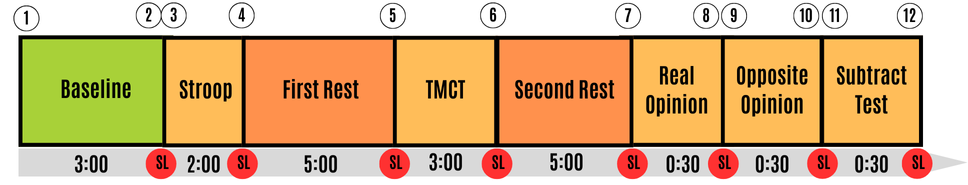


Stress protocol v2


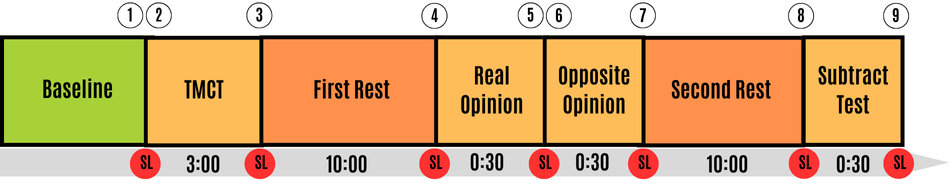

In [101]:

import base64
from IPython.display import display, Image

for i, name in [(9, "Stress protocol v1"), (11, "Stress protocol v2")]:
    print(f"\n{name}")

    attachment = original_nb["cells"][i]["attachments"]
    image_name = next(iter(attachment))
    image_data = attachment[image_name]

    if isinstance(image_data, dict):
        image_data = next(iter(image_data.values()))

    display(Image(data=base64.b64decode(image_data)))


In [100]:

from pathlib import Path

# Check whether the original notebook stores the diagrams internally
for i in [9, 11]:
    cell = original_nb["cells"][i]
    print(f"\nCell {i} attachment keys:")
    print(list(cell.get("attachments", {}).keys()))

# Search the downloaded dataset for the diagram files
search_root = Path("../data/raw/wearable")

for filename in ["stress_v1.png", "stress_v2.png"]:
    matches = list(search_root.rglob(filename))
    print(f"\n{filename}:")
    if matches:
        for path in matches:
            print(path)
    else:
        print("Not found as a separate file.")



Cell 9 attachment keys:
['stress_v1.png']

Cell 11 attachment keys:
['stress_v2.png']

stress_v1.png:
Not found as a separate file.

stress_v2.png:
Not found as a separate file.


In [99]:

# Inspect the original notebook's stress-protocol cells
for i in range(7, 12):
    cell = original_nb["cells"][i]
    source = "".join(cell.get("source", []))

    print(f"\n{'=' * 20} CELL {i} {'=' * 20}")
    print(source[:5000])



==================== CELL 7 ====================
## Stress Induction Protocol

==================== CELL 8 ====================
### First version (S01 to S18)

==================== CELL 9 ====================
![stress_v1.png](attachment:stress_v1.png)

==================== CELL 10 ====================
### Second version (f01 to f18)

==================== CELL 11 ====================
![stress_v2.png](attachment:stress_v2.png)


In [98]:
if notebooks:
    with open(notebooks[0], "r", encoding="utf-8") as f:
        original_nb = json.load(f)

    for i, cell in enumerate(original_nb["cells"]):
        source = "".join(cell.get("source", []))
        if any(word in source.lower() for word in [
            "tags.csv", "protocol", "stress_level",
            "event mark", "timestamp"
        ]):
            print(f"\n--- Cell {i} ---")
            print(source[:2500])
else:
    print("Notebook not found in the searched folder.")


--- Cell 1 ---
This Jupyter Notebook presents the recorded data from the Empatica E4 wristband during structured protocols designed to induce stress, and during aerobic and anaerobic exercise sessions. The signals displayed include:
 
·BVP (Blood Volume Pulse): Adimensional 

·TEMP (Skin Temperature): Measured in degrees Celsius [°C] Celsius 

·HR (Heart Rate): Measured in beats per minute [bpm] 

·EDA (Electrodermal activity): Measured in microsiemens [*μS*]

·ACC (Accelerometer Data): Filtered using a moving average. The accelerometer measures acceleration in the range of [-2g, 2g], with the unit in the ACC.csv file being 1/64g.
 
The x-axis represents time in seconds.

The graphics representing the protocols are also displayed. The times when participants pressed the wristband button are indicated above the protocol timeline. These correspond to the timestamps in the "tags.csv" file. The protocols are summarized as follows:

- Stress* version 1: 12 tags
- Stress* version 2: 9 tags


In [97]:
from pathlib import Path
import json

# Find the original notebook included with the dataset
search_root = Path("../data/raw/wearable")
notebooks = list(search_root.rglob("Wearable_Dataset.ipynb"))

print("Original dataset notebooks found:", len(notebooks))
for path in notebooks:
    print(path)

Original dataset notebooks found: 1
../data/raw/wearable/Wearable_Dataset.ipynb


In [96]:

# Display S05 ratings in protocol order

s05_ratings = stress_ratings[
    stress_ratings["subject_id"].astype(str).str.strip() == "S05"
].copy()

protocol_order_v1 = [
    "Baseline",
    "Stroop",
    "First Rest",
    "TMCT",
    "Second Rest",
    "Real Opinion",
    "Opposite Opinion",
    "Subtract",
]

s05_ratings["protocol_stage"] = pd.Categorical(
    s05_ratings["protocol_stage"],
    categories=protocol_order_v1,
    ordered=True
)

s05_ratings = s05_ratings.sort_values("protocol_stage")

print("S05 stress ratings in protocol order:")
display(s05_ratings)

print("\nS05 event markers in chronological order:")
display(
    s05_events[
        ["tag_time", "elapsed_seconds",
         "interval_from_previous_seconds"]
    ]
)


S05 stress ratings in protocol order:


,subject_id,protocol_stage,self_reported_stress,label_version
4,S05,Baseline,1.0,v1
22,S05,Stroop,2.0,v1
40,S05,First Rest,1.0,v1
58,S05,TMCT,4.0,v1
76,S05,Second Rest,1.0,v1
94,S05,Real Opinion,2.0,v1
112,S05,Opposite Opinion,2.0,v1
130,S05,Subtract,3.0,v1



S05 event markers in chronological order:


,tag_time,elapsed_seconds,interval_from_previous_seconds
0,2013-02-23 11:49:42,186.0,NaN
1,2013-02-23 11:52:45,369.0,183.0
2,2013-02-23 11:54:24,468.0,99.0
3,2013-02-23 11:56:16,580.0,112.0
4,2013-02-23 12:01:52,916.0,336.0
5,2013-02-23 12:04:41,1085.0,169.0
6,2013-02-23 12:08:28,1312.0,227.0
7,2013-02-23 12:09:02,1346.0,34.0
8,2013-02-23 12:10:03,1407.0,61.0
9,2013-02-23 12:10:34,1438.0,31.0


In [95]:

from pathlib import Path

data_root = Path("../data/raw/wearable")

doc_files = list(data_root.rglob("README.txt"))
doc_files += list(data_root.rglob("Data_Dictionary.csv"))
doc_files += list(data_root.rglob("data_constraints.txt"))

keywords = ["tag", "timestamp", "protocol", "stage", "event"]

for file_path in doc_files:
    print(f"\n{'=' * 60}")
    print("FILE:", file_path)

    try:
        text = file_path.read_text(errors="ignore")
        matches = [
            (i, line.strip())
            for i, line in enumerate(text.splitlines(), start=1)
            if any(word in line.lower() for word in keywords)
        ]

        for line_no, line in matches[:25]:
            print(f"{line_no}: {line}")
    except Exception as e:
        print("Could not read file:", e)



FILE: ../data/raw/wearable/README.txt
2: - 'Stress_Level_v1.csv' and 'Stress_Level_v2.csv' contain self-reported stress levels during the stress protocol for each stage of the study,  respectively.
4: - 'data_constraints.txt' contains detailed information of issues such as incorrect wristband placements, incomplete protocols, and connection problems.
8: - Each of the folders corresponding to each participant contains Empatica E4 files: 'ACC.csv', 'BVP.csv', 'EDA.csv', 'HR.csv', 'IBI.csv', 'tags.csv' and 'TEMP.csv'.
12: - Participants from the first stage are labeled as 'Sxx' while those from the second stage are labeled as 'fxx'.
13: - Session dates and event marks are expressed in UTC and have been adjusted for de-identification. The time shifts have been applied consistently across all records to maintain signal alignment.
14: - Empatica signal files: the first row is the initial time of the session expressed in UTC (Empatica provides time in Unix timestamp format, but files are alr

In [94]:

from pathlib import Path
import pandas as pd

# Load the actual S05 STRESS tags file
tags_path = Path(
    "../data/raw/wearable/Wearable_Dataset/STRESS/S05/tags.csv"
)

print("Tags file exists:", tags_path.exists())

tags_raw_s05 = pd.read_csv(tags_path, header=None)

s05_tag_times = pd.to_datetime(
    tags_raw_s05.iloc[:, 0],
    errors="coerce"
).dropna().reset_index(drop=True)

recording_start = pd.Timestamp("2013-02-23 11:46:36")
recording_end = pd.Timestamp("2013-02-23 12:12:36")

s05_events = pd.DataFrame({"tag_time": s05_tag_times})

s05_events["elapsed_seconds"] = (
    s05_events["tag_time"] - recording_start
).dt.total_seconds()

s05_events["interval_from_previous_seconds"] = (
    s05_events["elapsed_seconds"].diff()
)

s05_events = s05_events[
    s05_events["tag_time"].between(recording_start, recording_end)
].reset_index(drop=True)

print("Valid S05 events:", len(s05_events))
display(s05_events)


Tags file exists: True
Valid S05 events: 13


,tag_time,elapsed_seconds,interval_from_previous_seconds
0,2013-02-23 11:49:42,186.0,NaN
1,2013-02-23 11:52:45,369.0,183.0
2,2013-02-23 11:54:24,468.0,99.0
3,2013-02-23 11:56:16,580.0,112.0
4,2013-02-23 12:01:52,916.0,336.0
5,2013-02-23 12:04:41,1085.0,169.0
6,2013-02-23 12:08:28,1312.0,227.0
7,2013-02-23 12:09:02,1346.0,34.0
8,2013-02-23 12:10:03,1407.0,61.0
9,2013-02-23 12:10:34,1438.0,31.0


In [93]:

# Calculate event offsets relative to the actual S05 recording start

recording_start = pd.Timestamp("2013-02-23 11:46:36")
recording_end = pd.Timestamp("2013-02-23 12:12:36")

s05_events = tag_table.copy()
s05_events["tag_time"] = pd.to_datetime(s05_events["tag_time"])

s05_events["elapsed_seconds"] = (
    s05_events["tag_time"] - recording_start
).dt.total_seconds()

s05_events["interval_from_previous_seconds"] = (
    s05_events["elapsed_seconds"].diff()
)

# Keep only events inside the recording interval
s05_events = s05_events[
    (s05_events["tag_time"] >= recording_start) &
    (s05_events["tag_time"] <= recording_end)
].reset_index(drop=True)

print("Number of valid events:", len(s05_events))
print("\nEvent offsets and intervals:")
display(s05_events)

print("\nRecording duration (seconds):",
      (recording_end - recording_start).total_seconds())


Number of valid events: 0

Event offsets and intervals:


,tag_time,elapsed_seconds,elapsed_minutes,interval_from_previous_seconds



Recording duration (seconds): 1560.0


In [92]:

from pathlib import Path
import pandas as pd

# Locate the actual S05 STRESS tags file
data_root = Path(DATA_PATH)
tag_matches = list(
    data_root.rglob("STRESS/S05/tags.csv")
)

print("Matching files:", tag_matches)

if len(tag_matches) != 1:
    print("Expected exactly one S05 tags.csv file. Check the path above.")
else:
    s05_tag_path = tag_matches[0]
    s05_tags_raw = pd.read_csv(s05_tag_path, header=None)

    s05_tag_times = pd.to_datetime(
        s05_tags_raw.iloc[:, 0],
        errors="coerce"
    ).dropna().sort_values()

    recording_start = pd.to_datetime(
        s05_stress["window_start"].min()
    )
    recording_end = pd.to_datetime(
        s05_stress["window_end"].max()
    )

    print("\nS05 recording start:", recording_start)
    print("S05 recording end:", recording_end)
    print("Number of valid tag timestamps:", len(s05_tag_times))

    print("\nActual S05 tag timestamps:")
    display(s05_tag_times.to_frame(name="tag_time"))

    print("\nTags within the recording interval:")
    display(
        s05_tag_times[
            (s05_tag_times >= recording_start) &
            (s05_tag_times <= recording_end)
        ].to_frame(name="tag_time")
    )


Matching files: [PosixPath('../data/raw/wearable/Wearable_Dataset/STRESS/S05/tags.csv')]

S05 recording start: 2013-02-23 11:46:36
S05 recording end: 2013-02-23 12:12:36
Number of valid tag timestamps: 13

Actual S05 tag timestamps:


,tag_time
0,2013-02-23 11:49:42
1,2013-02-23 11:52:45
2,2013-02-23 11:54:24
3,2013-02-23 11:56:16
4,2013-02-23 12:01:52
5,2013-02-23 12:04:41
6,2013-02-23 12:08:28
7,2013-02-23 12:09:02
8,2013-02-23 12:10:03
9,2013-02-23 12:10:34



Tags within the recording interval:


,tag_time
0,2013-02-23 11:49:42
1,2013-02-23 11:52:45
2,2013-02-23 11:54:24
3,2013-02-23 11:56:16
4,2013-02-23 12:01:52
5,2013-02-23 12:04:41
6,2013-02-23 12:08:28
7,2013-02-23 12:09:02
8,2013-02-23 12:10:03
9,2013-02-23 12:10:34


In [91]:

# Step: Inspect S05 before assigning stress labels

s05_stress = prepared_df[
    (prepared_df["activity"] == "STRESS") &
    (prepared_df["session_id"] == "S05")
].sort_values("window_start")

print("S05 STRESS windows:", len(s05_stress))

if not s05_stress.empty:
    print("\nRecording start:", s05_stress["window_start"].min())
    print("Recording end:", s05_stress["window_end"].max())

    display(
        s05_stress[
            ["session_key", "window_id", "window_start", "window_end"]
        ].head(5)
    )

print("\nS05 event timestamps:")
display(tag_table)

print("\nS05 self-reported stress ratings:")
display(
    stress_ratings[
        stress_ratings["subject_id"].astype(str).str.strip() == "S05"
    ].sort_values("protocol_stage")
)


S05 STRESS windows: 52

Recording start: 2013-02-23 11:46:36
Recording end: 2013-02-23 12:12:36


,session_key,window_id,window_start,window_end
182,STRESS/S05,0,2013-02-23 11:46:36,2013-02-23 11:47:06
183,STRESS/S05,1,2013-02-23 11:47:06,2013-02-23 11:47:36
184,STRESS/S05,2,2013-02-23 11:47:36,2013-02-23 11:48:06
185,STRESS/S05,3,2013-02-23 11:48:06,2013-02-23 11:48:36
186,STRESS/S05,4,2013-02-23 11:48:36,2013-02-23 11:49:06



S05 event timestamps:


,tag_time,elapsed_seconds,elapsed_minutes
0,2013-02-20 18:01:30,371.0,6.183333
1,2013-02-20 18:05:37,618.0,10.300000
2,2013-02-20 18:08:32,793.0,13.216667
3,2013-02-20 18:10:17,898.0,14.966667
4,2013-02-20 18:17:37,1338.0,22.300000
5,2013-02-20 18:19:42,1463.0,24.383333
6,2013-02-20 18:24:49,1770.0,29.500000
7,2013-02-20 18:25:17,1798.0,29.966667
8,2013-02-20 18:25:55,1836.0,30.600000
9,2013-02-20 18:26:32,1873.0,31.216667



S05 self-reported stress ratings:


,subject_id,protocol_stage,self_reported_stress,label_version
4,S05,Baseline,1.0,v1
40,S05,First Rest,1.0,v1
112,S05,Opposite Opinion,2.0,v1
94,S05,Real Opinion,2.0,v1
76,S05,Second Rest,1.0,v1
22,S05,Stroop,2.0,v1
130,S05,Subtract,3.0,v1
58,S05,TMCT,4.0,v1


In [90]:

from pathlib import Path
import pandas as pd

# 1. Inspect the available stress ratings
print("Stress ratings:")
print(stress_ratings.shape)
display(stress_ratings.head(10))

# 2. Inspect the STRESS session time ranges
stress_windows = prepared_df[
    prepared_df["activity"] == "STRESS"
].copy()

session_summary = (
    stress_windows.groupby(["session_id", "session_key"])
    .agg(
        first_window=("window_start", "min"),
        last_window=("window_end", "max"),
        number_of_windows=("window_id", "count")
    )
    .reset_index()
)

print("\nFirst 10 STRESS sessions:")
display(session_summary.head(10))

# 3. Inspect the tag timestamps for S05
dataset_root = Path(DATA_PATH) / "Wearable_Dataset"
tag_path = dataset_root / "STRESS" / "S05" / "tags.csv"

print("\nS05 tags file exists:", tag_path.exists())

if tag_path.exists():
    tags_s05 = pd.read_csv(tag_path, header=None)
    print("Tag file shape:", tags_s05.shape)
    display(tags_s05.head(15))

# 4. Inspect S05 sensor-window time range
print("\nS05 feature windows:")
display(
    stress_windows[
        stress_windows["session_key"] == "STRESS/S05"
    ][["window_id", "window_start", "window_end"]].head(10)
)


Stress ratings:
(270, 4)


,subject_id,protocol_stage,self_reported_stress,label_version
0,S01,Baseline,3.0,v1
1,S02,Baseline,2.0,v1
2,S03,Baseline,3.0,v1
3,S04,Baseline,3.0,v1
4,S05,Baseline,1.0,v1
5,S06,Baseline,2.0,v1
6,S07,Baseline,5.0,v1
7,S08,Baseline,0.0,v1
8,S09,Baseline,7.0,v1
9,S10,Baseline,4.0,v1



First 10 STRESS sessions:


,session_id,session_key,first_window,last_window,number_of_windows
0,S01,STRESS/S01,2013-02-20 17:55:29,2013-02-20 18:31:59,73
1,S03,STRESS/S03,2013-03-06 17:04:23,2013-03-06 17:30:23,52
2,S04,STRESS/S04,2013-02-24 12:23:59,2013-02-24 12:52:29,57
3,S05,STRESS/S05,2013-02-23 11:46:36,2013-02-23 12:12:36,52
4,S06,STRESS/S06,2013-02-23 12:23:09,2013-02-23 12:46:39,47
5,S07,STRESS/S07,2013-02-24 11:48:05,2013-02-24 12:11:35,47
6,S08,STRESS/S08,2013-02-23 16:02:14,2013-02-23 16:25:44,47
7,S09,STRESS/S09,2013-02-24 11:15:38,2013-02-24 11:39:08,47
8,S10,STRESS/S10,2013-02-23 18:03:37,2013-02-23 18:30:37,54
9,S11,STRESS/S11,2013-02-24 09:51:55,2013-02-24 10:14:55,46



S05 tags file exists: True
Tag file shape: (13, 1)


,0
0,2013-02-23 11:49:42
1,2013-02-23 11:52:45
2,2013-02-23 11:54:24
3,2013-02-23 11:56:16
4,2013-02-23 12:01:52
5,2013-02-23 12:04:41
6,2013-02-23 12:08:28
7,2013-02-23 12:09:02
8,2013-02-23 12:10:03
9,2013-02-23 12:10:34



S05 feature windows:


,window_id,window_start,window_end
182,0,2013-02-23 11:46:36,2013-02-23 11:47:06
183,1,2013-02-23 11:47:06,2013-02-23 11:47:36
184,2,2013-02-23 11:47:36,2013-02-23 11:48:06
185,3,2013-02-23 11:48:06,2013-02-23 11:48:36
186,4,2013-02-23 11:48:36,2013-02-23 11:49:06
187,5,2013-02-23 11:49:06,2013-02-23 11:49:36
188,6,2013-02-23 11:49:36,2013-02-23 11:50:06
189,7,2013-02-23 11:50:06,2013-02-23 11:50:36
190,8,2013-02-23 11:50:36,2013-02-23 11:51:06
191,9,2013-02-23 11:51:06,2013-02-23 11:51:36


In [89]:

# Reload the saved dataset to verify it
saved_df = pd.read_csv(output_path)

print("Original shape:", prepared_df.shape)
print("Reloaded shape:", saved_df.shape)

print("\nMissing values in important features:")
feature_cols = [
    "hr_mean", "eda_mean", "acc_mean_magnitude", "bvp_mean"
]
display(saved_df[feature_cols].isna().sum().to_frame("missing_values"))

print("\nDuplicate session-window combinations:")
print(
    saved_df.duplicated(
        subset=["session_key", "window_id"]
    ).sum()
)

print("\nQuality flags after saving:")
print(saved_df["bvp_quality_flag"].value_counts(dropna=False))
print(saved_df["hr_review_flag"].value_counts(dropna=False))


Original shape: (6663, 27)
Reloaded shape: (6663, 27)

Missing values in important features:


,missing_values
hr_mean,0
eda_mean,0
acc_mean_magnitude,0
bvp_mean,93



Duplicate session-window combinations:
0

Quality flags after saving:
bvp_quality_flag
False    6570
True       93
Name: count, dtype: int64
hr_review_flag
False    6614
True       49
Name: count, dtype: int64


In [88]:

from pathlib import Path
import pandas as pd

# Create the processed-data directory
processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

# Save the complete feature dataset
output_path = processed_dir / "wearable_features.csv"
prepared_df.to_csv(output_path, index=False)

print("Dataset saved successfully!")
print("File:", output_path.resolve())
print("Shape:", prepared_df.shape)
print("File exists:", output_path.exists())


Dataset saved successfully!
File: /Users/varsha/Desktop/soldier-health-ai/data/processed/wearable_features.csv
Shape: (6663, 27)
File exists: True


In [87]:

# Inspect the multi-session feature dataset

print("Dataset shape:", prepared_df.shape)

print("\nUnique session types:")
print(prepared_df["activity"].value_counts(dropna=False))

print("\nUnique participants:")
print(prepared_df["session_id"].nunique())

print("\nUnique sessions:")
print(prepared_df["session_key"].nunique())

print("\nWindows per session type:")
display(
    prepared_df.groupby("activity")
    .agg(
        total_windows=("window_id", "count"),
        unique_sessions=("session_key", "nunique"),
        unique_participants=("session_id", "nunique")
    )
)

print("\nQuality-review flags:")
print("BVP flags:")
print(prepared_df["bvp_quality_flag"].value_counts(dropna=False))

print("\nHR flags:")
print(prepared_df["hr_review_flag"].value_counts(dropna=False))

print("\nFirst five rows:")
display(prepared_df.head())


Dataset shape: (6663, 27)

Unique session types:
activity
STRESS       2853
AEROBIC      2169
ANAEROBIC    1641
Name: count, dtype: int64

Unique participants:
41

Unique sessions:
98

Windows per session type:


,total_windows,unique_sessions,unique_participants
activity,,,
AEROBIC,2169,31,31
ANAEROBIC,1641,32,32
STRESS,2853,35,35



Quality-review flags:
BVP flags:
bvp_quality_flag
False    6570
True       93
Name: count, dtype: int64

HR flags:
hr_review_flag
False    6614
True       49
Name: count, dtype: int64

First five rows:


,session_id,session_key,activity,window_id,window_start,window_end,hr_mean,hr_std,hr_min,hr_max,...,bvp_mean,bvp_std,bvp_min,bvp_max,hr_sample_count,eda_sample_count,acc_sample_count,bvp_sample_count,bvp_quality_flag,hr_review_flag
0,S01,STRESS/S01,STRESS,0,2013-02-20 17:55:29,2013-02-20 17:55:59,86.652000,7.317613,59.00,108.67,...,NaN,NaN,NaN,NaN,30,120,960,1920,True,False
1,S01,STRESS/S01,STRESS,1,2013-02-20 17:55:59,2013-02-20 17:56:29,88.509667,0.790209,86.84,89.38,...,-0.279318,96.132308,-340.07,323.66,30,120,960,1920,False,False
2,S01,STRESS/S01,STRESS,2,2013-02-20 17:56:29,2013-02-20 17:56:59,93.193000,2.711455,88.68,96.87,...,0.088859,30.216124,-130.72,105.12,30,120,960,1920,False,False
3,S01,STRESS/S01,STRESS,3,2013-02-20 17:56:59,2013-02-20 17:57:29,89.835667,5.103809,83.25,96.87,...,-0.174302,32.940047,-82.35,60.05,30,120,960,1920,False,False
4,S01,STRESS/S01,STRESS,4,2013-02-20 17:57:29,2013-02-20 17:57:59,82.439333,1.635746,77.83,83.97,...,-0.168906,26.401639,-86.74,94.53,30,120,960,1920,False,False


In [86]:
import pandas as pd

print("DataFrames currently available:\n")

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(f"{name}: shape={obj.shape}")
        print("  Columns:", obj.columns.tolist())
        print()

DataFrames currently available:

tags: shape=(13, 1)
  Columns: [0]

hr_raw: shape=(1127, 1)
  Columns: [0]

hr_clean: shape=(1125, 2)
  Columns: ['timestamp', 'HR']

eda_clean: shape=(4536, 2)
  Columns: ['timestamp', 'EDA']

temp_clean: shape=(4536, 2)
  Columns: ['timestamp', 'TEMP']

acc_clean: shape=(36294, 5)
  Columns: ['timestamp', 'ACC_X', 'ACC_Y', 'ACC_Z', 'ACC_MAG']

bvp_clean: shape=(72589, 2)
  Columns: ['timestamp', 'BVP']

bvp_30: shape=(1921, 2)
  Columns: ['timestamp', 'BVP']

segments_df: shape=(8, 4)
  Columns: ['label', 'start', 'end', 'duration_sec']

final_rest: shape=(1, 4)
  Columns: ['label', 'start', 'end', 'duration_sec']

segment: shape=(7946, 2)
  Columns: ['timestamp', 'BVP']

hr_features_df: shape=(8, 7)
  Columns: ['label', 'mean_hr', 'min_hr', 'max_hr', 'std_hr', 'hr_range', 'hr_change_from_baseline']

eda_features_df: shape=(8, 6)
  Columns: ['label', 'mean_eda', 'min_eda', 'max_eda', 'std_eda', 'eda_range']

feature_df: shape=(8, 13)
  Columns: ['labe

In [84]:

import numpy as np
import pandas as pd
from pathlib import Path

session_path = (
    Path(DATA_PATH)
    / "Wearable_Dataset"
    / "STRESS"
    / "S01"
)

# Load the four sensors using your existing loader
sensors = {
    sensor: load_sensor_csv(
        session_path / f"{sensor}.csv", sensor
    )
    for sensor in ["HR", "EDA", "ACC", "BVP"]
}

# Use the earliest sensor timestamp as the common time origin
session_start = min(
    df["timestamp"].min() for df in sensors.values()
)

window_seconds = 30

# Create a common window ID for every sensor
for sensor, df in sensors.items():
    df["window_id"] = (
        (df["timestamp"] - session_start)
        .dt.total_seconds()
        .floordiv(window_seconds)
        .astype(int)
    )

# Calculate acceleration magnitude
acc = sensors["ACC"]
acc["ACC_magnitude"] = np.sqrt(
    acc["ACC_X"] ** 2
    + acc["ACC_Y"] ** 2
    + acc["ACC_Z"] ** 2
)

def summarize_sensor(df, sensor, columns):
    """Calculate basic statistics for each 30-second window."""
    result = df.groupby("window_id")[columns].agg(
        ["mean", "std", "min", "max"]
    )

    result.columns = [
        f"{sensor}_{column}_{stat}"
        for column, stat in result.columns
    ]

    return result

# Summarize each signal independently
feature_parts = [
    summarize_sensor(sensors["HR"], "HR", ["HR"]),
    summarize_sensor(sensors["EDA"], "EDA", ["EDA"]),
    summarize_sensor(
        sensors["ACC"], "ACC", ["ACC_magnitude"]
    ),
    summarize_sensor(sensors["BVP"], "BVP", ["BVP"]),
]

# Combine summaries by common window ID
s01_features = pd.concat(feature_parts, axis=1).reset_index()

s01_features.insert(0, "subject_id", "S01")
s01_features.insert(1, "session_type", "STRESS")
s01_features["window_start_seconds"] = (
    s01_features["window_id"] * window_seconds
)

print("Feature table shape:", s01_features.shape)
print("Number of windows:", len(s01_features))
print("Missing values per feature:")
display(s01_features.isna().sum().to_frame("missing_count"))

display(s01_features.head(10))


Feature table shape: (75, 20)
Number of windows: 75
Missing values per feature:


,missing_count
subject_id,0
session_type,0
window_id,0
HR_HR_mean,0
HR_HR_std,0
HR_HR_min,0
HR_HR_max,0
EDA_EDA_mean,0
EDA_EDA_std,0
EDA_EDA_min,0


,subject_id,session_type,window_id,HR_HR_mean,HR_HR_std,HR_HR_min,HR_HR_max,EDA_EDA_mean,EDA_EDA_std,EDA_EDA_min,EDA_EDA_max,ACC_ACC_magnitude_mean,ACC_ACC_magnitude_std,ACC_ACC_magnitude_min,ACC_ACC_magnitude_max,BVP_BVP_mean,BVP_BVP_std,BVP_BVP_min,BVP_BVP_max,window_start_seconds
0,S01,STRESS,0,86.724500,9.193781,59.00,108.67,0.201066,0.266698,0.000000,1.172685,65.350677,9.908466,31.874755,184.314948,0.434875,283.196392,-1418.36,1134.52,0
1,S01,STRESS,1,87.592333,0.983746,86.29,89.10,0.276522,0.088712,0.007688,0.448466,64.939333,5.929262,38.405729,97.247108,0.007922,185.180255,-803.93,945.65,30
2,S01,STRESS,2,90.852000,1.972650,88.68,95.05,0.383235,0.014667,0.351085,0.408745,64.816248,5.423928,23.937418,111.548196,-0.590542,55.951768,-340.07,246.72,60
3,S01,STRESS,3,93.949000,3.411120,86.50,96.87,0.410005,0.006251,0.397213,0.422839,64.538853,0.395535,62.649820,66.136223,0.297245,32.254744,-82.35,60.05,90
4,S01,STRESS,4,83.576000,0.684683,82.40,85.83,0.430655,0.006361,0.418995,0.444622,64.325665,0.340923,63.134776,65.368188,-0.093625,26.756362,-86.74,94.53,120
5,S01,STRESS,5,76.677000,2.988432,74.03,82.12,0.453420,0.007916,0.439497,0.472811,64.165779,0.362041,63.134776,65.810334,-0.246776,33.248088,-116.68,66.87,150
6,S01,STRESS,6,68.039667,6.048546,57.63,75.80,0.481770,0.010301,0.466404,0.504844,64.164474,0.949416,55.371473,77.517740,0.222661,31.309771,-126.29,154.46,180
7,S01,STRESS,7,57.461000,1.628196,54.80,60.12,0.523787,0.009612,0.501000,0.538159,63.875140,3.112397,35.242020,86.394444,0.324047,31.121026,-194.85,141.11,210
8,S01,STRESS,8,62.388000,0.989853,60.27,63.43,0.583401,0.012844,0.536878,0.609914,64.702278,0.798594,58.694122,72.090221,-0.201969,28.485024,-81.78,121.27,240
9,S01,STRESS,9,62.340333,0.823087,60.35,63.43,0.604724,0.006514,0.584287,0.618883,64.625862,0.394295,63.039670,66.407831,-0.128401,15.857649,-41.23,27.46,270


In [83]:
from pathlib import Path

session_path = (
    Path(DATA_PATH)
    / "Wearable_Dataset"
    / "STRESS"
    / "S01"
)

print("Session exists:", session_path.exists())

for sensor in ["HR", "EDA", "ACC", "BVP"]:
    file_path = session_path / f"{sensor}.csv"

    if not file_path.exists():
        print(f"\n{sensor}: FILE NOT FOUND")
        continue

    try:
        df = load_sensor_csv(file_path, sensor)

        print(f"\n--- {sensor} ---")
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())

        if "timestamp" in df.columns:
            print("Start:", df["timestamp"].min())
            print("End:", df["timestamp"].max())

        display(df.head(3))

    except Exception as e:
        print(f"\n{sensor} loading error: {e}")

Session exists: True

--- HR ---
Shape: (2215, 2)
Columns: ['timestamp', 'HR']
Start: 2013-02-20 17:55:29
End: 2013-02-20 18:32:23


,timestamp,HR
0,2013-02-20 17:55:29,59.00
1,2013-02-20 17:55:30,79.50
2,2013-02-20 17:55:31,108.67



--- EDA ---
Shape: (8898, 2)
Columns: ['timestamp', 'EDA']
Start: 2013-02-20 17:55:19
End: 2013-02-20 18:32:23.250000


,timestamp,EDA
0,2013-02-20 17:55:19.000,0.000000
1,2013-02-20 17:55:19.250,0.005125
2,2013-02-20 17:55:19.500,0.001281



--- ACC ---
Shape: (71178, 4)
Columns: ['timestamp', 'ACC_X', 'ACC_Y', 'ACC_Z']
Start: 2013-02-20 17:55:19
End: 2013-02-20 18:32:23.281250


,timestamp,ACC_X,ACC_Y,ACC_Z
0,2013-02-20 17:55:19.000000,3.0,3.0,61.0
1,2013-02-20 17:55:19.031250,3.0,3.0,61.0
2,2013-02-20 17:55:19.062500,3.0,2.0,61.0



--- BVP ---
Shape: (142351, 2)
Columns: ['timestamp', 'BVP']
Start: 2013-02-20 17:55:19
End: 2013-02-20 18:32:23.218750


,timestamp,BVP
0,2013-02-20 17:55:19.000000,-0.0
1,2013-02-20 17:55:19.015625,-0.0
2,2013-02-20 17:55:19.031250,-0.0


In [82]:
print("DATA_PATH exists:", "DATA_PATH" in globals())
print("Sensor loader exists:", "load_sensor_csv" in globals())

if "DATA_PATH" in globals():
    print("Dataset path:", DATA_PATH)

DATA_PATH exists: True
Sensor loader exists: True
Dataset path: ../data/raw/wearable


In [81]:
import pandas as pd
from pathlib import Path

session_path = (
    Path("../data/raw/wearable")
    / "Wearable_Dataset"
    / "STRESS"
    / "S01"
)

# Load event timestamps
tags = pd.read_csv(
    session_path / "tags.csv",
    header=None
)

tag_times = pd.to_datetime(tags.iloc[:, 0], errors="coerce")
tag_times = tag_times.dropna().sort_values().reset_index(drop=True)

# Calculate elapsed time and interval between consecutive tags
tag_analysis = pd.DataFrame({
    "tag_time": tag_times
})

tag_analysis["elapsed_seconds"] = (
    tag_analysis["tag_time"] - tag_analysis["tag_time"].iloc[0]
).dt.total_seconds()

tag_analysis["interval_from_previous_seconds"] = (
    tag_analysis["tag_time"].diff().dt.total_seconds()
)

display(tag_analysis.round(2))


/var/folders/mf/8py4pk_53m74zfrhlb793b480000gn/T/ipykernel_3495/2986400294.py:33: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(tag_analysis.round(2))


,tag_time,elapsed_seconds,interval_from_previous_seconds
0,2013-02-20 18:01:30,0.0,NaN
1,2013-02-20 18:05:37,247.0,247.0
2,2013-02-20 18:08:32,422.0,175.0
3,2013-02-20 18:10:17,527.0,105.0
4,2013-02-20 18:17:37,967.0,440.0
5,2013-02-20 18:19:42,1092.0,125.0
6,2013-02-20 18:24:49,1399.0,307.0
7,2013-02-20 18:25:17,1427.0,28.0
8,2013-02-20 18:25:55,1465.0,38.0
9,2013-02-20 18:26:32,1502.0,37.0


In [80]:

from pathlib import Path
import pandas as pd

# Locate the S05 stress-session files
session_path = Path("../data/raw/wearable/Wearable_Dataset/STRESS/S05")

print("Session path exists:", session_path.exists())
print("Files:", [p.name for p in session_path.iterdir()])

# Inspect the event tags
tags_path = session_path / "tags.csv"
tags_raw = pd.read_csv(tags_path, header=None)

print("\nTags shape:", tags_raw.shape)
print("First rows:")
display(tags_raw.head(20))

print("\nLast rows:")
display(tags_raw.tail(5))


Session path exists: True
Files: ['TEMP.csv', 'tags.csv', 'HR.csv', 'ACC.csv', 'IBI.csv', 'EDA.csv', 'BVP.csv']

Tags shape: (13, 1)
First rows:


,0
0,2013-02-23 11:49:42
1,2013-02-23 11:52:45
2,2013-02-23 11:54:24
3,2013-02-23 11:56:16
4,2013-02-23 12:01:52
5,2013-02-23 12:04:41
6,2013-02-23 12:08:28
7,2013-02-23 12:09:02
8,2013-02-23 12:10:03
9,2013-02-23 12:10:34



Last rows:


,0
8,2013-02-23 12:10:03
9,2013-02-23 12:10:34
10,2013-02-23 12:11:19
11,2013-02-23 12:11:51
12,2013-02-23 12:12:03


In [79]:

print("Available protocol stages:")
print(sorted(stress_rating_df["protocol_stage"].unique()))

print("\nRatings per version:")
print(stress_rating_df["label_version"].value_counts())

print("\nRatings for S05:")
display(
    stress_rating_df[
        stress_rating_df["subject_id"] == "S05"
    ]
)


Available protocol stages:
['Baseline', 'First Rest', 'Opposite Opinion', 'Real Opinion', 'Second Rest', 'Stroop', 'Subtract', 'TMCT']

Ratings per version:
label_version
v1    144
v2    126
Name: count, dtype: int64

Ratings for S05:


,subject_id,protocol_stage,self_reported_stress,label_version
4,S05,Baseline,1.0,v1
22,S05,Stroop,2.0,v1
40,S05,First Rest,1.0,v1
58,S05,TMCT,4.0,v1
76,S05,Second Rest,1.0,v1
94,S05,Real Opinion,2.0,v1
112,S05,Opposite Opinion,2.0,v1
130,S05,Subtract,3.0,v1


Dataset shape: (8, 13)

Protocol stages:
label
baseline      1
sprint_1      1
cooldown_1    1
sprint_2      1
cooldown_2    1
sprint_3      1
cooldown_3    1
final_rest    1
Name: count, dtype: int64

Missing values: 0

Available columns:
['label', 'mean_hr', 'min_hr', 'max_hr', 'std_hr', 'hr_range', 'hr_change_from_baseline', 'mean_eda', 'min_eda', 'max_eda', 'std_eda', 'eda_range', 'eda_change_from_baseline']

Subject column is missing.


Shape: (8, 13)

Columns:
['label', 'mean_hr', 'min_hr', 'max_hr', 'std_hr', 'hr_range', 'hr_change_from_baseline', 'mean_eda', 'min_eda', 'max_eda', 'std_eda', 'eda_range', 'eda_change_from_baseline']

First 5 rows:


,label,mean_hr,min_hr,max_hr,std_hr,hr_range,hr_change_from_baseline,mean_eda,min_eda,max_eda,std_eda,eda_range,eda_change_from_baseline
0,baseline,93.559535,48.00,97.85,5.969572,49.85,0.000000,5.381012,0.000000,11.387393,3.375471,11.387393,0.000000
1,sprint_1,96.153611,94.95,97.37,0.664909,2.42,2.594076,22.003715,10.308837,31.220554,6.671426,20.911717,16.622703
2,cooldown_1,110.405967,97.67,124.40,8.124666,26.73,16.846432,36.819936,30.440855,38.614529,0.969026,8.173674,31.438924
3,sprint_2,100.176250,99.28,100.77,0.529545,1.49,6.616715,36.870499,33.402710,40.757568,1.904481,7.354858,31.489487
4,cooldown_2,108.913592,95.25,130.65,9.560300,35.40,15.354057,54.089143,37.987179,62.549942,4.416637,24.562763,48.708130


STRESS
	S02: Files downloaded from E4 Connect have duplicated signals. Duplicated raw values start in: ACC.csv: row 49,545; BVP.csv: row 99,091; EDA.csv and TEMP.csv: row 6,195. As IBI and HR files are obtained from the BVP signal through Empatica's algorithm, it is not evident where the duplicated data start.
	f07: The protection dock was never removed from the wristband, covering the PPG and TEMPERATURE sensors. Thus, only the ELECTRODERMAL ACTIVITY AND ACCELEROMETER DATA measurements are valid.
	f14: Bluetooth connection was lost during registration. The baseline is in file f14_a, and the rest of the protocol is in file f14_b.

AEROBIC
	S03: Ended the protocol early, only reaching 90 rpm.
	S07: Ended the protocol early, only reaching 95 rpm.
	S11: Bluetooth connection was lost during registration. File S11_a includes data up to 105 rpm, and S11_b includes the last 110 rpm block.
	S12: Did not perform the aerobic protocol, so there are no data.

ANAEROBIC
	S01: The IBI file d

# FILES
- 'Stress_Level_v1.csv' and 'Stress_Level_v2.csv' contain self-reported stress levels during the stress protocol for each stage of the study,  respectively.
- 'subject-info.csv' contains demographic data such as age, weight, and height for all participants.
- 'data_constraints.txt' contains detailed information of issues such as incorrect wristband placements, incomplete protocols, and connection problems. 
- 'Wearable_Dataset.ipynb'  is a Jupyter Notebook that provides visualizations of all recorded signals and includes sample code for managing the data.
- The main folder 'Wearable_Dataset' contains three folders for each type of activity: 'STRESS', 'AEROBIC' and 'ANAEROBIC'.
- Each of these folders includes participant subfolders named as 'S01','S02','f01',etc.
- Each of the folders corresponding to each participant contains Empatica E4 files: 'ACC.csv', 'BVP.csv', 'EDA.csv', 'HR.csv', 'IBI.csv', 'tags.csv' and 'TEMP.csv'.

# RELEVANT INFO
- Before downloading, we recommend r

Tags file shape: (13, 1)

First 15 tag rows:


,0
0,2013-02-20 18:01:30
1,2013-02-20 18:05:37
2,2013-02-20 18:08:32
3,2013-02-20 18:10:17
4,2013-02-20 18:17:37
5,2013-02-20 18:19:42
6,2013-02-20 18:24:49
7,2013-02-20 18:25:17
8,2013-02-20 18:25:55
9,2013-02-20 18:26:32



HR first two rows:


,0
0,2013-02-20 17:55:29
1,1.0



EDA first two rows:


...

,0,1,2
0,2013-02-20 17:55:19,2013-02-20 17:55:19,2013-02-20 17:55:19
1,32.0,32.0,32.0



BVP first two rows:


,0
0,2013-02-20 17:55:19
1,64.0



TEMP first two rows:


,0
0,2013-02-20 17:55:19
1,4.0



Stress_Level_v1.csv: (18, 9)


,Unnamed: 0,Baseline,Stroop,First Rest,TMCT,Second Rest,Real Opinion,Opposite Opinion,Subtract
0,S01,3.0,4.5,4.0,4.0,5.5,6.0,7.0,7.0
1,S02,2.0,4.0,2.0,2.0,2.0,4.0,5.0,4.0
2,S03,3.0,3.0,3.0,4.0,3.0,3.0,3.0,3.0
3,S04,3.0,3.0,2.0,3.0,1.0,1.0,1.0,1.0
4,S05,1.0,2.0,1.0,4.0,1.0,2.0,2.0,3.0



Stress_Level_v2.csv: (18, 8)


,Unnamed: 0,Baseline,TMCT,First Rest,Real Opinion,Opposite Opinion,Second Rest,Subtract
0,f01,2.0,5.0,2.0,3.0,4.0,2.0,3.0
1,f02,3.0,5.0,1.0,2.0,3.0,2.0,3.0
2,f03,5.0,8.0,1.0,3.0,5.0,1.0,6.0
3,f04,2.0,4.0,3.0,3.0,4.0,1.0,4.0
4,f05,3.0,4.0,3.0,3.0,3.0,2.0,3.0


S01: available=['HR.csv', 'EDA.csv', 'ACC.csv', 'BVP.csv', 'TEMP.csv', 'tags.csv'], missing=[]
S02: available=['HR.csv', 'EDA.csv', 'ACC.csv', 'BVP.csv', 'TEMP.csv', 'tags.csv'], missing=[]
S03: available=['HR.csv', 'EDA.csv', 'ACC.csv', 'BVP.csv', 'TEMP.csv', 'tags.csv'], missing=[]
S04: available=['HR.csv', 'EDA.csv', 'ACC.csv', 'BVP.csv', 'TEMP.csv', 'tags.csv'], missing=[]
S05: available=['HR.csv', 'EDA.csv', 'ACC.csv', 'BVP.csv', 'TEMP.csv', 'tags.csv'], missing=[]
S06: available=['HR.csv', 'EDA.csv', 'ACC.csv', 'BVP.csv', 'TEMP.csv', 'tags.csv'], missing=[]
S07: available=['HR.csv', 'EDA.csv', 'ACC.csv', 'BVP.csv', 'TEMP.csv', 'tags.csv'], missing=[]
S08: available=['HR.csv', 'EDA.csv', 'ACC.csv', 'BVP.csv', 'TEMP.csv', 'tags.csv'], missing=[]
S09: available=['HR.csv', 'EDA.csv', 'ACC.csv', 'BVP.csv', 'TEMP.csv', 'tags.csv'], missing=[]
S10: available=['HR.csv', 'EDA.csv', 'ACC.csv', 'BVP.csv', 'TEMP.csv', 'tags.csv'], missing=[]
S11: available=['HR.csv', 'EDA.csv', 'ACC.csv', 'B


STRESS: 37 participants
['S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07', 'S08', 'S09', 'S10', 'S11', 'S12', 'S13', 'S14', 'S15', 'S16', 'S17', 'S18', 'f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f09', 'f10', 'f11', 'f12', 'f13', 'f14_a', 'f14_b', 'f15', 'f16', 'f17', 'f18']

AEROBIC: 31 participants
['S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07', 'S08', 'S09', 'S10', 'S11_a', 'S11_b', 'S13', 'S14', 'S15', 'S16', 'S17', 'S18', 'f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f09', 'f10', 'f11', 'f12', 'f13']

ANAEROBIC: 32 participants
['S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07', 'S08', 'S09', 'S10', 'S11', 'S12', 'S13', 'S14', 'S15', 'S16_a', 'S16_b', 'S17', 'S18', 'f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f09', 'f10', 'f11', 'f12', 'f13']


Binary dataset shape: (34, 12)

Class distribution:
activity_label
recovery    25
rest         9
Name: count, dtype: int64

Classification Report:
              precision    recall  f1-score   support

    recovery       1.00      1.00      1.00         8
        rest       1.00      1.00      1.00         3

    accuracy                           1.00        11
   macro avg       1.00      1.00      1.00        11
weighted avg       1.00      1.00      1.00        11

Confusion Matrix:
[[3 0]
 [0 8]]


New label distribution:
activity_label
recovery    25
rest         9
sprint       3
Name: count, dtype: int64

Unmapped labels:
<StringArray>
[]
Length: 0, dtype: str
Class counts:
activity_label
recovery    25
rest         9
sprint       3
Name: count, dtype: int64


Dataset shape: (37, 17)

Columns:
['subject', 'activity', 'start', 'end', 'hr_mean', 'hr_std', 'eda_mean', 'eda_std', 'acc_x_mean', 'acc_x_std', 'acc_y_mean', 'acc_y_std', 'acc_z_mean', 'acc_z_std', 'bvp_mean', 'bvp_std', 'label']

Label distribution:
label
cooldown_1    9
cooldown_2    8
cooldown_3    8
baseline      6
final_rest    3
sprint_1      1
sprint_2      1
sprint_3      1
Name: count, dtype: int64

Missing values:
0


,subject,activity,start,end,hr_mean,hr_std,eda_mean,eda_std,acc_x_mean,acc_x_std,acc_y_mean,acc_y_std,acc_z_mean,acc_z_std,bvp_mean,bvp_std,label
0,S05,ANAEROBIC,2013-02-23 12:43:38,2013-02-23 12:44:08,85.203667,9.711092,1.805698,0.092900,37.065625,3.104242,33.207292,1.735580,39.440625,1.972893,0.178411,20.448998,baseline
1,S05,ANAEROBIC,2013-02-23 12:44:08,2013-02-23 12:44:38,91.408333,1.129623,2.008081,0.192841,40.688542,10.338232,30.072917,11.395307,33.706250,14.092520,-1.331198,32.580213,baseline
2,S05,ANAEROBIC,2013-02-23 12:44:38,2013-02-23 12:45:08,96.256333,0.777854,3.999414,1.184662,40.189583,4.678797,31.193750,3.640908,37.559375,3.688752,1.347531,29.914579,baseline
3,S05,ANAEROBIC,2013-02-23 12:45:08,2013-02-23 12:45:38,97.679333,0.097226,8.029749,0.586067,38.464583,3.825462,32.494792,2.122296,38.550000,2.938537,-0.009104,28.888653,baseline
4,S05,ANAEROBIC,2013-02-23 12:45:38,2013-02-23 12:46:08,95.919667,0.443392,9.052078,0.293565,37.576042,5.038027,31.768750,2.534894,39.838542,3.117821,-0.038635,20.889072,baseline


Feature matrix: (37, 12)
Target vector: (37,)

Features: ['hr_mean', 'hr_std', 'eda_mean', 'eda_std', 'acc_x_mean', 'acc_x_std', 'acc_y_mean', 'acc_y_std', 'acc_z_mean', 'acc_z_std', 'bvp_mean', 'bvp_std']


label
cooldown_1    9
cooldown_2    8
cooldown_3    8
baseline      6
final_rest    3
sprint_1      1
sprint_2      1
sprint_3      1
Name: count, dtype: int64


,subject,activity,start,end,hr_mean,hr_std,eda_mean,eda_std,acc_x_mean,acc_x_std,acc_y_mean,acc_y_std,acc_z_mean,acc_z_std,bvp_mean,bvp_std,label
0,S05,ANAEROBIC,2013-02-23 12:43:38,2013-02-23 12:44:08,85.203667,9.711092,1.805698,0.092900,37.065625,3.104242,33.207292,1.735580,39.440625,1.972893,0.178411,20.448998,baseline
1,S05,ANAEROBIC,2013-02-23 12:44:08,2013-02-23 12:44:38,91.408333,1.129623,2.008081,0.192841,40.688542,10.338232,30.072917,11.395307,33.706250,14.092520,-1.331198,32.580213,baseline
2,S05,ANAEROBIC,2013-02-23 12:44:38,2013-02-23 12:45:08,96.256333,0.777854,3.999414,1.184662,40.189583,4.678797,31.193750,3.640908,37.559375,3.688752,1.347531,29.914579,baseline
3,S05,ANAEROBIC,2013-02-23 12:45:08,2013-02-23 12:45:38,97.679333,0.097226,8.029749,0.586067,38.464583,3.825462,32.494792,2.122296,38.550000,2.938537,-0.009104,28.888653,baseline
4,S05,ANAEROBIC,2013-02-23 12:45:38,2013-02-23 12:46:08,95.919667,0.443392,9.052078,0.293565,37.576042,5.038027,31.768750,2.534894,39.838542,3.117821,-0.038635,20.889072,baseline


Labeled dataset saved!


                     0
0  2013-02-23 12:46:30
1  2013-02-23 12:47:06
2  2013-02-23 12:51:09
3  2013-02-23 12:51:41
4  2013-02-23 12:55:46
5  2013-02-23 12:56:16
6  2013-02-23 13:00:18
Number of windows: 37

Missing values:
subject       0
activity      0
start         0
end           0
hr_mean       0
hr_std        0
eda_mean      0
eda_std       0
acc_x_mean    0
acc_x_std     0
acc_y_mean    0
acc_y_std     0
acc_z_mean    0
acc_z_std     0
bvp_mean      0
bvp_std       0
dtype: int64

Feature columns:
['subject', 'activity', 'start', 'end', 'hr_mean', 'hr_std', 'eda_mean', 'eda_std', 'acc_x_mean', 'acc_x_std', 'acc_y_mean', 'acc_y_std', 'acc_z_mean', 'acc_z_std', 'bvp_mean', 'bvp_std']


Shape: (37, 16)


,subject,activity,start,end,hr_mean,hr_std,eda_mean,eda_std,acc_x_mean,acc_x_std,acc_y_mean,acc_y_std,acc_z_mean,acc_z_std,bvp_mean,bvp_std
0,S05,ANAEROBIC,2013-02-23 12:43:38,2013-02-23 12:44:08,85.203667,9.711092,1.805698,0.092900,37.065625,3.104242,33.207292,1.735580,39.440625,1.972893,0.178411,20.448998
1,S05,ANAEROBIC,2013-02-23 12:44:08,2013-02-23 12:44:38,91.408333,1.129623,2.008081,0.192841,40.688542,10.338232,30.072917,11.395307,33.706250,14.092520,-1.331198,32.580213
2,S05,ANAEROBIC,2013-02-23 12:44:38,2013-02-23 12:45:08,96.256333,0.777854,3.999414,1.184662,40.189583,4.678797,31.193750,3.640908,37.559375,3.688752,1.347531,29.914579
3,S05,ANAEROBIC,2013-02-23 12:45:08,2013-02-23 12:45:38,97.679333,0.097226,8.029749,0.586067,38.464583,3.825462,32.494792,2.122296,38.550000,2.938537,-0.009104,28.888653
4,S05,ANAEROBIC,2013-02-23 12:45:38,2013-02-23 12:46:08,95.919667,0.443392,9.052078,0.293565,37.576042,5.038027,31.768750,2.534894,39.838542,3.117821,-0.038635,20.889072


Shape: (37, 17)

Columns:
['subject', 'activity', 'start', 'end', 'hr_mean', 'hr_std', 'eda_mean', 'eda_std', 'acc_x_mean', 'acc_x_std', 'acc_y_mean', 'acc_y_std', 'acc_z_mean', 'acc_z_std', 'bvp_mean', 'bvp_std', 'label']

Windows per label:
label
cooldown_1    9
cooldown_2    8
cooldown_3    8
baseline      6
final_rest    3
sprint_1      1
sprint_2      1
sprint_3      1
Name: count, dtype: int64
STRESS: 37 participant folders
['S05', 'f18', 'S02', 'f11', 'f16', 'f17', 'f10', 'S03', 'S04', 'f14_b']
AEROBIC: 31 participant folders
['S05', 'S02', 'f11', 'f10', 'S03', 'S04', 'f03', 'f04', 'S17', 'S10']
ANAEROBIC: 32 participant folders
['S05', 'S02', 'f11', 'f10', 'S03', 'S04', 'S16_a', 'f03', 'f04', 'S17']


Feature dataset saved successfully!


Dataset shape: (37, 21)


,subject,activity,label,start,end,hr_mean,hr_std,hr_min,hr_max,eda_mean,...,eda_min,eda_max,acc_mean,acc_std,acc_min,acc_max,bvp_mean,bvp_std,bvp_min,bvp_max
0,S05,ANAEROBIC,baseline,2013-02-23 12:43:28,2013-02-23 12:43:58,82.773500,11.122721,48.00,90.30,1.685318,...,0.000000,2.047585,63.629229,1.157130,53.814496,71.182863,0.087677,53.628236,-555.07,227.49
1,S05,ANAEROBIC,baseline,2013-02-23 12:43:58,2013-02-23 12:44:28,90.544333,0.776143,89.73,92.18,1.862915,...,1.718382,2.232041,63.677735,2.029533,37.762415,92.509459,0.197651,19.472197,-96.35,52.51
2,S05,ANAEROBIC,baseline,2013-02-23 12:44:28,2013-02-23 12:44:58,94.827333,1.650016,92.27,96.68,2.955111,...,2.033494,4.805975,63.995482,5.892721,36.619667,138.715536,-0.121839,36.824608,-237.79,154.07
3,S05,ANAEROBIC,baseline,2013-02-23 12:44:58,2013-02-23 12:45:28,97.449000,0.406574,96.60,97.85,7.002105,...,4.786761,8.581023,63.561424,1.660370,52.096065,77.395090,-0.274917,31.434140,-103.79,113.34
4,S05,ANAEROBIC,baseline,2013-02-23 12:45:28,2013-02-23 12:45:58,96.533333,0.892006,95.38,97.73,8.824875,...,8.283644,9.631703,63.580941,1.283057,59.093147,69.455021,0.220635,21.677386,-57.95,47.54


get_segment: True
hr_clean: True
eda_clean: True
acc_clean: True
bvp_clean: True
windows_df: True


         label               start                 end
0     baseline 2013-02-23 12:43:28 2013-02-23 12:43:58
1     baseline 2013-02-23 12:43:58 2013-02-23 12:44:28
2     baseline 2013-02-23 12:44:28 2013-02-23 12:44:58
3     baseline 2013-02-23 12:44:58 2013-02-23 12:45:28
4     baseline 2013-02-23 12:45:28 2013-02-23 12:45:58
5     baseline 2013-02-23 12:45:58 2013-02-23 12:46:28
6     sprint_1 2013-02-23 12:46:30 2013-02-23 12:47:00
7   cooldown_1 2013-02-23 12:47:06 2013-02-23 12:47:36
8   cooldown_1 2013-02-23 12:47:36 2013-02-23 12:48:06
9   cooldown_1 2013-02-23 12:48:06 2013-02-23 12:48:36
10  cooldown_1 2013-02-23 12:48:36 2013-02-23 12:49:06
11  cooldown_1 2013-02-23 12:49:06 2013-02-23 12:49:36
12  cooldown_1 2013-02-23 12:49:36 2013-02-23 12:50:06
13  cooldown_1 2013-02-23 12:50:06 2013-02-23 12:50:36
14  cooldown_1 2013-02-23 12:50:36 2013-02-23 12:51:06
15    sprint_2 2013-02-23 12:51:09 2013-02-23 12:51:39
16  cooldown_2 2013-02-23 12:51:41 2013-02-23 12:52:11
17  cooldo

baseline → 11648 samples
sprint_1 → 2304 samples
cooldown_1 → 15552 samples
sprint_2 → 2048 samples
cooldown_2 → 15680 samples
sprint_3 → 1920 samples
cooldown_3 → 15488 samples
final_rest → 7946 samples
        label  mean_bvp  min_bvp  max_bvp    std_bvp  bvp_range
0    baseline  0.003310  -555.07   227.49  33.009254     782.56
1    sprint_1  0.195833  -289.27   246.32  58.883475     535.59
2  cooldown_1 -0.041339  -248.30   154.11  29.130344     402.41
3    sprint_2 -0.175410  -239.06   122.20  43.437147     361.26
4  cooldown_2  0.019618  -458.87   356.09  57.428746     814.96
5    sprint_3 -0.819708  -312.40   205.24  65.114798     517.64
6  cooldown_3  0.121386  -643.81   436.19  66.585799    1080.00
7  final_rest  0.024240  -365.48   163.07  31.954574     528.55


baseline → 5824 samples
sprint_1 → 1152 samples
cooldown_1 → 7776 samples
sprint_2 → 1024 samples
cooldown_2 → 7840 samples
sprint_3 → 960 samples
cooldown_3 → 7744 samples
final_rest → 3973 samples
        label   mean_acc    min_acc     max_acc    std_acc   acc_range
0    baseline  63.697725  36.619667  138.715536   2.812003  102.095869
1    sprint_1  66.501457  31.780497  125.996032   9.273043   94.215535
2  cooldown_1  63.779861  38.923001  133.187837   2.338732   94.264836
3    sprint_2  66.385163  31.192948  110.652610   9.153806   79.459662
4  cooldown_2  64.440879  16.309506  185.415749   6.855078  169.106243
5    sprint_3  66.860287  35.860842  129.903811  10.635584   94.042968
6  cooldown_3  64.411753  41.833001  132.295125   2.306978   90.462123
7  final_rest  63.698644  45.122057  129.869165   1.720144   84.747108


        label     mean_hr  min_hr  max_hr    std_hr  hr_range  \
0    baseline   93.559535   48.00   97.85  5.969572     49.85   
1    sprint_1   96.153611   94.95   97.37  0.664909      2.42   
2  cooldown_1  110.405967   97.67  124.40  8.124666     26.73   
3    sprint_2  100.176250   99.28  100.77  0.529545      1.49   
4  cooldown_2  108.913592   95.25  130.65  9.560300     35.40   
5    sprint_3   99.927333   98.02  101.70  1.233383      3.68   
6  cooldown_3  114.348388  101.80  131.50  8.394989     29.70   
7  final_rest   95.914720   88.97  103.47  4.203041     14.50   

   hr_change_from_baseline   mean_eda    min_eda    max_eda   std_eda  \
0                 0.000000   5.381012   0.000000  11.387393  3.375471   
1                 2.594076  22.003715  10.308837  31.220554  6.671426   
2                16.846432  36.819936  30.440855  38.614529  0.969026   
3                 6.616715  36.870499  33.402710  40.757568  1.904481   
4                15.354057  54.089143  37.987179 

baseline → 728 samples
sprint_1 → 144 samples
cooldown_1 → 972 samples
sprint_2 → 128 samples
cooldown_2 → 980 samples
sprint_3 → 120 samples
cooldown_3 → 968 samples
final_rest → 496 samples
        label   mean_eda    min_eda    max_eda   std_eda  eda_range
0    baseline   5.381012   0.000000  11.387393  3.375471  11.387393
1    sprint_1  22.003715  10.308837  31.220554  6.671426  20.911717
2  cooldown_1  36.819936  30.440855  38.614529  0.969026   8.173674
3    sprint_2  36.870499  33.402710  40.757568  1.904481   7.354858
4  cooldown_2  54.089143  37.987179  62.549942  4.416637  24.562763
5    sprint_3  49.169249  42.473755  53.835064  2.451545  11.361309
6  cooldown_3  58.578989  53.044941  63.785847  2.176067  10.740906
7  final_rest  50.492253  44.384819  60.583729  4.931693  16.198910


Baseline mean HR: 93.55953488372093
        label     mean_hr  min_hr  max_hr    std_hr  hr_range  \
0    baseline   93.559535   48.00   97.85  5.969572     49.85   
1    sprint_1   96.153611   94.95   97.37  0.664909      2.42   
2  cooldown_1  110.405967   97.67  124.40  8.124666     26.73   
3    sprint_2  100.176250   99.28  100.77  0.529545      1.49   
4  cooldown_2  108.913592   95.25  130.65  9.560300     35.40   
5    sprint_3   99.927333   98.02  101.70  1.233383      3.68   
6  cooldown_3  114.348388  101.80  131.50  8.394989     29.70   
7  final_rest   95.914720   88.97  103.47  4.203041     14.50   

   hr_change_from_baseline  
0                 0.000000  
1                 2.594076  
2                16.846432  
3                 6.616715  
4                15.354057  
5                 6.367798  
6                20.788854  
7                 2.355185  


        label               start                        end  duration_sec
0    baseline 2013-02-23 12:43:28 2013-02-23 12:46:30.000000     182.00000
1    sprint_1 2013-02-23 12:46:30 2013-02-23 12:47:06.000000      36.00000
2  cooldown_1 2013-02-23 12:47:06 2013-02-23 12:51:09.000000     243.00000
3    sprint_2 2013-02-23 12:51:09 2013-02-23 12:51:41.000000      32.00000
4  cooldown_2 2013-02-23 12:51:41 2013-02-23 12:55:46.000000     245.00000
5    sprint_3 2013-02-23 12:55:46 2013-02-23 12:56:16.000000      30.00000
6  cooldown_3 2013-02-23 12:56:16 2013-02-23 13:00:18.000000     242.00000
7  final_rest 2013-02-23 13:00:18 2013-02-23 13:02:22.156250     124.15625
baseline → 172 samples
sprint_1 → 36 samples
cooldown_1 → 243 samples
sprint_2 → 32 samples
cooldown_2 → 245 samples
sprint_3 → 30 samples
cooldown_3 → 242 samples
final_rest → 125 samples


<Figure size 1500x500 with 0 Axes>

<Figure size 1500x500 with 0 Axes>

<Figure size 1500x500 with 0 Axes>

<Figure size 1500x500 with 0 Axes>

<Figure size 1500x500 with 0 Axes>

<Figure size 1500x500 with 0 Axes>

<Figure size 1500x500 with 0 Axes>

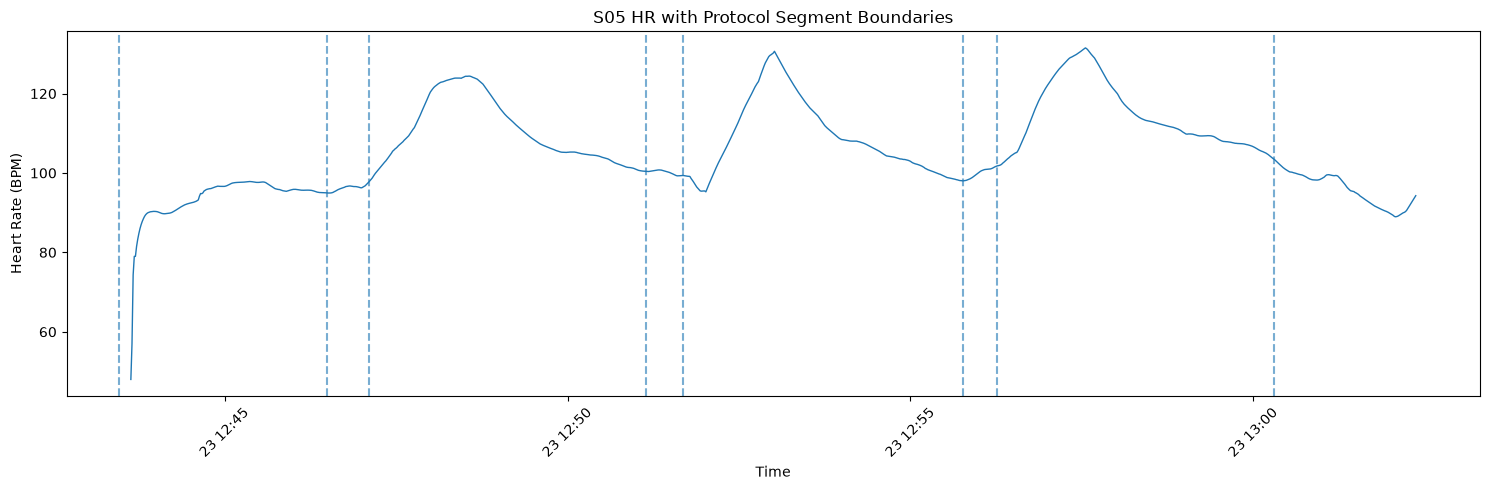

        label               start                        end  duration_sec
0    baseline 2013-02-23 12:43:28 2013-02-23 12:46:30.000000     182.00000
1    sprint_1 2013-02-23 12:46:30 2013-02-23 12:47:06.000000      36.00000
2  cooldown_1 2013-02-23 12:47:06 2013-02-23 12:51:09.000000     243.00000
3    sprint_2 2013-02-23 12:51:09 2013-02-23 12:51:41.000000      32.00000
4  cooldown_2 2013-02-23 12:51:41 2013-02-23 12:55:46.000000     245.00000
5    sprint_3 2013-02-23 12:55:46 2013-02-23 12:56:16.000000      30.00000
6  cooldown_3 2013-02-23 12:56:16 2013-02-23 13:00:18.000000     242.00000
7  final_rest 2013-02-23 13:00:18 2013-02-23 13:02:22.156250     124.15625


        label               start                 end  duration_sec
0    baseline 2013-02-23 12:43:28 2013-02-23 12:46:30         182.0
1    sprint_1 2013-02-23 12:46:30 2013-02-23 12:47:06          36.0
2  cooldown_1 2013-02-23 12:47:06 2013-02-23 12:51:09         243.0
3    sprint_2 2013-02-23 12:51:09 2013-02-23 12:51:41          32.0
4  cooldown_2 2013-02-23 12:51:41 2013-02-23 12:55:46         245.0
5    sprint_3 2013-02-23 12:55:46 2013-02-23 12:56:16          30.0
6  cooldown_3 2013-02-23 12:56:16 2013-02-23 13:00:18         242.0
Final rest:
2013-02-23 13:00:18
2013-02-23 13:02:22.156250
Duration: 124.15625 seconds


# FILES
- 'Stress_Level_v1.csv' and 'Stress_Level_v2.csv' contain self-reported stress levels during the stress protocol for each stage of the study,  respectively.
- 'subject-info.csv' contains demographic data such as age, weight, and height for all participants.
- 'data_constraints.txt' contains detailed information of issues such as incorrect wristband placements, incomplete protocols, and connection problems. 
- 'Wearable_Dataset.ipynb'  is a Jupyter Notebook that provides visualizations of all recorded signals and includes sample code for managing the data.
- The main folder 'Wearable_Dataset' contains three folders for each type of activity: 'STRESS', 'AEROBIC' and 'ANAEROBIC'.
- Each of these folders includes participant subfolders named as 'S01','S02','f01',etc.
- Each of the folders corresponding to each participant contains Empatica E4 files: 'ACC.csv', 'BVP.csv', 'EDA.csv', 'HR.csv', 'IBI.csv', 'tags.csv' and 'TEMP.csv'.

# RELEVANT INFO
- Before downloading, we recommend r

0 2013-02-23 12:46:30
1 2013-02-23 12:47:06
2 2013-02-23 12:51:09
3 2013-02-23 12:51:41
4 2013-02-23 12:55:46
5 2013-02-23 12:56:16
6 2013-02-23 13:00:18
7 
8 
9 
10 
11 
12 
13 
14 


                   timestamp  ACC_X  ACC_Y  ACC_Z    ACC_MAG
0 2013-02-23 12:43:28.000000   41.0   32.0   38.0  64.412732
1 2013-02-23 12:43:28.031250   43.0   30.0   37.0  64.171645
2 2013-02-23 12:43:28.062500   42.0   30.0   39.0  64.691576
3 2013-02-23 12:43:28.093750   45.0   33.0   34.0  65.345237
4 2013-02-23 12:43:28.125000   41.0   32.0   36.0  63.253458
Shape: (36294, 5)


STRESS
•	S02: Files downloaded from E4 Connect have duplicated signals. Duplicated raw values start in: ACC.csv: row 49,545; BVP.csv: row 99,091; EDA.csv and TEMP.csv: row 6,195. As IBI and HR files are obtained from the BVP signal through Empatica's algorithm, it is not evident where the duplicated data start.
•	f07: The protection dock was never removed from the wristband, covering the PPG and TEMPERATURE sensors. Thus, only the ELECTRODERMAL ACTIVITY AND ACCELEROMETER DATA measurements are valid.
•	f14: Bluetooth connection was lost during registration. The baseline is in file f14_a, and the rest of the protocol is in file f14_b.

AEROBIC
•	S03: Ended the protocol early, only reaching 90 rpm.
•	S07: Ended the protocol early, only reaching 95 rpm.
•	S11: Bluetooth connection was lost during registration. File S11_a includes data up to 105 rpm, and S11_b includes the last 110 rpm block.
•	S12: Did not perform the aerobic protocol, so there are no data.

ANAEROBIC
•	S01: The IBI file d

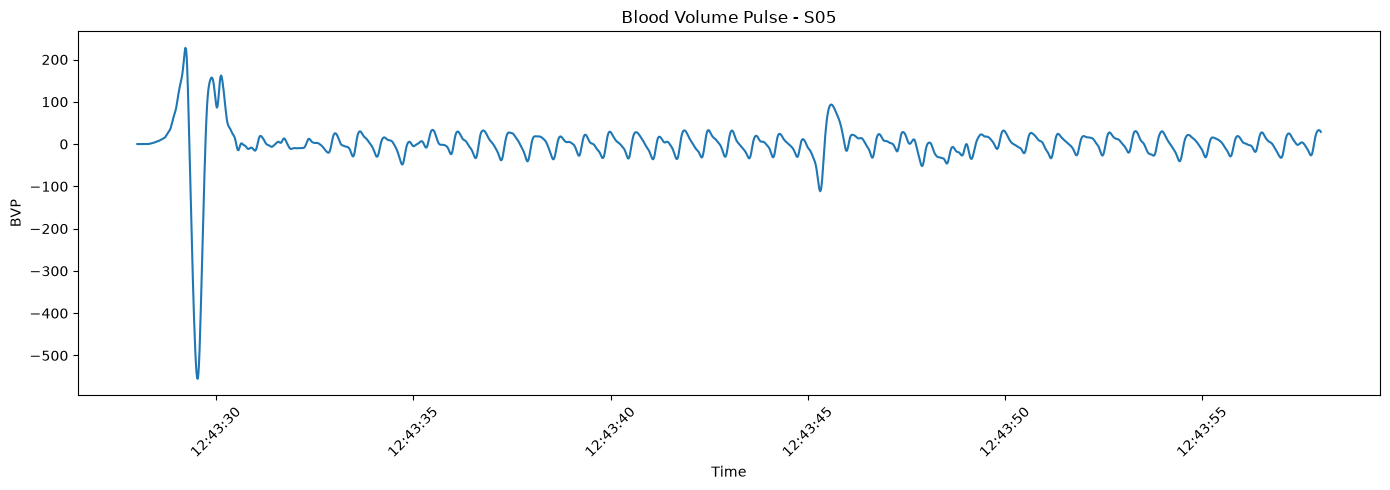

                   timestamp  BVP
0 2013-02-23 12:43:28.000000 -0.0
1 2013-02-23 12:43:28.015625 -0.0
2 2013-02-23 12:43:28.031250 -0.0
3 2013-02-23 12:43:28.046875 -0.0
4 2013-02-23 12:43:28.062500 -0.0

Shape: (72589, 2)

count    72589.000000
mean         0.004841
std         49.010805
min       -643.810000
25%        -21.680000
50%          0.560000
75%         22.370000
max        436.190000
Name: BVP, dtype: float64


HR
count    1125.000000
mean      105.716764
std        10.845151
min        48.000000
25%        97.770000
50%       104.100000
75%       112.080000
max       131.500000
Name: HR, dtype: float64

EDA
count    4536.000000
mean       41.501456
std        18.581407
min         0.000000
25%        36.254459
50%        48.000366
75%        56.899231
max        63.785847
Name: EDA, dtype: float64

ACC
              ACC_X         ACC_Y         ACC_Z       ACC_MAG
count  36294.000000  36294.000000  36294.000000  36294.000000
mean      30.088086     36.444371     37.892241     64.276741
std       17.476613      9.351471      9.594937      4.768618
min     -128.000000    -85.000000    -54.000000     16.309506
25%       25.000000     33.000000     35.000000     63.031738
50%       34.000000     36.000000     40.000000     63.835727
75%       40.000000     41.000000     43.000000     64.876806
max      127.000000    127.000000    127.000000    185.415749


Temperature statistics:
count    4536.000000
mean      142.847337
std        84.460120
min        34.750000
25%        35.370000
50%       208.750000
75%       209.050000
max       220.870000
Name: TEMP, dtype: float64

Unique temperature values:
TEMP
209.05    660
209.07    304
208.69    208
209.41    172
209.43    164
209.45    156
208.75    152
208.71    144
35.47     124
208.73    116
208.91    112
209.13    112
209.03    112
34.84      92
34.93      88
35.49      88
34.95      84
35.45      76
35.50      72
34.89      60
Name: count, dtype: int64

Minimum: 34.75
Maximum: 220.87
                 timestamp    TEMP
0  2013-02-23 12:43:28.000  208.95
1  2013-02-23 12:43:28.250  208.95
2  2013-02-23 12:43:28.500  208.95
3  2013-02-23 12:43:28.750  208.95
4  2013-02-23 12:43:29.000  208.95
5  2013-02-23 12:43:29.250  208.95
6  2013-02-23 12:43:29.500  208.95
7  2013-02-23 12:43:29.750  208.95
8  2013-02-23 12:43:30.000  208.97
9  2013-02-23 12:43:30.250  208.97
10 2013-02-23 12:43:30.50

                   timestamp  ACC_X  ACC_Y  ACC_Z    ACC_MAG
0 2013-02-23 12:43:28.000000   41.0   32.0   38.0  64.412732
1 2013-02-23 12:43:28.031250   43.0   30.0   37.0  64.171645
2 2013-02-23 12:43:28.062500   42.0   30.0   39.0  64.691576
3 2013-02-23 12:43:28.093750   45.0   33.0   34.0  65.345237
4 2013-02-23 12:43:28.125000   41.0   32.0   36.0  63.253458


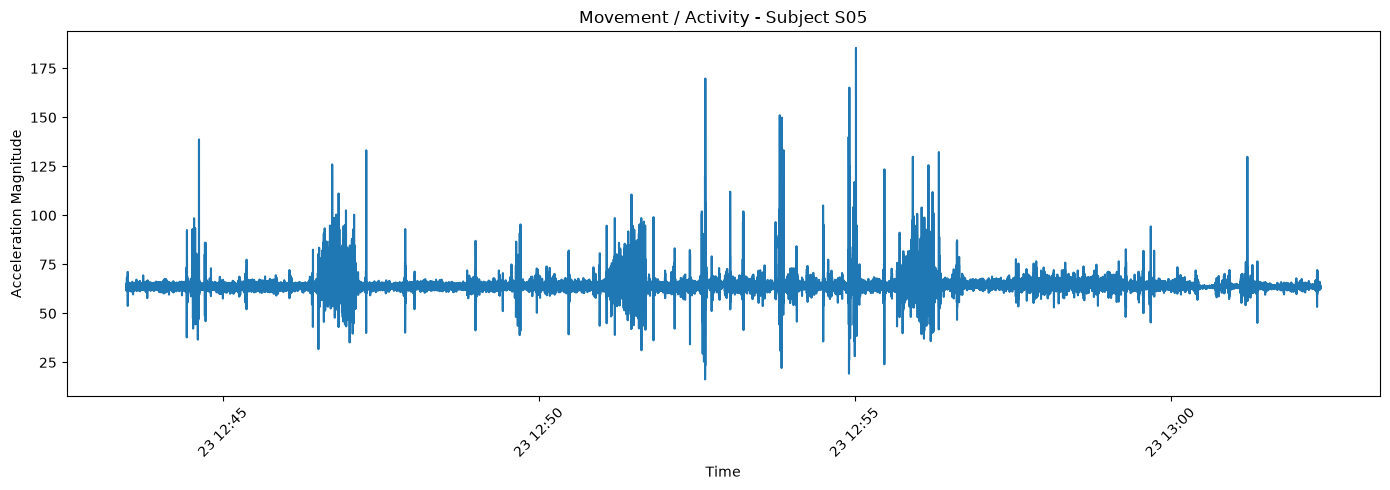

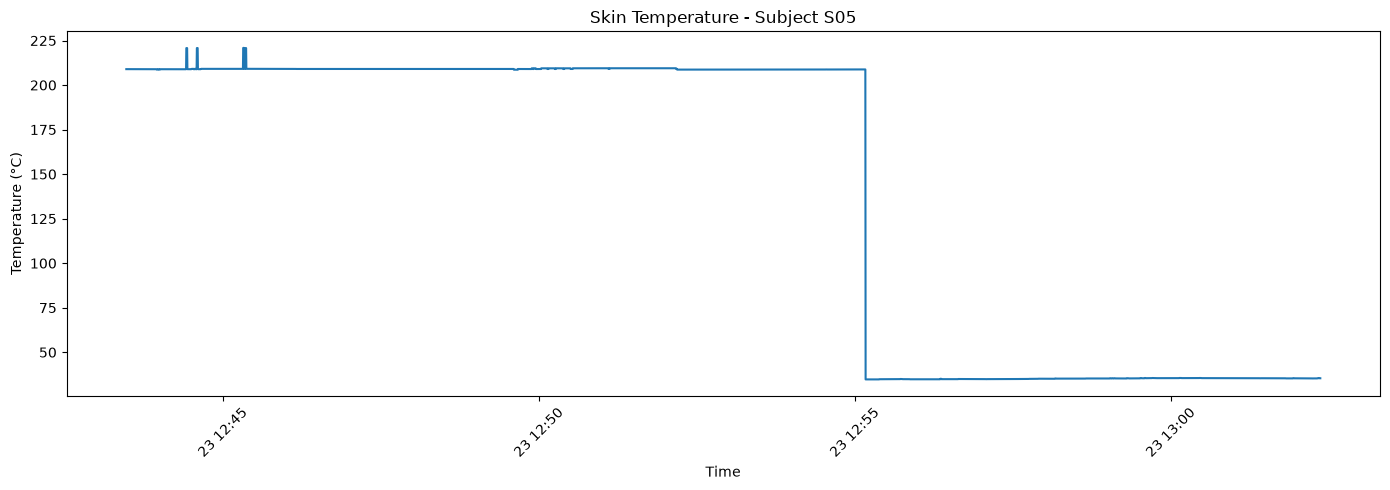

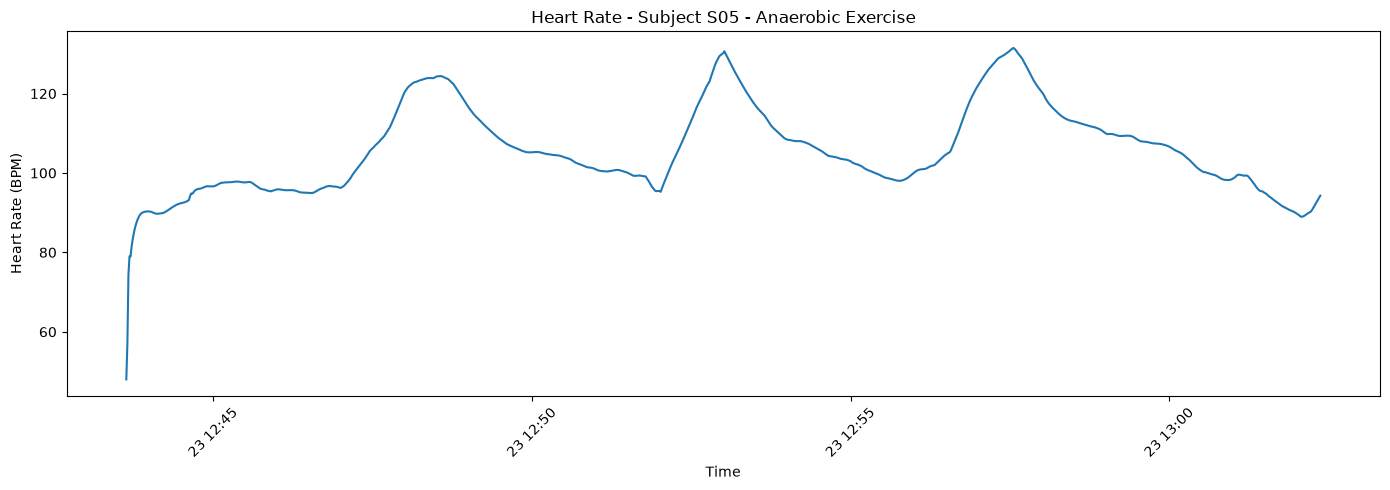

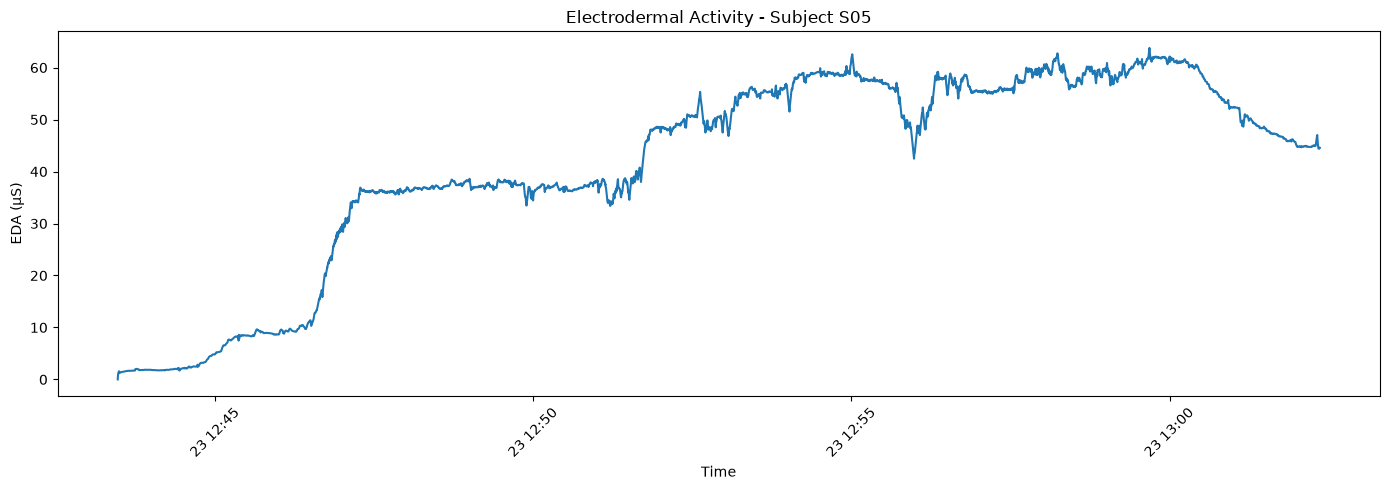

                   timestamp  ACC_X  ACC_Y  ACC_Z
0 2013-02-23 12:43:28.000000   41.0   32.0   38.0
1 2013-02-23 12:43:28.031250   43.0   30.0   37.0
2 2013-02-23 12:43:28.062500   42.0   30.0   39.0
3 2013-02-23 12:43:28.093750   45.0   33.0   34.0
4 2013-02-23 12:43:28.125000   41.0   32.0   36.0

Shape: (36294, 4)


                timestamp    TEMP
0 2013-02-23 12:43:28.000  208.95
1 2013-02-23 12:43:28.250  208.95
2 2013-02-23 12:43:28.500  208.95
3 2013-02-23 12:43:28.750  208.95
4 2013-02-23 12:43:29.000  208.95

Shape: (4536, 2)


                timestamp       EDA
0 2013-02-23 12:43:28.000  0.000000
1 2013-02-23 12:43:28.250  0.836457
2 2013-02-23 12:43:28.500  1.183860
3 2013-02-23 12:43:28.750  1.392723
4 2013-02-23 12:43:29.000  1.446523

Shape: (4536, 2)


            timestamp     HR
0 2013-02-23 12:43:38  48.00
1 2013-02-23 12:43:39  57.00
2 2013-02-23 12:43:40  74.33
3 2013-02-23 12:43:41  79.00
4 2013-02-23 12:43:42  79.00
5 2013-02-23 12:43:43  81.50
6 2013-02-23 12:43:44  83.29
7 2013-02-23 12:43:45  84.75
8 2013-02-23 12:43:46  86.00
9 2013-02-23 12:43:47  87.00

Shape: (1125, 2)

timestamp    datetime64[us]
HR                  float64
dtype: object


In [78]:

import pandas as pd
from pathlib import Path

DATA_PATH = Path("../data/raw/wearable")

# Load the two self-reported stress-rating files
stress_v1 = pd.read_csv(DATA_PATH / "Stress_Level_v1.csv")
stress_v2 = pd.read_csv(DATA_PATH / "Stress_Level_v2.csv")

# Convert each wide table into one row per subject and protocol stage
stress_v1 = stress_v1.rename(columns={"Unnamed: 0": "subject_id"})
stress_v2 = stress_v2.rename(columns={"Unnamed: 0": "subject_id"})

stress_v1_long = stress_v1.melt(
    id_vars="subject_id",
    var_name="protocol_stage",
    value_name="self_reported_stress"
)
stress_v1_long["label_version"] = "v1"

stress_v2_long = stress_v2.melt(
    id_vars="subject_id",
    var_name="protocol_stage",
    value_name="self_reported_stress"
)
stress_v2_long["label_version"] = "v2"

stress_rating_df = pd.concat(
    [stress_v1_long, stress_v2_long],
    ignore_index=True
)

print("Stress-rating shape:", stress_rating_df.shape)
print("\nColumns:", stress_rating_df.columns.tolist())
print("\nMissing ratings:")
print(stress_rating_df["self_reported_stress"].isna().sum())

display(stress_rating_df.head(15))


Stress-rating shape: (270, 4)

Columns: ['subject_id', 'protocol_stage', 'self_reported_stress', 'label_version']

Missing ratings:
0


,subject_id,protocol_stage,self_reported_stress,label_version
0,S01,Baseline,3.0,v1
1,S02,Baseline,2.0,v1
2,S03,Baseline,3.0,v1
3,S04,Baseline,3.0,v1
4,S05,Baseline,1.0,v1
5,S06,Baseline,2.0,v1
6,S07,Baseline,5.0,v1
7,S08,Baseline,0.0,v1
8,S09,Baseline,7.0,v1
9,S10,Baseline,4.0,v1


In [76]:

from pathlib import Path
import pandas as pd

session_path = (
    Path("../data/raw/wearable")
    / "Wearable_Dataset"
    / "STRESS"
    / "S01"
)

# Read the recording start time and sampling rate from each file.
sensor_info = {}

for sensor in ["HR", "EDA", "ACC"]:
    file_path = session_path / f"{sensor}.csv"

    with open(file_path, "r") as f:
        first_line = f.readline().strip().split(",")

    start_time = pd.to_datetime(first_line[0])

    # HR and EDA store their sampling rate in the second row.
    # ACC stores the rate in the first column of its second row.
    second_row = pd.read_csv(file_path, header=None, skiprows=1, nrows=1)
    sampling_rate = float(second_row.iloc[0, 0])

    raw = pd.read_csv(file_path, header=None, skiprows=2)
    duration_seconds = len(raw) / sampling_rate

    sensor_info[sensor] = {
        "start_time": start_time,
        "sampling_rate_hz": sampling_rate,
        "samples": len(raw),
        "duration_seconds": duration_seconds,
        "end_time": start_time + pd.to_timedelta(
            duration_seconds, unit="s"
        ),
    }

print("Sensor recording information:")
display(pd.DataFrame(sensor_info).T)

# Read event tags
tags = pd.read_csv(
    session_path / "tags.csv",
    header=None
).iloc[:, 0]

tags = pd.to_datetime(tags, errors="coerce").dropna()

# Use the earliest sensor start as the common reference.
recording_start = min(
    info["start_time"] for info in sensor_info.values()
)

tag_table = pd.DataFrame({
    "tag_time": tags
})

tag_table["elapsed_seconds"] = (
    tag_table["tag_time"] - recording_start
).dt.total_seconds()

tag_table["elapsed_minutes"] = (
    tag_table["elapsed_seconds"] / 60
)

print("\nEvent tags relative to the earliest sensor start:")
display(tag_table.reset_index(drop=True).round(2))


Sensor recording information:


,start_time,sampling_rate_hz,samples,duration_seconds,end_time
HR,2013-02-20 17:55:29,1.0,2215,2215.0,2013-02-20 18:32:24
EDA,2013-02-20 17:55:19,4.0,8898,2224.5,2013-02-20 18:32:23.500000
ACC,2013-02-20 17:55:19,32.0,71178,2224.3125,2013-02-20 18:32:23.312500



Event tags relative to the earliest sensor start:


/var/folders/mf/8py4pk_53m74zfrhlb793b480000gn/T/ipykernel_3495/26365501.py:69: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(tag_table.reset_index(drop=True).round(2))


,tag_time,elapsed_seconds,elapsed_minutes
0,2013-02-20 18:01:30,371.0,6.18
1,2013-02-20 18:05:37,618.0,10.30
2,2013-02-20 18:08:32,793.0,13.22
3,2013-02-20 18:10:17,898.0,14.97
4,2013-02-20 18:17:37,1338.0,22.30
5,2013-02-20 18:19:42,1463.0,24.38
6,2013-02-20 18:24:49,1770.0,29.50
7,2013-02-20 18:25:17,1798.0,29.97
8,2013-02-20 18:25:55,1836.0,30.60
9,2013-02-20 18:26:32,1873.0,31.22


In [75]:

from pathlib import Path
import pandas as pd

session_path = (
    Path("../data/raw/wearable")
    / "Wearable_Dataset"
    / "STRESS"
    / "S01"
)

# Inspect the beginning and end of the recording
for sensor in ["HR", "EDA", "ACC"]:
    file_path = session_path / f"{sensor}.csv"

    if file_path.exists():
        raw = pd.read_csv(file_path, header=None)

        print(f"\n--- {sensor} ---")
        print("First rows:")
        display(raw.head(4))
        print("Last rows:")
        display(raw.tail(3))

# Inspect event tags
tags_path = session_path / "tags.csv"

if tags_path.exists():
    tags = pd.read_csv(tags_path, header=None)

    print("\n--- S01 STRESS tags ---")
    print("Shape:", tags.shape)
    display(tags.head(15))
else:
    print("tags.csv was not found:", tags_path)



--- HR ---
First rows:


,0
0,2013-02-20 17:55:29
1,1.0
2,59.0
3,79.5


Last rows:


,0
2214,54.75
2215,54.82
2216,54.88



--- EDA ---
First rows:


...

,0,1,2
0,2013-02-20 17:55:19,2013-02-20 17:55:19,2013-02-20 17:55:19
1,32.0,32.0,32.0
2,3.0,3.0,61.0
3,3.0,3.0,61.0


Last rows:


,0,1,2
71177,-26.0,0.0,57.0
71178,-26.0,0.0,57.0
71179,-26.0,0.0,57.0



--- S01 STRESS tags ---
Shape: (13, 1)


,0
0,2013-02-20 18:01:30
1,2013-02-20 18:05:37
2,2013-02-20 18:08:32
3,2013-02-20 18:10:17
4,2013-02-20 18:17:37
5,2013-02-20 18:19:42
6,2013-02-20 18:24:49
7,2013-02-20 18:25:17
8,2013-02-20 18:25:55
9,2013-02-20 18:26:32


In [74]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path("../data/raw/wearable")

# Load participant-level stress ratings
stress_v1 = pd.read_csv(DATA_PATH / "Stress_Level_v1.csv")
stress_v2 = pd.read_csv(DATA_PATH / "Stress_Level_v2.csv")

def convert_to_long_format(df, version):
    df = df.rename(columns={"Unnamed: 0": "subject_id"})

    long_df = df.melt(
        id_vars="subject_id",
        var_name="protocol_stage",
        value_name="self_reported_stress"
    )

    long_df["label_version"] = version
    return long_df

stress_v1_long = convert_to_long_format(stress_v1, "v1")
stress_v2_long = convert_to_long_format(stress_v2, "v2")

stress_ratings = pd.concat(
    [stress_v1_long, stress_v2_long],
    ignore_index=True
)

print("Stress-rating table shape:", stress_ratings.shape)
print("\nMissing ratings:")
print(stress_ratings["self_reported_stress"].isna().sum())

print("\nRatings by version:")
print(stress_ratings.groupby("label_version").size())

display(stress_ratings.head(10))

Stress-rating table shape: (270, 4)

Missing ratings:
0

Ratings by version:
label_version
v1    144
v2    126
dtype: int64


,subject_id,protocol_stage,self_reported_stress,label_version
0,S01,Baseline,3.0,v1
1,S02,Baseline,2.0,v1
2,S03,Baseline,3.0,v1
3,S04,Baseline,3.0,v1
4,S05,Baseline,1.0,v1
5,S06,Baseline,2.0,v1
6,S07,Baseline,5.0,v1
7,S08,Baseline,0.0,v1
8,S09,Baseline,7.0,v1
9,S10,Baseline,4.0,v1


In [73]:
from pathlib import Path
import pandas as pd

# Find the stress-rating files in the raw dataset
search_root = Path("../data/raw/wearable")

for file_name in ["Stress_Level_v1.csv", "Stress_Level_v2.csv"]:
    matches = list(search_root.rglob(file_name))

    print(f"\n{'=' * 50}")
    print(f"File: {file_name}")

    if not matches:
        print("File not found.")
        continue

    file_path = matches[0]
    print("Path:", file_path)

    labels_df = pd.read_csv(file_path)

    print("Shape:", labels_df.shape)
    print("\nColumns:")
    print(labels_df.columns.tolist())

    print("\nFirst 8 rows:")
    display(labels_df.head(8))

    print("\nData types:")
    print(labels_df.dtypes)


File: Stress_Level_v1.csv
Path: ../data/raw/wearable/Stress_Level_v1.csv
Shape: (18, 9)

Columns:
['Unnamed: 0', 'Baseline', 'Stroop', 'First Rest', 'TMCT', 'Second Rest', 'Real Opinion', 'Opposite Opinion', 'Subtract']

First 8 rows:


,Unnamed: 0,Baseline,Stroop,First Rest,TMCT,Second Rest,Real Opinion,Opposite Opinion,Subtract
0,S01,3.0,4.5,4.0,4.0,5.5,6.0,7.0,7.0
1,S02,2.0,4.0,2.0,2.0,2.0,4.0,5.0,4.0
2,S03,3.0,3.0,3.0,4.0,3.0,3.0,3.0,3.0
3,S04,3.0,3.0,2.0,3.0,1.0,1.0,1.0,1.0
4,S05,1.0,2.0,1.0,4.0,1.0,2.0,2.0,3.0
5,S06,2.0,3.0,2.0,5.0,3.0,3.0,3.0,5.0
6,S07,5.0,6.0,6.0,8.0,7.0,8.0,9.0,9.0
7,S08,0.0,1.0,1.0,5.5,1.5,0.5,0.5,1.5



Data types:
Unnamed: 0              str
Baseline            float64
Stroop              float64
First Rest          float64
TMCT                float64
Second Rest         float64
Real Opinion        float64
Opposite Opinion    float64
Subtract            float64
dtype: object

File: Stress_Level_v2.csv
Path: ../data/raw/wearable/Stress_Level_v2.csv
Shape: (18, 8)

Columns:
['Unnamed: 0', 'Baseline', 'TMCT', 'First Rest', 'Real Opinion', 'Opposite Opinion', 'Second Rest', 'Subtract']

First 8 rows:


,Unnamed: 0,Baseline,TMCT,First Rest,Real Opinion,Opposite Opinion,Second Rest,Subtract
0,f01,2.0,5.0,2.0,3.0,4.0,2.0,3.0
1,f02,3.0,5.0,1.0,2.0,3.0,2.0,3.0
2,f03,5.0,8.0,1.0,3.0,5.0,1.0,6.0
3,f04,2.0,4.0,3.0,3.0,4.0,1.0,4.0
4,f05,3.0,4.0,3.0,3.0,3.0,2.0,3.0
5,f06,3.0,4.0,1.0,2.0,3.0,1.0,3.0
6,f07,1.0,4.0,1.0,3.0,1.0,1.0,3.0
7,f08,0.0,3.0,1.0,1.0,1.0,1.0,2.0



Data types:
Unnamed: 0              str
Baseline            float64
TMCT                float64
First Rest          float64
Real Opinion        float64
Opposite Opinion    float64
Second Rest         float64
Subtract            float64
dtype: object


In [72]:
import pandas as pd
from pathlib import Path

# Load the saved, quality-checked dataset
file_path = Path("../data/processed/all_features_prepared.csv")
prepared_df = pd.read_csv(file_path)

print("Dataset shape:", prepared_df.shape)

print("\nColumns:")
print(prepared_df.columns.tolist())

print("\nWindows per activity:")
print(prepared_df["activity"].value_counts())

print("\nQuality flag counts:")
for col in ["bvp_quality_flag", "hr_review_flag"]:
    if col in prepared_df.columns:
        print(f"\n{col}:")
        print(prepared_df[col].value_counts(dropna=False))

print("\nMissing values in each feature:")
print(prepared_df.isna().sum().sort_values(ascending=False))

print("\nFirst 5 rows:")
display(prepared_df.head())

Dataset shape: (6663, 27)

Columns:
['session_id', 'session_key', 'activity', 'window_id', 'window_start', 'window_end', 'hr_mean', 'hr_std', 'hr_min', 'hr_max', 'eda_mean', 'eda_std', 'eda_min', 'eda_max', 'acc_mean_magnitude', 'acc_std_magnitude', 'acc_max_magnitude', 'bvp_mean', 'bvp_std', 'bvp_min', 'bvp_max', 'hr_sample_count', 'eda_sample_count', 'acc_sample_count', 'bvp_sample_count', 'bvp_quality_flag', 'hr_review_flag']

Windows per activity:
activity
STRESS       2853
AEROBIC      2169
ANAEROBIC    1641
Name: count, dtype: int64

Quality flag counts:

bvp_quality_flag:
bvp_quality_flag
False    6570
True       93
Name: count, dtype: int64

hr_review_flag:
hr_review_flag
False    6614
True       49
Name: count, dtype: int64

Missing values in each feature:
bvp_max               93
bvp_min               93
bvp_std               93
bvp_mean              93
session_id             0
acc_mean_magnitude     0
bvp_quality_flag       0
bvp_sample_count       0
acc_sample_count       0

,session_id,session_key,activity,window_id,window_start,window_end,hr_mean,hr_std,hr_min,hr_max,...,bvp_mean,bvp_std,bvp_min,bvp_max,hr_sample_count,eda_sample_count,acc_sample_count,bvp_sample_count,bvp_quality_flag,hr_review_flag
0,S01,STRESS/S01,STRESS,0,2013-02-20 17:55:29,2013-02-20 17:55:59,86.652000,7.317613,59.00,108.67,...,NaN,NaN,NaN,NaN,30,120,960,1920,True,False
1,S01,STRESS/S01,STRESS,1,2013-02-20 17:55:59,2013-02-20 17:56:29,88.509667,0.790209,86.84,89.38,...,-0.279318,96.132308,-340.07,323.66,30,120,960,1920,False,False
2,S01,STRESS/S01,STRESS,2,2013-02-20 17:56:29,2013-02-20 17:56:59,93.193000,2.711455,88.68,96.87,...,0.088859,30.216124,-130.72,105.12,30,120,960,1920,False,False
3,S01,STRESS/S01,STRESS,3,2013-02-20 17:56:59,2013-02-20 17:57:29,89.835667,5.103809,83.25,96.87,...,-0.174302,32.940047,-82.35,60.05,30,120,960,1920,False,False
4,S01,STRESS/S01,STRESS,4,2013-02-20 17:57:29,2013-02-20 17:57:59,82.439333,1.635746,77.83,83.97,...,-0.168906,26.401639,-86.74,94.53,30,120,960,1920,False,False


In [71]:
import pandas as pd

df = pd.read_csv(
    "../data/processed/all_features_quality_checked.csv"
)

# Work on a copy; preserve the original files.
clean_df = df.copy()

bvp_features = [
    "bvp_mean",
    "bvp_std",
    "bvp_min",
    "bvp_max"
]

# Mask BVP features only in flagged windows.
clean_df.loc[
    clean_df["bvp_quality_flag"],
    bvp_features
] = float("nan")

print("Original windows:", len(df))
print("Cleaned windows:", len(clean_df))

print("\nMissing BVP values after masking:")
print(clean_df[bvp_features].isna().sum())

print("\nMissing values in other sensor features:")
other_features = [
    "hr_mean", "hr_std", "hr_min", "hr_max",
    "eda_mean", "eda_std", "eda_min", "eda_max",
    "acc_mean_magnitude", "acc_std_magnitude",
    "acc_max_magnitude"
]
print(clean_df[other_features].isna().sum())

clean_df.to_csv(
    "../data/processed/all_features_prepared.csv",
    index=False
)

print("\nSaved: ../data/processed/all_features_prepared.csv")

Original windows: 6663
Cleaned windows: 6663

Missing BVP values after masking:
bvp_mean    93
bvp_std     93
bvp_min     93
bvp_max     93
dtype: int64

Missing values in other sensor features:
hr_mean               0
hr_std                0
hr_min                0
hr_max                0
eda_mean              0
eda_std               0
eda_min               0
eda_max               0
acc_mean_magnitude    0
acc_std_magnitude     0
acc_max_magnitude     0
dtype: int64

Saved: ../data/processed/all_features_prepared.csv


In [70]:
import pandas as pd

df = pd.read_csv(
    "../data/processed/all_features_quality_checked.csv"
)

# 1. Count flagged windows by session
print("BVP flags by session:")
print(
    df[df["bvp_quality_flag"]]
    .groupby(["session_key", "activity"])
    .size()
    .sort_values(ascending=False)
    .head(15)
)

# 2. Inspect the most extreme BVP windows
print("\nMost extreme BVP windows:")
print(
    df.loc[
        df["bvp_quality_flag"],
        [
            "session_key",
            "activity",
            "window_id",
            "bvp_mean",
            "bvp_std",
            "bvp_min",
            "bvp_max",
        ],
    ]
    .sort_values("bvp_std", ascending=False)
    .head(10)
    .to_string(index=False)
)

# 3. Check whether HR and BVP flags overlap
print("\nFlag overlap:")
print(
    pd.crosstab(
        df["bvp_quality_flag"],
        df["hr_review_flag"],
        rownames=["BVP flagged"],
        colnames=["HR flagged"],
    )
)

BVP flags by session:
session_key    activity 
AEROBIC/f13    AEROBIC      19
STRESS/f03     STRESS       11
AEROBIC/f03    AEROBIC       9
AEROBIC/S04    AEROBIC       7
ANAEROBIC/f03  ANAEROBIC     6
AEROBIC/f08    AEROBIC       5
ANAEROBIC/f13  ANAEROBIC     5
STRESS/f10     STRESS        4
STRESS/f13     STRESS        3
STRESS/f11     STRESS        2
STRESS/S03     STRESS        2
ANAEROBIC/f10  ANAEROBIC     2
AEROBIC/f11    AEROBIC       2
AEROBIC/f06    AEROBIC       2
ANAEROBIC/f01  ANAEROBIC     1
dtype: int64

Most extreme BVP windows:
  session_key  activity  window_id  bvp_mean    bvp_std  bvp_min  bvp_max
ANAEROBIC/f01 ANAEROBIC         59  1.319917 312.506109  -694.29  1022.37
  AEROBIC/S04   AEROBIC          5  1.767547 301.422679 -1137.53   701.29
   STRESS/S01    STRESS          0  0.741807 291.823785 -1418.36  1134.52
  AEROBIC/f13   AEROBIC         55  2.991604 275.186940  -941.77  1534.88
  AEROBIC/f08   AEROBIC         71  2.635760 272.622070  -869.36   758.74
  AE

In [69]:
import pandas as pd
from pathlib import Path

# Load the combined feature dataset
df = pd.read_csv("../data/processed/all_features.csv")

# Flag suspicious BVP windows for review.
# These are screening thresholds, not medical diagnostic limits.
df["bvp_quality_flag"] = (
    (df["bvp_std"] > 180) |
    (df["bvp_min"] < -1000) |
    (df["bvp_max"] > 1000)
)

# Flag extreme HR windows for review, not automatic removal.
df["hr_review_flag"] = (
    (df["hr_max"] > 180) |
    (df["hr_min"] < 40)
)

print("Total windows:", len(df))
print("\nBVP quality flags:", int(df["bvp_quality_flag"].sum()))
print("HR review flags:", int(df["hr_review_flag"].sum()))

print("\nBVP flags by activity:")
print(
    df.groupby("activity")["bvp_quality_flag"]
      .sum()
)

print("\nHR flags by activity:")
print(
    df.groupby("activity")["hr_review_flag"]
      .sum()
)

# Save a separate copy; preserve the original feature dataset.
output_path = Path("../data/processed/all_features_quality_checked.csv")
df.to_csv(output_path, index=False)

print("\nSaved:", output_path)

Total windows: 6663

BVP quality flags: 93
HR review flags: 49

BVP flags by activity:
activity
AEROBIC      48
ANAEROBIC    16
STRESS       29
Name: bvp_quality_flag, dtype: int64

HR flags by activity:
activity
AEROBIC      47
ANAEROBIC     2
STRESS        0
Name: hr_review_flag, dtype: int64

Saved: ../data/processed/all_features_quality_checked.csv


In [68]:

# Inspect extreme BVP windows without deleting any data
bvp_suspicious = check_df[
    (check_df["bvp_min"] < -1000) |
    (check_df["bvp_max"] > 1000) |
    (check_df["bvp_std"] > 250)
].copy()

print("Suspicious BVP windows:", len(bvp_suspicious))

print("\nAffected sessions:")
if not bvp_suspicious.empty:
    display(
        bvp_suspicious[
            [
                "session_key",
                "activity",
                "window_id",
                "window_start",
                "bvp_mean",
                "bvp_std",
                "bvp_min",
                "bvp_max"
            ]
        ].sort_values("bvp_std", ascending=False).head(30)
    )

    print("\nNumber of suspicious windows by session:")
    display(
        bvp_suspicious.groupby(
            ["session_key", "activity"]
        ).size().reset_index(name="suspicious_windows")
        .sort_values("suspicious_windows", ascending=False)
        .head(20)
    )
else:
    print("No windows met these inspection thresholds.")

# Also inspect unusually high heart-rate windows
hr_suspicious = check_df[
    (check_df["hr_max"] > 180) |
    (check_df["hr_min"] < 40)
]

print("\nWindows with HR max > 180 or HR min < 40:",
      len(hr_suspicious))

display(
    hr_suspicious[
        ["session_key", "activity", "window_id",
         "hr_mean", "hr_min", "hr_max"]
    ].head(20)
)


Suspicious BVP windows: 53

Affected sessions:


,session_key,activity,window_id,window_start,bvp_mean,bvp_std,bvp_min,bvp_max
5755,ANAEROBIC/f01,ANAEROBIC,59,2013-06-20 12:26:57,1.319917,312.506109,-694.29,1022.37
3039,AEROBIC/S04,AEROBIC,5,2013-02-23 09:52:56,1.767547,301.422679,-1137.53,701.29
0,STRESS/S01,STRESS,0,2013-02-20 17:55:29,0.741807,291.823785,-1418.36,1134.52
4991,AEROBIC/f13,AEROBIC,55,2013-07-04 13:37:06,2.991604,275.186940,-941.77,1534.88
4619,AEROBIC/f08,AEROBIC,71,2013-07-22 16:21:17,2.635760,272.622070,-869.36,758.74
3038,AEROBIC/S04,AEROBIC,4,2013-02-23 09:52:26,-4.022870,267.042967,-765.34,760.27
2393,STRESS/f15,STRESS,5,2013-07-13 17:22:27,0.578130,266.777627,-1340.25,1396.67
3043,AEROBIC/S04,AEROBIC,9,2013-02-23 09:54:56,2.021823,252.547922,-1213.35,802.53
5021,AEROBIC/f13,AEROBIC,85,2013-07-04 13:52:06,-0.088068,240.433775,-662.64,1127.63
5017,AEROBIC/f13,AEROBIC,81,2013-07-04 13:50:06,-2.677656,240.086740,-1098.61,698.81



Number of suspicious windows by session:


,session_key,activity,suspicious_windows
6,AEROBIC/f13,AEROBIC,9
17,STRESS/f03,STRESS,7
20,STRESS/f10,STRESS,4
3,AEROBIC/f03,AEROBIC,4
0,AEROBIC/S04,AEROBIC,3
9,ANAEROBIC/f03,ANAEROBIC,3
12,ANAEROBIC/f13,ANAEROBIC,3
22,STRESS/f13,STRESS,2
11,ANAEROBIC/f10,ANAEROBIC,2
4,AEROBIC/f08,AEROBIC,2



Windows with HR max > 180 or HR min < 40: 49


,session_key,activity,window_id,hr_mean,hr_min,hr_max
4434,AEROBIC/f06,AEROBIC,52,180.030667,179.38,180.50
4435,AEROBIC/f06,AEROBIC,53,181.372000,180.53,182.23
4436,AEROBIC/f06,AEROBIC,54,179.977667,177.87,182.10
4445,AEROBIC/f06,AEROBIC,63,180.109333,179.70,180.63
4446,AEROBIC/f06,AEROBIC,64,181.029333,180.67,181.23
4447,AEROBIC/f06,AEROBIC,65,181.210000,181.05,181.32
4448,AEROBIC/f06,AEROBIC,66,181.703333,181.33,182.30
4449,AEROBIC/f06,AEROBIC,67,182.488667,182.35,182.57
4450,AEROBIC/f06,AEROBIC,68,182.708667,182.57,182.77
4451,AEROBIC/f06,AEROBIC,69,182.758333,182.57,182.88


In [67]:

# Load the saved dataset to validate the actual CSV
features_path = Path("../data/processed/all_features.csv")
check_df = pd.read_csv(features_path)

print("Dataset shape:", check_df.shape)

print("\nMissing values:")
print(check_df.isna().sum().sort_values(ascending=False).head(10))

print("\nDuplicate complete rows:", check_df.duplicated().sum())

print("\nWindows per activity:")
print(check_df["activity"].value_counts())

# Inspect numeric feature distributions
feature_cols = [
    c for c in check_df.columns
    if c.startswith(("hr_", "eda_", "acc_", "bvp_"))
    and not c.endswith("_sample_count")
]

print("\nFeature summary:")
display(check_df[feature_cols].describe().T)

# Inspect extreme BVP feature values without removing anything
bvp_cols = ["bvp_mean", "bvp_std", "bvp_min", "bvp_max"]

print("\nBVP values at extreme percentiles:")
display(
    check_df[bvp_cols].quantile([0, 0.01, 0.50, 0.99, 1]).T
)

# Verify expected sample counts in retained windows
count_cols = [
    "hr_sample_count",
    "eda_sample_count",
    "acc_sample_count",
    "bvp_sample_count"
]

print("\nSample count consistency:")
display(check_df[count_cols].describe().T)


Dataset shape: (6663, 25)

Missing values:
session_id           0
eda_max              0
acc_sample_count     0
eda_sample_count     0
hr_sample_count      0
bvp_max              0
bvp_min              0
bvp_std              0
bvp_mean             0
acc_max_magnitude    0
dtype: int64

Duplicate complete rows: 0

Windows per activity:
activity
STRESS       2853
AEROBIC      2169
ANAEROBIC    1641
Name: count, dtype: int64

Feature summary:


,count,mean,std,min,25%,50%,75%,max
hr_mean,6663.0,90.394182,23.815547,5.022533e+01,74.116833,84.121667,100.007167,197.208000
hr_std,6663.0,1.606748,1.941799,1.563827e-02,0.488842,0.947493,1.941990,23.699591
hr_min,6663.0,87.697896,23.597957,4.800000e+01,71.920000,81.800000,96.500000,196.770000
hr_max,6663.0,93.011286,24.264598,5.070000e+01,76.300000,86.280000,103.010000,197.450000
eda_mean,6663.0,5.605028,8.716465,0.000000e+00,0.362295,2.061600,7.109761,73.167805
eda_std,6663.0,0.275491,0.526777,0.000000e+00,0.012313,0.112937,0.323942,9.617719
eda_min,6663.0,5.029632,8.165249,0.000000e+00,0.311387,1.624576,6.245081,70.749672
eda_max,6663.0,6.133548,9.264700,0.000000e+00,0.404657,2.414481,7.919997,75.759941
acc_mean_magnitude,6663.0,64.691260,6.952098,6.093348e+01,63.485463,64.253376,64.738596,142.781218
acc_std_magnitude,6663.0,2.953887,2.989436,2.131628e-14,0.790062,1.987524,4.030067,38.361068



BVP values at extreme percentiles:


,0.00,0.01,0.50,0.99,1.00
bvp_mean,-9.022135,-2.358816,-0.001984,2.413204,7.766010
bvp_std,0.000000,8.392991,47.404683,180.526242,312.506109
bvp_min,-2275.110000,-907.946000,-190.760000,-24.505800,0.000000
bvp_max,0.000000,17.152400,181.240000,794.060200,1710.950000



Sample count consistency:


,count,mean,std,min,25%,50%,75%,max
hr_sample_count,6663.0,30.0,0.0,30.0,30.0,30.0,30.0,30.0
eda_sample_count,6663.0,120.0,0.0,120.0,120.0,120.0,120.0,120.0
acc_sample_count,6663.0,960.0,0.0,960.0,960.0,960.0,960.0,960.0
bvp_sample_count,6663.0,1920.0,0.0,1920.0,1920.0,1920.0,1920.0,1920.0


In [66]:

from pathlib import Path
import numpy as np
import pandas as pd
import math

# Sampling rates for the four sensors used in this version
sampling_rates = {
    "HR": 1,
    "EDA": 4,
    "ACC": 32,
    "BVP": 64
}

# Exclude sessions with known problems affecting these sensors
excluded_sessions = {
    ("STRESS", "S02"): "Documented duplicated signals",
    ("STRESS", "f07"): "HR/BVP affected by sensor protection dock"
}

all_rows = []
session_report = []

for activity in ["STRESS", "AEROBIC", "ANAEROBIC"]:
    activity_path = wearable_root / activity

    for session_path in sorted(activity_path.iterdir()):
        if not session_path.is_dir():
            continue

        session_id = session_path.name
        session_key = f"{activity}/{session_id}"

        # Skip sessions excluded for documented quality issues
        if (activity, session_id) in excluded_sessions:
            session_report.append({
                "session": session_key,
                "status": "excluded",
                "reason": excluded_sessions[(activity, session_id)],
                "windows": 0
            })
            continue

        try:
            sensor_dfs = {
                sensor: load_sensor_csv(
                    session_path / f"{sensor}.csv", sensor
                )
                for sensor in sampling_rates
            }

            # Require all four sensors to contain usable data
            if any(
                df.empty or "timestamp" not in df.columns
                for df in sensor_dfs.values()
            ):
                raise ValueError("Empty sensor data or missing timestamps")

            # Common time interval shared by all four sensors
            common_start = max(
                df["timestamp"].min()
                for df in sensor_dfs.values()
            )
            common_end = min(
                df["timestamp"].max()
                for df in sensor_dfs.values()
            )

            if common_end <= common_start:
                raise ValueError("No shared recording interval")

            session_rows = []
            window_start = common_start
            window_id = 0

            while (
                window_start + pd.Timedelta(seconds=WINDOW_SECONDS)
                <= common_end
            ):
                window_end = (
                    window_start + pd.Timedelta(seconds=WINDOW_SECONDS)
                )

                window_dfs = {}
                sample_counts = {}
                valid_window = True

                for sensor, df in sensor_dfs.items():
                    mask = (
                        (df["timestamp"] >= window_start) &
                        (df["timestamp"] < window_end)
                    )
                    window_df = df.loc[mask].copy()

                    # Ignore rows containing non-finite measurements
                    value_cols = [
                        c for c in window_df.columns if c != "timestamp"
                    ]
                    finite_mask = np.isfinite(
                        window_df[value_cols].to_numpy(dtype=float)
                    ).all(axis=1)

                    window_df = window_df.loc[finite_mask]
                    count = len(window_df)
                    sample_counts[sensor] = count

                    expected = (
                        sampling_rates[sensor] * WINDOW_SECONDS
                    )
                    minimum = math.ceil(expected * 0.95)

                    if count < minimum:
                        valid_window = False
                        break

                    window_dfs[sensor] = window_df

                if valid_window:
                    features = extract_aligned_window_features(
                        window_dfs,
                        window_start,
                        window_seconds=WINDOW_SECONDS
                    )

                    row = {
                        "session_id": session_id,
                        "session_key": session_key,
                        "activity": activity,
                        "window_id": window_id,
                        "window_start": window_start,
                        "window_end": window_end,
                        **features,
                        **{
                            f"{sensor.lower()}_sample_count": count
                            for sensor, count in sample_counts.items()
                        }
                    }

                    session_rows.append(row)

                window_start = window_end
                window_id += 1

            all_rows.extend(session_rows)

            session_report.append({
                "session": session_key,
                "status": "processed",
                "reason": "",
                "windows": len(session_rows)
            })

        except Exception as exc:
            session_report.append({
                "session": session_key,
                "status": "error",
                "reason": str(exc),
                "windows": 0
            })

# Create combined feature table and processing report
all_features = pd.DataFrame(all_rows)
report_df = pd.DataFrame(session_report)

print("Combined feature table shape:", all_features.shape)
print("\nSession processing summary:")
print(report_df["status"].value_counts(dropna=False))

print("\nTotal windows per activity:")
if not all_features.empty:
    print(all_features.groupby("activity").size())

print("\nFirst five rows:")
display(all_features.head())

print("\nSessions excluded or failed:")
display(
    report_df[report_df["status"].isin(["excluded", "error"])]
)

# Save results
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

features_file = output_dir / "all_features.csv"
report_file = output_dir / "feature_extraction_report.csv"

all_features.to_csv(features_file, index=False)
report_df.to_csv(report_file, index=False)

print("\nSaved feature table:", features_file)
print("Saved processing report:", report_file)


Combined feature table shape: (6663, 25)

Session processing summary:
status
processed    98
excluded      2
Name: count, dtype: int64

Total windows per activity:
activity
AEROBIC      2169
ANAEROBIC    1641
STRESS       2853
dtype: int64

First five rows:


,session_id,session_key,activity,window_id,window_start,window_end,hr_mean,hr_std,hr_min,hr_max,...,acc_std_magnitude,acc_max_magnitude,bvp_mean,bvp_std,bvp_min,bvp_max,hr_sample_count,eda_sample_count,acc_sample_count,bvp_sample_count
0,S01,STRESS/S01,STRESS,0,2013-02-20 17:55:29,2013-02-20 17:55:59,86.652000,7.317613,59.00,108.67,...,9.101007,184.314948,0.741807,291.823785,-1418.36,1134.52,30,120,960,1920
1,S01,STRESS/S01,STRESS,1,2013-02-20 17:55:59,2013-02-20 17:56:29,88.509667,0.790209,86.84,89.38,...,7.298175,111.548196,-0.279318,96.132308,-340.07,323.66,30,120,960,1920
2,S01,STRESS/S01,STRESS,2,2013-02-20 17:56:29,2013-02-20 17:56:59,93.193000,2.711455,88.68,96.87,...,1.552660,78.185676,0.088859,30.216124,-130.72,105.12,30,120,960,1920
3,S01,STRESS/S01,STRESS,3,2013-02-20 17:56:59,2013-02-20 17:57:29,89.835667,5.103809,83.25,96.87,...,0.395641,66.136223,-0.174302,32.940047,-82.35,60.05,30,120,960,1920
4,S01,STRESS/S01,STRESS,4,2013-02-20 17:57:29,2013-02-20 17:57:59,82.439333,1.635746,77.83,83.97,...,0.375226,65.772335,-0.168906,26.401639,-86.74,94.53,30,120,960,1920



Sessions excluded or failed:


,session,status,reason,windows
1,STRESS/S02,excluded,Documented duplicated signals,0
24,STRESS/f07,excluded,HR/BVP affected by sensor protection dock,0



Saved feature table: ../data/processed/all_features.csv
Saved processing report: ../data/processed/feature_extraction_report.csv


In [64]:

# Build aligned 30-second windows for ANAEROBIC/S05
rows = []

window_start = common_start
window_number = 0

while window_start + pd.Timedelta(seconds=30) <= common_end:
    features = extract_aligned_window_features(
        sensor_dfs,
        window_start,
        window_seconds=30
    )

    if features:
        rows.append({
            "session_id": "S05",
            "activity": "ANAEROBIC",
            "window_id": window_number,
            "window_start": window_start,
            "window_end": window_start + pd.Timedelta(seconds=30),
            **features
        })

    window_start += pd.Timedelta(seconds=30)
    window_number += 1

s05_features = pd.DataFrame(rows)

print("Feature table shape:", s05_features.shape)
print("\nFirst 5 rows:")
display(s05_features.head())

print("\nMissing values by column:")
print(s05_features.isna().sum())

print("\nNumber of windows:", len(s05_features))
print("Unique activities:", s05_features["activity"].unique())


Feature table shape: (37, 20)

First 5 rows:


,session_id,activity,window_id,window_start,window_end,hr_mean,hr_std,hr_min,hr_max,eda_mean,eda_std,eda_min,eda_max,acc_mean_magnitude,acc_std_magnitude,acc_max_magnitude,bvp_mean,bvp_std,bvp_min,bvp_max
0,S05,ANAEROBIC,0,2013-02-23 12:43:38,2013-02-23 12:44:08,85.203667,9.711092,48.00,90.33,1.805698,0.092900,1.651574,2.047585,63.620146,1.079609,69.382995,0.178411,20.448998,-111.61,93.45
1,S05,ANAEROBIC,1,2013-02-23 12:44:08,2013-02-23 12:44:38,91.408333,1.129623,89.74,93.22,2.008081,0.192841,1.718382,2.482325,64.004459,5.899952,138.715536,-1.331198,32.580213,-237.79,154.07
2,S05,ANAEROBIC,2,2013-02-23 12:44:38,2013-02-23 12:45:08,96.256333,0.777854,94.17,97.47,3.999414,1.184662,2.392658,6.558301,63.589726,2.015004,86.075548,1.347531,29.914579,-187.41,109.01
3,S05,ANAEROBIC,3,2013-02-23 12:45:08,2013-02-23 12:45:38,97.679333,0.097226,97.38,97.85,8.029749,0.586067,6.531401,9.000974,63.612055,1.678675,77.395090,-0.009104,28.888653,-103.79,113.34
4,S05,ANAEROBIC,4,2013-02-23 12:45:38,2013-02-23 12:46:08,95.919667,0.443392,95.38,97.18,9.052078,0.293565,8.620434,9.631703,63.624249,1.343488,72.124892,-0.038635,20.889072,-57.95,47.54



Missing values by column:
session_id            0
activity              0
window_id             0
window_start          0
window_end            0
hr_mean               0
hr_std                0
hr_min                0
hr_max                0
eda_mean              0
eda_std               0
eda_min               0
eda_max               0
acc_mean_magnitude    0
acc_std_magnitude     0
acc_max_magnitude     0
bvp_mean              0
bvp_std               0
bvp_min               0
bvp_max               0
dtype: int64

Number of windows: 37
Unique activities: <StringArray>
['ANAEROBIC']
Length: 1, dtype: str


In [63]:

def extract_aligned_window_features(sensor_dfs, start, window_seconds=30):
    end = start + pd.Timedelta(seconds=window_seconds)
    features = {}

    for sensor, df in sensor_dfs.items():
        window = df[
            (df["timestamp"] >= start) &
            (df["timestamp"] < end)
        ]

        values = window.drop(
            columns=["timestamp"], errors="ignore"
        ).to_numpy(dtype=float)

        if len(values) == 0:
            continue

        if sensor == "ACC":
            magnitude = np.sqrt(
                np.sum(values[:, :3] ** 2, axis=1)
            )
            features["acc_mean_magnitude"] = np.mean(magnitude)
            features["acc_std_magnitude"] = np.std(magnitude)
            features["acc_max_magnitude"] = np.max(magnitude)

        else:
            x = values[:, 0]
            prefix = sensor.lower()

            features[f"{prefix}_mean"] = np.mean(x)
            features[f"{prefix}_std"] = np.std(x)
            features[f"{prefix}_min"] = np.min(x)
            features[f"{prefix}_max"] = np.max(x)

    return features


first_window_features = extract_aligned_window_features(
    sensor_dfs,
    common_start,
    window_seconds=30
)

print("First aligned window features:")
for name, value in first_window_features.items():
    print(f"{name}: {value:.4f}")


First aligned window features:
hr_mean: 85.2037
hr_std: 9.7111
hr_min: 48.0000
hr_max: 90.3300
eda_mean: 1.8057
eda_std: 0.0929
eda_min: 1.6516
eda_max: 2.0476
acc_mean_magnitude: 63.6201
acc_std_magnitude: 1.0796
acc_max_magnitude: 69.3830
bvp_mean: 0.1784
bvp_std: 20.4490
bvp_min: -111.6100
bvp_max: 93.4500


In [62]:

# Use the same timeline for all four sensors
sensor_dfs = {
    "HR": hr_df,
    "EDA": eda_df,
    "ACC": acc_df,
    "BVP": bvp_df
}

# Start when all four sensors are available
common_start = max(
    df["timestamp"].min()
    for df in sensor_dfs.values()
)

# End when the first sensor runs out of data
common_end = min(
    df["timestamp"].max()
    for df in sensor_dfs.values()
)

print("Common start:", common_start)
print("Common end:  ", common_end)
print(
    "Shared duration (seconds):",
    (common_end - common_start).total_seconds()
)

# Inspect the first shared 30-second interval
window_end = common_start + pd.Timedelta(seconds=30)

print("\nSamples in the first aligned window:")
for sensor, df in sensor_dfs.items():
    mask = (
        (df["timestamp"] >= common_start) &
        (df["timestamp"] < window_end)
    )
    print(f"{sensor}: {mask.sum()}")


Common start: 2013-02-23 12:43:38
Common end:   2013-02-23 13:02:21.750000
Shared duration (seconds): 1123.75

Samples in the first aligned window:
HR: 30
EDA: 120
ACC: 960
BVP: 1920


In [61]:

sensor_dfs = {
    "HR": hr_df,
    "EDA": eda_df,
    "ACC": acc_df,
    "BVP": bvp_df
}

print("Sensor timestamp alignment check\n")

for sensor, df in sensor_dfs.items():
    print(f"{sensor}:")
    print("  Start:", df["timestamp"].iloc[0])
    print("  End:  ", df["timestamp"].iloc[-1])
    print("  Duration (seconds):",
          (df["timestamp"].iloc[-1] -
           df["timestamp"].iloc[0]).total_seconds())
    print()

start_times = {
    sensor: df["timestamp"].iloc[0]
    for sensor, df in sensor_dfs.items()
}

print("Difference from HR start (seconds):")
for sensor, start in start_times.items():
    print(sensor, (start - start_times["HR"]).total_seconds())


Sensor timestamp alignment check

HR:
  Start: 2013-02-23 12:43:38
  End:   2013-02-23 13:02:22
  Duration (seconds): 1124.0

EDA:
  Start: 2013-02-23 12:43:28
  End:   2013-02-23 13:02:21.750000
  Duration (seconds): 1133.75

ACC:
  Start: 2013-02-23 12:43:28
  End:   2013-02-23 13:02:22.156250
  Duration (seconds): 1134.15625

BVP:
  Start: 2013-02-23 12:43:28
  End:   2013-02-23 13:02:22.187500
  Duration (seconds): 1134.1875

Difference from HR start (seconds):
HR 0.0
EDA -10.0
ACC -10.0
BVP -10.0


In [60]:

# Test on one session before processing the full dataset
session_path = wearable_root / "ANAEROBIC" / "S05"

print("Session exists:", session_path.exists())

# Load sensor data using your existing loader
hr_df = load_sensor_csv(session_path / "HR.csv", "HR")
eda_df = load_sensor_csv(session_path / "EDA.csv", "EDA")
acc_df = load_sensor_csv(session_path / "ACC.csv", "ACC")
bvp_df = load_sensor_csv(session_path / "BVP.csv", "BVP")

# Extract 30-second features
hr_features = extract_window_features(hr_df, "HR", 1)
eda_features = extract_window_features(eda_df, "EDA", 4)
acc_features = extract_window_features(acc_df, "ACC", 32)
bvp_features = extract_window_features(bvp_df, "BVP", 64)

print("\nData rows:")
print("HR:", len(hr_df))
print("EDA:", len(eda_df))
print("ACC:", len(acc_df))
print("BVP:", len(bvp_df))

print("\n30-second windows extracted:")
print("HR:", len(hr_features))
print("EDA:", len(eda_features))
print("ACC:", len(acc_features))
print("BVP:", len(bvp_features))

print("\nFirst HR window features:")
print(hr_features[0] if hr_features else "No complete HR window")


Session exists: True

Data rows:
HR: 1125
EDA: 4536
ACC: 36294
BVP: 72589

30-second windows extracted:
HR: 37
EDA: 37
ACC: 37
BVP: 37

First HR window features:
{'hr_mean': np.float64(85.20366666666668), 'hr_std': np.float64(9.711091762630103), 'hr_min': np.float64(48.0), 'hr_max': np.float64(90.33), 'hr_range': np.float64(42.33)}


In [59]:

import numpy as np
import pandas as pd
from pathlib import Path

WINDOW_SECONDS = 30

def extract_window_features(df, sensor, sampling_rate, window_seconds=30):
    """
    Extract features from consecutive, non-overlapping windows.
    Assumes df contains measurements only, without metadata rows.
    """
    if df is None or df.empty:
        return []

    values = df.drop(columns=["timestamp"], errors="ignore").to_numpy(
        dtype=float
    )

    samples_per_window = int(sampling_rate * window_seconds)
    features = []

    for start in range(0, len(values) - samples_per_window + 1,
                       samples_per_window):
        window = values[start:start + samples_per_window]
        window_features = {}

        if sensor == "ACC":
            # Magnitude captures movement across all three axes.
            magnitude = np.sqrt(np.sum(window[:, :3] ** 2, axis=1))
            window_features["acc_mean_magnitude"] = np.mean(magnitude)
            window_features["acc_std_magnitude"] = np.std(magnitude)
            window_features["acc_max_magnitude"] = np.max(magnitude)
            window_features["acc_min_magnitude"] = np.min(magnitude)

        elif sensor == "HR":
            x = window[:, 0]
            window_features["hr_mean"] = np.mean(x)
            window_features["hr_std"] = np.std(x)
            window_features["hr_min"] = np.min(x)
            window_features["hr_max"] = np.max(x)
            window_features["hr_range"] = np.ptp(x)

        elif sensor == "EDA":
            x = window[:, 0]
            window_features["eda_mean"] = np.mean(x)
            window_features["eda_std"] = np.std(x)
            window_features["eda_min"] = np.min(x)
            window_features["eda_max"] = np.max(x)
            window_features["eda_range"] = np.ptp(x)

        elif sensor == "BVP":
            x = window[:, 0]
            window_features["bvp_mean"] = np.mean(x)
            window_features["bvp_std"] = np.std(x)
            window_features["bvp_min"] = np.min(x)
            window_features["bvp_max"] = np.max(x)

        features.append(window_features)

    return features


print("Window feature extraction function defined.")


Window feature extraction function defined.


In [58]:

from pathlib import Path

from collections import Counter

data_root = Path(DATA_PATH)
wearable_root = data_root / "Wearable_Dataset"

print("Dataset root exists:", data_root.exists())
print("Wearable dataset exists:", wearable_root.exists())

for activity in ["STRESS", "AEROBIC", "ANAEROBIC"]:
    activity_path = wearable_root / activity

    if not activity_path.exists():
        print(f"\n{activity}: folder not found")
        continue

    sessions = sorted(
        p for p in activity_path.iterdir() if p.is_dir()
    )

    print(f"\n{activity}: {len(sessions)} session folders")

    sensor_counts = Counter()

    for session in sessions:
        for sensor in ["HR", "EDA", "ACC", "BVP", "IBI", "TEMP"]:
            if (session / f"{sensor}.csv").exists():
                sensor_counts[sensor] += 1

    print("Sensor file counts:", dict(sensor_counts))
    print("First 8 sessions:", [p.name for p in sessions[:8]])


Dataset root exists: True
Wearable dataset exists: True

STRESS: 37 session folders
Sensor file counts: {'HR': 37, 'EDA': 37, 'ACC': 37, 'BVP': 37, 'IBI': 37, 'TEMP': 37}
First 8 sessions: ['S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07', 'S08']

AEROBIC: 31 session folders
Sensor file counts: {'HR': 31, 'EDA': 31, 'ACC': 31, 'BVP': 31, 'IBI': 31, 'TEMP': 31}
First 8 sessions: ['S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07', 'S08']

ANAEROBIC: 32 session folders
Sensor file counts: {'HR': 32, 'EDA': 32, 'ACC': 32, 'BVP': 32, 'IBI': 32, 'TEMP': 32}
First 8 sessions: ['S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07', 'S08']


In [57]:

print("DATA_PATH exists:", "DATA_PATH" in globals())
print("Sensor loader exists:", "load_sensor_csv" in globals())

if "DATA_PATH" in globals():
    print("Dataset path:", DATA_PATH)

if "load_sensor_csv" in globals():
    print("Sensor loader is ready.")


DATA_PATH exists: True
Sensor loader exists: True
Dataset path: ../data/raw/wearable
Sensor loader is ready.


In [56]:
print("Dataset shape:", feature_df.shape)

print("\nColumns:")
print(feature_df.columns.tolist())

print("\nLabels:")
print(feature_df["label"].value_counts())

print("\nMissing values:", feature_df.isna().sum().sum())

Dataset shape: (8, 13)

Columns:
['label', 'mean_hr', 'min_hr', 'max_hr', 'std_hr', 'hr_range', 'hr_change_from_baseline', 'mean_eda', 'min_eda', 'max_eda', 'std_eda', 'eda_range', 'eda_change_from_baseline']

Labels:
label
baseline      1
sprint_1      1
cooldown_1    1
sprint_2      1
cooldown_2    1
sprint_3      1
cooldown_3    1
final_rest    1
Name: count, dtype: int64

Missing values: 0


In [55]:

import pandas as pd
from pathlib import Path

for activity in ["STRESS", "AEROBIC", "ANAEROBIC"]:
    participant_path = (
        dataset_path / activity / "S05"
    )

    if not participant_path.exists():
        print(f"\n{activity}: S05 folder not found")
        continue

    print(f"\n{'=' * 15} {activity} {'=' * 15}")

    # Read event timestamps
    tags = pd.read_csv(
        participant_path / "tags.csv",
        header=None
    )

    tags[0] = pd.to_datetime(tags[0], errors="coerce")

    # Read the initial timestamp from HR.csv
    hr_raw = pd.read_csv(
        participant_path / "HR.csv",
        header=None
    )

    hr_start = pd.to_datetime(hr_raw.iloc[0, 0])

    print("HR recording starts:", hr_start)
    print("Number of event tags:", len(tags))
    print("\nFirst 10 event timestamps:")
    print(tags.head(10).to_string(index=False))

    if tags[0].notna().any():
        print("\nFirst event offset (seconds):")
        print((tags[0].dropna().iloc[0] - hr_start).total_seconds())



=============== STRESS ===============
HR recording starts: 2013-02-23 11:46:36
Number of event tags: 13

First 10 event timestamps:
                  0
2013-02-23 11:49:42
2013-02-23 11:52:45
2013-02-23 11:54:24
2013-02-23 11:56:16
2013-02-23 12:01:52
2013-02-23 12:04:41
2013-02-23 12:08:28
2013-02-23 12:09:02
2013-02-23 12:10:03
2013-02-23 12:10:34

First event offset (seconds):
186.0

=============== AEROBIC ===============
HR recording starts: 2013-02-25 11:38:07
Number of event tags: 12

First 10 event timestamps:
                  0
2013-02-25 11:40:56
2013-02-25 11:43:57
2013-02-25 11:46:55
2013-02-25 11:49:48
2013-02-25 11:52:52
2013-02-25 11:54:55
2013-02-25 11:56:53
2013-02-25 11:58:52
2013-02-25 12:00:57
2013-02-25 12:02:54

First event offset (seconds):
169.0

=============== ANAEROBIC ===============
HR recording starts: 2013-02-23 12:43:38
Number of event tags: 7

First 10 event timestamps:
                  0
2013-02-23 12:46:30
2013-02-23 12:47:06
2013-02-23 12:51:09
2

In [54]:

required_files = [
    "HR.csv",
    "EDA.csv",
    "ACC.csv",
    "BVP.csv",
    "TEMP.csv",
    "IBI.csv",
    "tags.csv"
]

for activity in ["STRESS", "AEROBIC", "ANAEROBIC"]:
    activity_path = dataset_path / activity

    if not activity_path.exists():
        continue

    print(f"\n--- {activity} ---")

    for participant_path in sorted(activity_path.iterdir()):
        if not participant_path.is_dir():
            continue

        missing = [
            filename for filename in required_files
            if not (participant_path / filename).exists()
        ]

        if missing:
            print(participant_path.name, "missing:", missing)



--- STRESS ---

--- AEROBIC ---

--- ANAEROBIC ---


In [53]:

from pathlib import Path

# Update this only if your dataset is stored elsewhere
DATA_PATH = Path("../data/raw/wearable")

dataset_path = DATA_PATH / "Wearable_Dataset"

for activity in ["STRESS", "AEROBIC", "ANAEROBIC"]:
    activity_path = dataset_path / activity

    if not activity_path.exists():
        print(f"\n{activity}: Folder not found!")
        print("Expected path:", activity_path.resolve())
        continue

    participants = sorted(
        folder.name
        for folder in activity_path.iterdir()
        if folder.is_dir()
    )

    print(f"\n{activity}: {len(participants)} participant folders")
    print(participants)



STRESS: 37 participant folders
['S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07', 'S08', 'S09', 'S10', 'S11', 'S12', 'S13', 'S14', 'S15', 'S16', 'S17', 'S18', 'f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f09', 'f10', 'f11', 'f12', 'f13', 'f14_a', 'f14_b', 'f15', 'f16', 'f17', 'f18']

AEROBIC: 31 participant folders
['S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07', 'S08', 'S09', 'S10', 'S11_a', 'S11_b', 'S13', 'S14', 'S15', 'S16', 'S17', 'S18', 'f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f09', 'f10', 'f11', 'f12', 'f13']

ANAEROBIC: 32 participant folders
['S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07', 'S08', 'S09', 'S10', 'S11', 'S12', 'S13', 'S14', 'S15', 'S16_a', 'S16_b', 'S17', 'S18', 'f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f09', 'f10', 'f11', 'f12', 'f13']


In [52]:

print("Dataset shape:", feature_df.shape)

print("\nProtocol stages:")
print(feature_df["label"].value_counts())

print("\nMissing values:", feature_df.isna().sum().sum())

print("\nAvailable columns:")
print(feature_df.columns.tolist())

if "subject" in feature_df.columns:
    print("\nUnique participants:", feature_df["subject"].nunique())
else:
    print("\nSubject column is missing.")


Dataset shape: (8, 13)

Protocol stages:
label
baseline      1
sprint_1      1
cooldown_1    1
sprint_2      1
cooldown_2    1
sprint_3      1
cooldown_3    1
final_rest    1
Name: count, dtype: int64

Missing values: 0

Available columns:
['label', 'mean_hr', 'min_hr', 'max_hr', 'std_hr', 'hr_range', 'hr_change_from_baseline', 'mean_eda', 'min_eda', 'max_eda', 'std_eda', 'eda_range', 'eda_change_from_baseline']

Subject column is missing.


In [51]:

print("Shape:", feature_df.shape)
print("\nColumns:")
print(feature_df.columns.tolist())

print("\nFirst 5 rows:")
display(feature_df.head())


Shape: (8, 13)

Columns:
['label', 'mean_hr', 'min_hr', 'max_hr', 'std_hr', 'hr_range', 'hr_change_from_baseline', 'mean_eda', 'min_eda', 'max_eda', 'std_eda', 'eda_range', 'eda_change_from_baseline']

First 5 rows:


,label,mean_hr,min_hr,max_hr,std_hr,hr_range,hr_change_from_baseline,mean_eda,min_eda,max_eda,std_eda,eda_range,eda_change_from_baseline
0,baseline,93.559535,48.00,97.85,5.969572,49.85,0.000000,5.381012,0.000000,11.387393,3.375471,11.387393,0.000000
1,sprint_1,96.153611,94.95,97.37,0.664909,2.42,2.594076,22.003715,10.308837,31.220554,6.671426,20.911717,16.622703
2,cooldown_1,110.405967,97.67,124.40,8.124666,26.73,16.846432,36.819936,30.440855,38.614529,0.969026,8.173674,31.438924
3,sprint_2,100.176250,99.28,100.77,0.529545,1.49,6.616715,36.870499,33.402710,40.757568,1.904481,7.354858,31.489487
4,cooldown_2,108.913592,95.25,130.65,9.560300,35.40,15.354057,54.089143,37.987179,62.549942,4.416637,24.562763,48.708130


In [50]:

constraints_path = os.path.join(DATA_PATH, "data_constraints.txt")

with open(constraints_path, "r", encoding="latin-1") as f:
    constraints_text = f.read()

print(constraints_text[:12000])


STRESS
	S02: Files downloaded from E4 Connect have duplicated signals. Duplicated raw values start in: ACC.csv: row 49,545; BVP.csv: row 99,091; EDA.csv and TEMP.csv: row 6,195. As IBI and HR files are obtained from the BVP signal through Empatica's algorithm, it is not evident where the duplicated data start.
	f07: The protection dock was never removed from the wristband, covering the PPG and TEMPERATURE sensors. Thus, only the ELECTRODERMAL ACTIVITY AND ACCELEROMETER DATA measurements are valid.
	f14: Bluetooth connection was lost during registration. The baseline is in file f14_a, and the rest of the protocol is in file f14_b.

AEROBIC
	S03: Ended the protocol early, only reaching 90 rpm.
	S07: Ended the protocol early, only reaching 95 rpm.
	S11: Bluetooth connection was lost during registration. File S11_a includes data up to 105 rpm, and S11_b includes the last 110 rpm block.
	S12: Did not perform the aerobic protocol, so there are no data.

ANAEROBIC
	S01: The IBI file d

In [49]:

import os

readme_path = os.path.join(DATA_PATH, "README.txt")

with open(readme_path, "r", encoding="utf-8") as f:
    readme_text = f.read()

print(readme_text[:12000])


print(os.listdir(DATA_PATH))



# FILES
- 'Stress_Level_v1.csv' and 'Stress_Level_v2.csv' contain self-reported stress levels during the stress protocol for each stage of the study,  respectively.
- 'subject-info.csv' contains demographic data such as age, weight, and height for all participants.
- 'data_constraints.txt' contains detailed information of issues such as incorrect wristband placements, incomplete protocols, and connection problems. 
- 'Wearable_Dataset.ipynb'  is a Jupyter Notebook that provides visualizations of all recorded signals and includes sample code for managing the data.
- The main folder 'Wearable_Dataset' contains three folders for each type of activity: 'STRESS', 'AEROBIC' and 'ANAEROBIC'.
- Each of these folders includes participant subfolders named as 'S01','S02','f01',etc.
- Each of the folders corresponding to each participant contains Empatica E4 files: 'ACC.csv', 'BVP.csv', 'EDA.csv', 'HR.csv', 'IBI.csv', 'tags.csv' and 'TEMP.csv'.

# RELEVANT INFO
- Before downloading, we recommend r

In [48]:

import os
import pandas as pd

subject = "S01"
subject_path = os.path.join(
    DATA_PATH, "Wearable_Dataset", "STRESS", subject
)

# Inspect event timestamps
tags_path = os.path.join(subject_path, "tags.csv")
tags = pd.read_csv(tags_path, header=None)

print("Tags file shape:", tags.shape)
print("\nFirst 15 tag rows:")
display(tags.head(15))

# Compare the start time of each sensor
for sensor in ["HR", "EDA", "ACC", "BVP", "TEMP"]:
    path = os.path.join(subject_path, f"{sensor}.csv")
    raw = pd.read_csv(path, header=None)

    print(f"\n{sensor} first two rows:")
    display(raw.head(2))


Tags file shape: (13, 1)

First 15 tag rows:


,0
0,2013-02-20 18:01:30
1,2013-02-20 18:05:37
2,2013-02-20 18:08:32
3,2013-02-20 18:10:17
4,2013-02-20 18:17:37
5,2013-02-20 18:19:42
6,2013-02-20 18:24:49
7,2013-02-20 18:25:17
8,2013-02-20 18:25:55
9,2013-02-20 18:26:32



HR first two rows:


,0
0,2013-02-20 17:55:29
1,1.0



EDA first two rows:


...

,0,1,2
0,2013-02-20 17:55:19,2013-02-20 17:55:19,2013-02-20 17:55:19
1,32.0,32.0,32.0



BVP first two rows:


,0
0,2013-02-20 17:55:19
1,64.0



TEMP first two rows:


,0
0,2013-02-20 17:55:19
1,4.0


In [47]:

import pandas as pd
import os

for filename in ["Stress_Level_v1.csv", "Stress_Level_v2.csv"]:
    path = os.path.join(DATA_PATH, filename)

    if os.path.exists(path):
        ratings = pd.read_csv(path)
        print(f"\n{filename}: {ratings.shape}")
        display(ratings.head())



Stress_Level_v1.csv: (18, 9)


,Unnamed: 0,Baseline,Stroop,First Rest,TMCT,Second Rest,Real Opinion,Opposite Opinion,Subtract
0,S01,3.0,4.5,4.0,4.0,5.5,6.0,7.0,7.0
1,S02,2.0,4.0,2.0,2.0,2.0,4.0,5.0,4.0
2,S03,3.0,3.0,3.0,4.0,3.0,3.0,3.0,3.0
3,S04,3.0,3.0,2.0,3.0,1.0,1.0,1.0,1.0
4,S05,1.0,2.0,1.0,4.0,1.0,2.0,2.0,3.0



Stress_Level_v2.csv: (18, 8)


,Unnamed: 0,Baseline,TMCT,First Rest,Real Opinion,Opposite Opinion,Second Rest,Subtract
0,f01,2.0,5.0,2.0,3.0,4.0,2.0,3.0
1,f02,3.0,5.0,1.0,2.0,3.0,2.0,3.0
2,f03,5.0,8.0,1.0,3.0,5.0,1.0,6.0
3,f04,2.0,4.0,3.0,3.0,4.0,1.0,4.0
4,f05,3.0,4.0,3.0,3.0,3.0,2.0,3.0


In [46]:

import os

dataset_root = os.path.join(DATA_PATH, "Wearable_Dataset")
stress_root = os.path.join(dataset_root, "STRESS")

sensor_files = ["HR.csv", "EDA.csv", "ACC.csv", "BVP.csv", "TEMP.csv", "tags.csv"]

for subject in sorted(os.listdir(stress_root)):
    subject_path = os.path.join(stress_root, subject)

    if not os.path.isdir(subject_path):
        continue

    available = [
        file for file in sensor_files
        if os.path.isfile(os.path.join(subject_path, file))
    ]

    missing = [file for file in sensor_files if file not in available]

    print(f"{subject}: available={available}, missing={missing}")


S01: available=['HR.csv', 'EDA.csv', 'ACC.csv', 'BVP.csv', 'TEMP.csv', 'tags.csv'], missing=[]
S02: available=['HR.csv', 'EDA.csv', 'ACC.csv', 'BVP.csv', 'TEMP.csv', 'tags.csv'], missing=[]
S03: available=['HR.csv', 'EDA.csv', 'ACC.csv', 'BVP.csv', 'TEMP.csv', 'tags.csv'], missing=[]
S04: available=['HR.csv', 'EDA.csv', 'ACC.csv', 'BVP.csv', 'TEMP.csv', 'tags.csv'], missing=[]
S05: available=['HR.csv', 'EDA.csv', 'ACC.csv', 'BVP.csv', 'TEMP.csv', 'tags.csv'], missing=[]
S06: available=['HR.csv', 'EDA.csv', 'ACC.csv', 'BVP.csv', 'TEMP.csv', 'tags.csv'], missing=[]
S07: available=['HR.csv', 'EDA.csv', 'ACC.csv', 'BVP.csv', 'TEMP.csv', 'tags.csv'], missing=[]
S08: available=['HR.csv', 'EDA.csv', 'ACC.csv', 'BVP.csv', 'TEMP.csv', 'tags.csv'], missing=[]
S09: available=['HR.csv', 'EDA.csv', 'ACC.csv', 'BVP.csv', 'TEMP.csv', 'tags.csv'], missing=[]
S10: available=['HR.csv', 'EDA.csv', 'ACC.csv', 'BVP.csv', 'TEMP.csv', 'tags.csv'], missing=[]
S11: available=['HR.csv', 'EDA.csv', 'ACC.csv', 'B

In [45]:

import os

dataset_root = os.path.join(DATA_PATH, "Wearable_Dataset")

for activity in ["STRESS", "AEROBIC", "ANAEROBIC"]:
    activity_path = os.path.join(dataset_root, activity)

    subjects = sorted(
        name for name in os.listdir(activity_path)
        if os.path.isdir(os.path.join(activity_path, name))
    )

    print(f"\n{activity}: {len(subjects)} participants")
    print(subjects)



STRESS: 37 participants
['S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07', 'S08', 'S09', 'S10', 'S11', 'S12', 'S13', 'S14', 'S15', 'S16', 'S17', 'S18', 'f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f09', 'f10', 'f11', 'f12', 'f13', 'f14_a', 'f14_b', 'f15', 'f16', 'f17', 'f18']

AEROBIC: 31 participants
['S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07', 'S08', 'S09', 'S10', 'S11_a', 'S11_b', 'S13', 'S14', 'S15', 'S16', 'S17', 'S18', 'f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f09', 'f10', 'f11', 'f12', 'f13']

ANAEROBIC: 32 participants
['S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07', 'S08', 'S09', 'S10', 'S11', 'S12', 'S13', 'S14', 'S15', 'S16_a', 'S16_b', 'S17', 'S18', 'f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f09', 'f10', 'f11', 'f12', 'f13']


In [44]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer

# Exclude sprint for this initial binary experiment
binary_df = df[df["activity_label"].isin(["rest", "recovery"])].copy()

feature_cols = [
    col for col in binary_df.columns
    if col.endswith(("_mean", "_std", "_min", "_max", "_range"))
]

X = binary_df[feature_cols]
y = binary_df["activity_label"]

print("Binary dataset shape:", X.shape)
print("\nClass distribution:")
print(y.value_counts())

# Split while preserving class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42
    )
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=["rest", "recovery"]))


Binary dataset shape: (34, 12)

Class distribution:
activity_label
recovery    25
rest         9
Name: count, dtype: int64

Classification Report:
              precision    recall  f1-score   support

    recovery       1.00      1.00      1.00         8
        rest       1.00      1.00      1.00         3

    accuracy                           1.00        11
   macro avg       1.00      1.00      1.00        11
weighted avg       1.00      1.00      1.00        11

Confusion Matrix:
[[3 0]
 [0 8]]


In [43]:

# Map detailed protocol stages into broader categories
label_mapping = {
    "baseline": "rest",
    "final_rest": "rest",
    "sprint_1": "sprint",
    "sprint_2": "sprint",
    "sprint_3": "sprint",
    "cooldown_1": "recovery",
    "cooldown_2": "recovery",
    "cooldown_3": "recovery",
}

df["activity_label"] = df["label"].map(label_mapping)

print("New label distribution:")
print(df["activity_label"].value_counts())

print("\nUnmapped labels:")
print(df.loc[df["activity_label"].isna(), "label"].unique())


from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

# Keep only numeric sensor features
feature_cols = [
    col for col in df.columns
    if col.endswith(("_mean", "_std", "_min", "_max", "_range"))
]

X = df[feature_cols]
y = df["activity_label"]

# Use a stratified split only if every class has enough samples
print("Class counts:")
print(y.value_counts())



New label distribution:
activity_label
recovery    25
rest         9
sprint       3
Name: count, dtype: int64

Unmapped labels:
<StringArray>
[]
Length: 0, dtype: str
Class counts:
activity_label
recovery    25
rest         9
sprint       3
Name: count, dtype: int64


In [42]:
import pandas as pd

df = pd.read_csv("../data/processed/s05_anaerobic_features.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nLabel distribution:")
print(df["label"].value_counts())

print("\nMissing values:")
print(df.isnull().sum().sum())

display(df.head())

# Features used by the model
feature_cols = [
    col for col in df.columns
    if col.endswith(("_mean", "_std", "_min", "_max", "_range"))
]

X = df[feature_cols]
y = df["label"]

print("Feature matrix:", X.shape)
print("Target vector:", y.shape)
print("\nFeatures:", feature_cols)

Dataset shape: (37, 17)

Columns:
['subject', 'activity', 'start', 'end', 'hr_mean', 'hr_std', 'eda_mean', 'eda_std', 'acc_x_mean', 'acc_x_std', 'acc_y_mean', 'acc_y_std', 'acc_z_mean', 'acc_z_std', 'bvp_mean', 'bvp_std', 'label']

Label distribution:
label
cooldown_1    9
cooldown_2    8
cooldown_3    8
baseline      6
final_rest    3
sprint_1      1
sprint_2      1
sprint_3      1
Name: count, dtype: int64

Missing values:
0


,subject,activity,start,end,hr_mean,hr_std,eda_mean,eda_std,acc_x_mean,acc_x_std,acc_y_mean,acc_y_std,acc_z_mean,acc_z_std,bvp_mean,bvp_std,label
0,S05,ANAEROBIC,2013-02-23 12:43:38,2013-02-23 12:44:08,85.203667,9.711092,1.805698,0.092900,37.065625,3.104242,33.207292,1.735580,39.440625,1.972893,0.178411,20.448998,baseline
1,S05,ANAEROBIC,2013-02-23 12:44:08,2013-02-23 12:44:38,91.408333,1.129623,2.008081,0.192841,40.688542,10.338232,30.072917,11.395307,33.706250,14.092520,-1.331198,32.580213,baseline
2,S05,ANAEROBIC,2013-02-23 12:44:38,2013-02-23 12:45:08,96.256333,0.777854,3.999414,1.184662,40.189583,4.678797,31.193750,3.640908,37.559375,3.688752,1.347531,29.914579,baseline
3,S05,ANAEROBIC,2013-02-23 12:45:08,2013-02-23 12:45:38,97.679333,0.097226,8.029749,0.586067,38.464583,3.825462,32.494792,2.122296,38.550000,2.938537,-0.009104,28.888653,baseline
4,S05,ANAEROBIC,2013-02-23 12:45:38,2013-02-23 12:46:08,95.919667,0.443392,9.052078,0.293565,37.576042,5.038027,31.768750,2.534894,39.838542,3.117821,-0.038635,20.889072,baseline


Feature matrix: (37, 12)
Target vector: (37,)

Features: ['hr_mean', 'hr_std', 'eda_mean', 'eda_std', 'acc_x_mean', 'acc_x_std', 'acc_y_mean', 'acc_y_std', 'acc_z_mean', 'acc_z_std', 'bvp_mean', 'bvp_std']


In [41]:
def get_protocol_label(timestamp):
    t = pd.Timestamp(timestamp)

    if t < pd.Timestamp("2013-02-23 12:46:30"):
        return "baseline"
    elif t < pd.Timestamp("2013-02-23 12:47:06"):
        return "sprint_1"
    elif t < pd.Timestamp("2013-02-23 12:51:09"):
        return "cooldown_1"
    elif t < pd.Timestamp("2013-02-23 12:51:41"):
        return "sprint_2"
    elif t < pd.Timestamp("2013-02-23 12:55:46"):
        return "cooldown_2"
    elif t < pd.Timestamp("2013-02-23 12:56:16"):
        return "sprint_3"
    elif t < pd.Timestamp("2013-02-23 13:00:18"):
        return "cooldown_3"
    else:
        return "final_rest"


test_df["label"] = test_df["start"].apply(get_protocol_label)

print(test_df["label"].value_counts())
display(test_df.head())

test_df.to_csv(
    "../data/processed/s05_anaerobic_features.csv",
    index=False
)

print("Labeled dataset saved!")

label
cooldown_1    9
cooldown_2    8
cooldown_3    8
baseline      6
final_rest    3
sprint_1      1
sprint_2      1
sprint_3      1
Name: count, dtype: int64


,subject,activity,start,end,hr_mean,hr_std,eda_mean,eda_std,acc_x_mean,acc_x_std,acc_y_mean,acc_y_std,acc_z_mean,acc_z_std,bvp_mean,bvp_std,label
0,S05,ANAEROBIC,2013-02-23 12:43:38,2013-02-23 12:44:08,85.203667,9.711092,1.805698,0.092900,37.065625,3.104242,33.207292,1.735580,39.440625,1.972893,0.178411,20.448998,baseline
1,S05,ANAEROBIC,2013-02-23 12:44:08,2013-02-23 12:44:38,91.408333,1.129623,2.008081,0.192841,40.688542,10.338232,30.072917,11.395307,33.706250,14.092520,-1.331198,32.580213,baseline
2,S05,ANAEROBIC,2013-02-23 12:44:38,2013-02-23 12:45:08,96.256333,0.777854,3.999414,1.184662,40.189583,4.678797,31.193750,3.640908,37.559375,3.688752,1.347531,29.914579,baseline
3,S05,ANAEROBIC,2013-02-23 12:45:08,2013-02-23 12:45:38,97.679333,0.097226,8.029749,0.586067,38.464583,3.825462,32.494792,2.122296,38.550000,2.938537,-0.009104,28.888653,baseline
4,S05,ANAEROBIC,2013-02-23 12:45:38,2013-02-23 12:46:08,95.919667,0.443392,9.052078,0.293565,37.576042,5.038027,31.768750,2.534894,39.838542,3.117821,-0.038635,20.889072,baseline


Labeled dataset saved!


In [40]:
import os
import pandas as pd

tags_path = os.path.join(
    DATA_PATH,
    "Wearable_Dataset",
    "ANAEROBIC",
    "S05",
    "tags.csv"
)

print(pd.read_csv(tags_path, header=None).head(15))

print("Number of windows:", len(test_df))
print("\nMissing values:")
print(test_df.isna().sum())

print("\nFeature columns:")
print(test_df.columns.tolist())

                     0
0  2013-02-23 12:46:30
1  2013-02-23 12:47:06
2  2013-02-23 12:51:09
3  2013-02-23 12:51:41
4  2013-02-23 12:55:46
5  2013-02-23 12:56:16
6  2013-02-23 13:00:18
Number of windows: 37

Missing values:
subject       0
activity      0
start         0
end           0
hr_mean       0
hr_std        0
eda_mean      0
eda_std       0
acc_x_mean    0
acc_x_std     0
acc_y_mean    0
acc_y_std     0
acc_z_mean    0
acc_z_std     0
bvp_mean      0
bvp_std       0
dtype: int64

Feature columns:
['subject', 'activity', 'start', 'end', 'hr_mean', 'hr_std', 'eda_mean', 'eda_std', 'acc_x_mean', 'acc_x_std', 'acc_y_mean', 'acc_y_std', 'acc_z_mean', 'acc_z_std', 'bvp_mean', 'bvp_std']


In [39]:
test_rows = process_participant("ANAEROBIC", "S05")
test_df = pd.DataFrame(test_rows)

print("Shape:", test_df.shape)
display(test_df.head())

Shape: (37, 16)


,subject,activity,start,end,hr_mean,hr_std,eda_mean,eda_std,acc_x_mean,acc_x_std,acc_y_mean,acc_y_std,acc_z_mean,acc_z_std,bvp_mean,bvp_std
0,S05,ANAEROBIC,2013-02-23 12:43:38,2013-02-23 12:44:08,85.203667,9.711092,1.805698,0.092900,37.065625,3.104242,33.207292,1.735580,39.440625,1.972893,0.178411,20.448998
1,S05,ANAEROBIC,2013-02-23 12:44:08,2013-02-23 12:44:38,91.408333,1.129623,2.008081,0.192841,40.688542,10.338232,30.072917,11.395307,33.706250,14.092520,-1.331198,32.580213
2,S05,ANAEROBIC,2013-02-23 12:44:38,2013-02-23 12:45:08,96.256333,0.777854,3.999414,1.184662,40.189583,4.678797,31.193750,3.640908,37.559375,3.688752,1.347531,29.914579
3,S05,ANAEROBIC,2013-02-23 12:45:08,2013-02-23 12:45:38,97.679333,0.097226,8.029749,0.586067,38.464583,3.825462,32.494792,2.122296,38.550000,2.938537,-0.009104,28.888653
4,S05,ANAEROBIC,2013-02-23 12:45:38,2013-02-23 12:46:08,95.919667,0.443392,9.052078,0.293565,37.576042,5.038027,31.768750,2.534894,39.838542,3.117821,-0.038635,20.889072


In [38]:
import os
import numpy as np
import pandas as pd


def process_participant(activity, subject):
    subject_path = os.path.join(
        DATA_PATH, "Wearable_Dataset", activity, subject
    )

    required_files = ["HR.csv", "EDA.csv", "ACC.csv", "BVP.csv", "tags.csv"]

    if not all(os.path.exists(os.path.join(subject_path, f))
               for f in required_files):
        return []

    try:
        hr = load_sensor_csv(
            os.path.join(subject_path, "HR.csv"), "HR"
        )
        eda = load_sensor_csv(
            os.path.join(subject_path, "EDA.csv"), "EDA"
        )
        acc = load_sensor_csv(
            os.path.join(subject_path, "ACC.csv"), "ACC"
        )
        bvp = load_sensor_csv(
            os.path.join(subject_path, "BVP.csv"), "BVP"
        )
    except Exception as e:
        print(f"Skipping {activity}/{subject}: {e}")
        return []

    # Reject clearly invalid temperature by not using it at all.
    # Use the protocol timestamps to define 30-second windows.
    start = max(
        hr["timestamp"].min(),
        eda["timestamp"].min(),
        acc["timestamp"].min(),
        bvp["timestamp"].min()
    )
    end = min(
        hr["timestamp"].max(),
        eda["timestamp"].max(),
        acc["timestamp"].max(),
        bvp["timestamp"].max()
    )

    rows = []
    window_start = start

    while window_start + pd.Timedelta(seconds=30) <= end:
        window_end = window_start + pd.Timedelta(seconds=30)

        row = {
            "subject": subject,
            "activity": activity,
            "start": window_start,
            "end": window_end
        }

        for df, col, prefix in [
            (hr, "HR", "hr"),
            (eda, "EDA", "eda"),
            (acc, "ACC_X", "acc_x"),
            (acc, "ACC_Y", "acc_y"),
            (acc, "ACC_Z", "acc_z"),
            (bvp, "BVP", "bvp")
        ]:
            segment = df[
                (df["timestamp"] >= window_start) &
                (df["timestamp"] < window_end)
            ][col].dropna().to_numpy()

            if len(segment) == 0:
                row[f"{prefix}_mean"] = np.nan
                row[f"{prefix}_std"] = np.nan
                continue

            row[f"{prefix}_mean"] = np.mean(segment)
            row[f"{prefix}_std"] = np.std(segment)

        rows.append(row)
        window_start = window_end

    return rows

In [37]:
import pandas as pd

features_df = pd.read_csv(
    "../data/processed/s05_anaerobic_features.csv"
)

print("Shape:", features_df.shape)
print("\nColumns:")
print(features_df.columns.tolist())

print("\nWindows per label:")
print(features_df["label"].value_counts())

import os

dataset_root = os.path.join(
    DATA_PATH, "Wearable_Dataset"
)

for activity in ["STRESS", "AEROBIC", "ANAEROBIC"]:
    activity_path = os.path.join(dataset_root, activity)

    subjects = [
        name for name in os.listdir(activity_path)
        if os.path.isdir(os.path.join(activity_path, name))
    ]

    print(f"{activity}: {len(subjects)} participant folders")
    print(subjects[:10])



Shape: (37, 21)

Columns:
['subject', 'activity', 'label', 'start', 'end', 'hr_mean', 'hr_std', 'hr_min', 'hr_max', 'eda_mean', 'eda_std', 'eda_min', 'eda_max', 'acc_mean', 'acc_std', 'acc_min', 'acc_max', 'bvp_mean', 'bvp_std', 'bvp_min', 'bvp_max']

Windows per label:
label
cooldown_1    8
cooldown_2    8
cooldown_3    8
baseline      6
final_rest    4
sprint_1      1
sprint_2      1
sprint_3      1
Name: count, dtype: int64
STRESS: 37 participant folders
['S05', 'f18', 'S02', 'f11', 'f16', 'f17', 'f10', 'S03', 'S04', 'f14_b']
AEROBIC: 31 participant folders
['S05', 'S02', 'f11', 'f10', 'S03', 'S04', 'f03', 'f04', 'S17', 'S10']
ANAEROBIC: 32 participant folders
['S05', 'S02', 'f11', 'f10', 'S03', 'S04', 'S16_a', 'f03', 'f04', 'S17']


In [36]:
import os

os.makedirs("../data/processed", exist_ok=True)

features_df.to_csv(
    "../data/processed/s05_anaerobic_features.csv",
    index=False
)

print("Feature dataset saved successfully!")

Feature dataset saved successfully!


In [35]:
import numpy as np
import pandas as pd

def get_segment(signal_df, start, end):
    return signal_df[
        (signal_df["timestamp"] >= start) &
        (signal_df["timestamp"] < end)
    ].copy()


def extract_features(signal_df, column, prefix):
    values = signal_df[column].dropna().to_numpy()

    if len(values) == 0:
        return {
            f"{prefix}_mean": np.nan,
            f"{prefix}_std": np.nan,
            f"{prefix}_min": np.nan,
            f"{prefix}_max": np.nan,
        }

    return {
        f"{prefix}_mean": np.mean(values),
        f"{prefix}_std": np.std(values),
        f"{prefix}_min": np.min(values),
        f"{prefix}_max": np.max(values),
    }


feature_rows = []

for _, window in windows_df.iterrows():
    start = window["start"]
    end = window["end"]

    hr = get_segment(hr_clean, start, end)
    eda = get_segment(eda_clean, start, end)
    acc = get_segment(acc_clean, start, end)
    bvp = get_segment(bvp_clean, start, end)

    row = {
        "subject": "S05",
        "activity": "ANAEROBIC",
        "label": window["label"],
        "start": start,
        "end": end,
    }

    row.update(extract_features(hr, "HR", "hr"))
    row.update(extract_features(eda, "EDA", "eda"))

    row.update(extract_features(acc, "ACC_MAG", "acc"))
    row.update(extract_features(bvp, "BVP", "bvp"))

    feature_rows.append(row)

features_df = pd.DataFrame(feature_rows)

print("Dataset shape:", features_df.shape)
display(features_df.head())

Dataset shape: (37, 21)


,subject,activity,label,start,end,hr_mean,hr_std,hr_min,hr_max,eda_mean,...,eda_min,eda_max,acc_mean,acc_std,acc_min,acc_max,bvp_mean,bvp_std,bvp_min,bvp_max
0,S05,ANAEROBIC,baseline,2013-02-23 12:43:28,2013-02-23 12:43:58,82.773500,11.122721,48.00,90.30,1.685318,...,0.000000,2.047585,63.629229,1.157130,53.814496,71.182863,0.087677,53.628236,-555.07,227.49
1,S05,ANAEROBIC,baseline,2013-02-23 12:43:58,2013-02-23 12:44:28,90.544333,0.776143,89.73,92.18,1.862915,...,1.718382,2.232041,63.677735,2.029533,37.762415,92.509459,0.197651,19.472197,-96.35,52.51
2,S05,ANAEROBIC,baseline,2013-02-23 12:44:28,2013-02-23 12:44:58,94.827333,1.650016,92.27,96.68,2.955111,...,2.033494,4.805975,63.995482,5.892721,36.619667,138.715536,-0.121839,36.824608,-237.79,154.07
3,S05,ANAEROBIC,baseline,2013-02-23 12:44:58,2013-02-23 12:45:28,97.449000,0.406574,96.60,97.85,7.002105,...,4.786761,8.581023,63.561424,1.660370,52.096065,77.395090,-0.274917,31.434140,-103.79,113.34
4,S05,ANAEROBIC,baseline,2013-02-23 12:45:28,2013-02-23 12:45:58,96.533333,0.892006,95.38,97.73,8.824875,...,8.283644,9.631703,63.580941,1.283057,59.093147,69.455021,0.220635,21.677386,-57.95,47.54


In [34]:
print("get_segment:", "get_segment" in globals())
print("hr_clean:", "hr_clean" in globals())
print("eda_clean:", "eda_clean" in globals())
print("acc_clean:", "acc_clean" in globals())
print("bvp_clean:", "bvp_clean" in globals())
print("windows_df:", "windows_df" in globals())

get_segment: True
hr_clean: True
eda_clean: True
acc_clean: True
bvp_clean: True
windows_df: True


In [33]:
WINDOW_SIZE = 30  # seconds


def create_windows(segments_df, window_size=30):
    """
    Split each protocol segment into non-overlapping windows.
    Incomplete windows at the end of a segment are discarded.
    """

    windows = []

    for _, row in segments_df.iterrows():

        start = row["start"]
        end = row["end"]
        label = row["label"]

        current_start = start

        while current_start + pd.Timedelta(seconds=window_size) <= end:

            current_end = (
                current_start +
                pd.Timedelta(seconds=window_size)
            )

            windows.append({
                "label": label,
                "start": current_start,
                "end": current_end
            })

            current_start = current_end

    return pd.DataFrame(windows)

windows_df = create_windows(
    segments_df,
    WINDOW_SIZE
)

print(windows_df)
print()
print("Total windows:", len(windows_df))

print(
    windows_df["label"].value_counts()
)

print(windows_df.head(15))

         label               start                 end
0     baseline 2013-02-23 12:43:28 2013-02-23 12:43:58
1     baseline 2013-02-23 12:43:58 2013-02-23 12:44:28
2     baseline 2013-02-23 12:44:28 2013-02-23 12:44:58
3     baseline 2013-02-23 12:44:58 2013-02-23 12:45:28
4     baseline 2013-02-23 12:45:28 2013-02-23 12:45:58
5     baseline 2013-02-23 12:45:58 2013-02-23 12:46:28
6     sprint_1 2013-02-23 12:46:30 2013-02-23 12:47:00
7   cooldown_1 2013-02-23 12:47:06 2013-02-23 12:47:36
8   cooldown_1 2013-02-23 12:47:36 2013-02-23 12:48:06
9   cooldown_1 2013-02-23 12:48:06 2013-02-23 12:48:36
10  cooldown_1 2013-02-23 12:48:36 2013-02-23 12:49:06
11  cooldown_1 2013-02-23 12:49:06 2013-02-23 12:49:36
12  cooldown_1 2013-02-23 12:49:36 2013-02-23 12:50:06
13  cooldown_1 2013-02-23 12:50:06 2013-02-23 12:50:36
14  cooldown_1 2013-02-23 12:50:36 2013-02-23 12:51:06
15    sprint_2 2013-02-23 12:51:09 2013-02-23 12:51:39
16  cooldown_2 2013-02-23 12:51:41 2013-02-23 12:52:11
17  cooldo

In [32]:
bvp_segments = {}

for _, row in segments_df.iterrows():

    segment = get_segment(
        bvp_clean,
        row["start"],
        row["end"]
    )

    bvp_segments[row["label"]] = segment

    print(
        row["label"],
        "→",
        len(segment),
        "samples"
    )

    bvp_features = []

for _, row in segments_df.iterrows():

    label = row["label"]
    segment = bvp_segments[label]

    if len(segment) == 0:
        continue

    bvp = segment["BVP"]

    bvp_features.append({
        "label": label,
        "mean_bvp": bvp.mean(),
        "min_bvp": bvp.min(),
        "max_bvp": bvp.max(),
        "std_bvp": bvp.std(),
        "bvp_range": bvp.max() - bvp.min()
    })

bvp_features_df = pd.DataFrame(bvp_features)

print(bvp_features_df)

baseline → 11648 samples
sprint_1 → 2304 samples
cooldown_1 → 15552 samples
sprint_2 → 2048 samples
cooldown_2 → 15680 samples
sprint_3 → 1920 samples
cooldown_3 → 15488 samples
final_rest → 7946 samples
        label  mean_bvp  min_bvp  max_bvp    std_bvp  bvp_range
0    baseline  0.003310  -555.07   227.49  33.009254     782.56
1    sprint_1  0.195833  -289.27   246.32  58.883475     535.59
2  cooldown_1 -0.041339  -248.30   154.11  29.130344     402.41
3    sprint_2 -0.175410  -239.06   122.20  43.437147     361.26
4  cooldown_2  0.019618  -458.87   356.09  57.428746     814.96
5    sprint_3 -0.819708  -312.40   205.24  65.114798     517.64
6  cooldown_3  0.121386  -643.81   436.19  66.585799    1080.00
7  final_rest  0.024240  -365.48   163.07  31.954574     528.55


In [31]:
acc_segments = {}

for _, row in segments_df.iterrows():

    segment = get_segment(
        acc_clean,
        row["start"],
        row["end"]
    )

    acc_segments[row["label"]] = segment

    print(
        row["label"],
        "→",
        len(segment),
        "samples"
    )

    acc_features = []

for _, row in segments_df.iterrows():

    label = row["label"]
    segment = acc_segments[label]

    if len(segment) == 0:
        continue

    acc_mag = segment["ACC_MAG"]

    acc_features.append({
        "label": label,
        "mean_acc": acc_mag.mean(),
        "min_acc": acc_mag.min(),
        "max_acc": acc_mag.max(),
        "std_acc": acc_mag.std(),
        "acc_range": acc_mag.max() - acc_mag.min()
    })

acc_features_df = pd.DataFrame(acc_features)

print(acc_features_df)

baseline → 5824 samples
sprint_1 → 1152 samples
cooldown_1 → 7776 samples
sprint_2 → 1024 samples
cooldown_2 → 7840 samples
sprint_3 → 960 samples
cooldown_3 → 7744 samples
final_rest → 3973 samples
        label   mean_acc    min_acc     max_acc    std_acc   acc_range
0    baseline  63.697725  36.619667  138.715536   2.812003  102.095869
1    sprint_1  66.501457  31.780497  125.996032   9.273043   94.215535
2  cooldown_1  63.779861  38.923001  133.187837   2.338732   94.264836
3    sprint_2  66.385163  31.192948  110.652610   9.153806   79.459662
4  cooldown_2  64.440879  16.309506  185.415749   6.855078  169.106243
5    sprint_3  66.860287  35.860842  129.903811  10.635584   94.042968
6  cooldown_3  64.411753  41.833001  132.295125   2.306978   90.462123
7  final_rest  63.698644  45.122057  129.869165   1.720144   84.747108


In [30]:
feature_df = hr_features_df.merge(
    eda_features_df,
    on="label"
)

print(feature_df)

baseline_eda = eda_segments["baseline"]["EDA"].mean()

feature_df["eda_change_from_baseline"] = (
    feature_df["mean_eda"] - baseline_eda
)

print(
    feature_df[
        [
            "label",
            "mean_hr",
            "hr_change_from_baseline",
            "mean_eda",
            "eda_change_from_baseline"
        ]
    ]
)

        label     mean_hr  min_hr  max_hr    std_hr  hr_range  \
0    baseline   93.559535   48.00   97.85  5.969572     49.85   
1    sprint_1   96.153611   94.95   97.37  0.664909      2.42   
2  cooldown_1  110.405967   97.67  124.40  8.124666     26.73   
3    sprint_2  100.176250   99.28  100.77  0.529545      1.49   
4  cooldown_2  108.913592   95.25  130.65  9.560300     35.40   
5    sprint_3   99.927333   98.02  101.70  1.233383      3.68   
6  cooldown_3  114.348388  101.80  131.50  8.394989     29.70   
7  final_rest   95.914720   88.97  103.47  4.203041     14.50   

   hr_change_from_baseline   mean_eda    min_eda    max_eda   std_eda  \
0                 0.000000   5.381012   0.000000  11.387393  3.375471   
1                 2.594076  22.003715  10.308837  31.220554  6.671426   
2                16.846432  36.819936  30.440855  38.614529  0.969026   
3                 6.616715  36.870499  33.402710  40.757568  1.904481   
4                15.354057  54.089143  37.987179 

In [29]:
eda_segments = {}

for _, row in segments_df.iterrows():

    segment = get_segment(
        eda_clean,
        row["start"],
        row["end"]
    )

    eda_segments[row["label"]] = segment

    print(
        row["label"],
        "→",
        len(segment),
        "samples"
    )

    eda_features = []

for _, row in segments_df.iterrows():

    label = row["label"]
    segment = eda_segments[label]

    if len(segment) == 0:
        continue

    mean_eda = segment["EDA"].mean()
    min_eda = segment["EDA"].min()
    max_eda = segment["EDA"].max()
    std_eda = segment["EDA"].std()

    eda_features.append({
        "label": label,
        "mean_eda": mean_eda,
        "min_eda": min_eda,
        "max_eda": max_eda,
        "std_eda": std_eda,
        "eda_range": max_eda - min_eda
    })

eda_features_df = pd.DataFrame(eda_features)

print(eda_features_df)

baseline → 728 samples
sprint_1 → 144 samples
cooldown_1 → 972 samples
sprint_2 → 128 samples
cooldown_2 → 980 samples
sprint_3 → 120 samples
cooldown_3 → 968 samples
final_rest → 496 samples
        label   mean_eda    min_eda    max_eda   std_eda  eda_range
0    baseline   5.381012   0.000000  11.387393  3.375471  11.387393
1    sprint_1  22.003715  10.308837  31.220554  6.671426  20.911717
2  cooldown_1  36.819936  30.440855  38.614529  0.969026   8.173674
3    sprint_2  36.870499  33.402710  40.757568  1.904481   7.354858
4  cooldown_2  54.089143  37.987179  62.549942  4.416637  24.562763
5    sprint_3  49.169249  42.473755  53.835064  2.451545  11.361309
6  cooldown_3  58.578989  53.044941  63.785847  2.176067  10.740906
7  final_rest  50.492253  44.384819  60.583729  4.931693  16.198910


In [28]:
baseline_hr = hr_segments["baseline"]["HR"].mean()

print("Baseline mean HR:", baseline_hr)

hr_features = []

for _, row in segments_df.iterrows():

    label = row["label"]
    segment = hr_segments[label]

    if len(segment) == 0:
        continue

    mean_hr = segment["HR"].mean()
    min_hr = segment["HR"].min()
    max_hr = segment["HR"].max()
    std_hr = segment["HR"].std()

    hr_features.append({
        "label": label,
        "mean_hr": mean_hr,
        "min_hr": min_hr,
        "max_hr": max_hr,
        "std_hr": std_hr,
        "hr_range": max_hr - min_hr,
        "hr_change_from_baseline": mean_hr - baseline_hr
    })

hr_features_df = pd.DataFrame(hr_features)

print(hr_features_df)

Baseline mean HR: 93.55953488372093
        label     mean_hr  min_hr  max_hr    std_hr  hr_range  \
0    baseline   93.559535   48.00   97.85  5.969572     49.85   
1    sprint_1   96.153611   94.95   97.37  0.664909      2.42   
2  cooldown_1  110.405967   97.67  124.40  8.124666     26.73   
3    sprint_2  100.176250   99.28  100.77  0.529545      1.49   
4  cooldown_2  108.913592   95.25  130.65  9.560300     35.40   
5    sprint_3   99.927333   98.02  101.70  1.233383      3.68   
6  cooldown_3  114.348388  101.80  131.50  8.394989     29.70   
7  final_rest   95.914720   88.97  103.47  4.203041     14.50   

   hr_change_from_baseline  
0                 0.000000  
1                 2.594076  
2                16.846432  
3                 6.616715  
4                15.354057  
5                 6.367798  
6                20.788854  
7                 2.355185  


        label               start                        end  duration_sec
0    baseline 2013-02-23 12:43:28 2013-02-23 12:46:30.000000     182.00000
1    sprint_1 2013-02-23 12:46:30 2013-02-23 12:47:06.000000      36.00000
2  cooldown_1 2013-02-23 12:47:06 2013-02-23 12:51:09.000000     243.00000
3    sprint_2 2013-02-23 12:51:09 2013-02-23 12:51:41.000000      32.00000
4  cooldown_2 2013-02-23 12:51:41 2013-02-23 12:55:46.000000     245.00000
5    sprint_3 2013-02-23 12:55:46 2013-02-23 12:56:16.000000      30.00000
6  cooldown_3 2013-02-23 12:56:16 2013-02-23 13:00:18.000000     242.00000
7  final_rest 2013-02-23 13:00:18 2013-02-23 13:02:22.156250     124.15625
baseline → 172 samples
sprint_1 → 36 samples
cooldown_1 → 243 samples
sprint_2 → 32 samples
cooldown_2 → 245 samples
sprint_3 → 30 samples
cooldown_3 → 242 samples
final_rest → 125 samples


<Figure size 1500x500 with 0 Axes>

<Figure size 1500x500 with 0 Axes>

<Figure size 1500x500 with 0 Axes>

<Figure size 1500x500 with 0 Axes>

<Figure size 1500x500 with 0 Axes>

<Figure size 1500x500 with 0 Axes>

<Figure size 1500x500 with 0 Axes>

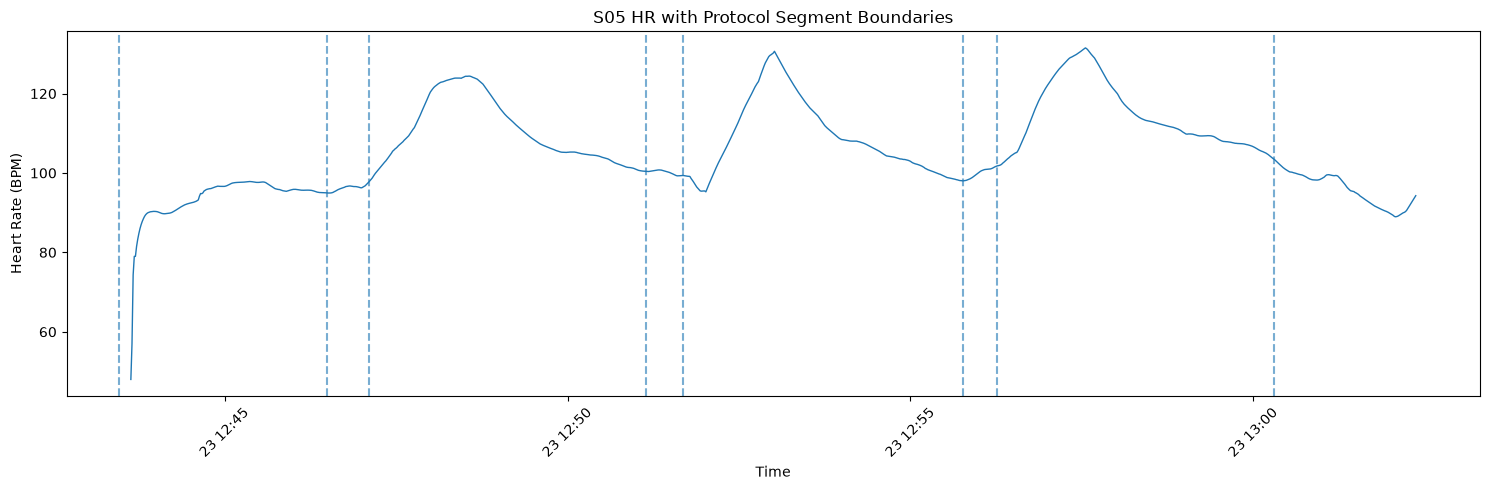

        label               start                        end  duration_sec
0    baseline 2013-02-23 12:43:28 2013-02-23 12:46:30.000000     182.00000
1    sprint_1 2013-02-23 12:46:30 2013-02-23 12:47:06.000000      36.00000
2  cooldown_1 2013-02-23 12:47:06 2013-02-23 12:51:09.000000     243.00000
3    sprint_2 2013-02-23 12:51:09 2013-02-23 12:51:41.000000      32.00000
4  cooldown_2 2013-02-23 12:51:41 2013-02-23 12:55:46.000000     245.00000
5    sprint_3 2013-02-23 12:55:46 2013-02-23 12:56:16.000000      30.00000
6  cooldown_3 2013-02-23 12:56:16 2013-02-23 13:00:18.000000     242.00000
7  final_rest 2013-02-23 13:00:18 2013-02-23 13:02:22.156250     124.15625


In [27]:
# Add final rest to our segment table
final_rest = pd.DataFrame([
    (
        "final_rest",
        final_rest_start,
        final_rest_end
    )
], columns=["label", "start", "end"])

final_rest["duration_sec"] = (
    final_rest["end"] - final_rest["start"]
).dt.total_seconds()

segments_df = pd.concat(
    [segments_df, final_rest],
    ignore_index=True
)

print(segments_df)

def get_segment(signal_df, start, end):
    return signal_df[
        (signal_df["timestamp"] >= start) &
        (signal_df["timestamp"] < end)
    ].copy()

hr_segments = {}

for _, row in segments_df.iterrows():
    segment = get_segment(
        hr_clean,
        row["start"],
        row["end"]
    )

    hr_segments[row["label"]] = segment

    print(
        row["label"],
        "→",
        len(segment),
        "samples"
    )

    plt.figure(figsize=(15, 5))

plt.plot(
    hr_clean["timestamp"],
    hr_clean["HR"],
    linewidth=1
)

for _, row in segments_df.iterrows():
    plt.axvline(
        row["start"],
        linestyle="--",
        alpha=0.6
    )

plt.xlabel("Time")
plt.ylabel("Heart Rate (BPM)")
plt.title("S05 HR with Protocol Segment Boundaries")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

segments_df = segments_df.drop_duplicates(
    subset=["label", "start", "end"]
).reset_index(drop=True)

print(segments_df)



In [26]:
segments = [
    ("baseline",   "2013-02-23 12:43:28", "2013-02-23 12:46:30"),
    ("sprint_1",   "2013-02-23 12:46:30", "2013-02-23 12:47:06"),
    ("cooldown_1", "2013-02-23 12:47:06", "2013-02-23 12:51:09"),
    ("sprint_2",   "2013-02-23 12:51:09", "2013-02-23 12:51:41"),
    ("cooldown_2", "2013-02-23 12:51:41", "2013-02-23 12:55:46"),
    ("sprint_3",   "2013-02-23 12:55:46", "2013-02-23 12:56:16"),
    ("cooldown_3", "2013-02-23 12:56:16", "2013-02-23 13:00:18"),
]

segments_df = pd.DataFrame(
    segments,
    columns=["label", "start", "end"]
)

segments_df["start"] = pd.to_datetime(segments_df["start"])
segments_df["end"] = pd.to_datetime(segments_df["end"])

segments_df["duration_sec"] = (
    segments_df["end"] - segments_df["start"]
).dt.total_seconds()

print(segments_df)

final_rest_start = pd.Timestamp("2013-02-23 13:00:18")
final_rest_end = acc_clean["timestamp"].iloc[-1]

print("Final rest:")
print(final_rest_start)
print(final_rest_end)
print(
    "Duration:",
    (final_rest_end - final_rest_start).total_seconds(),
    "seconds"
)

        label               start                 end  duration_sec
0    baseline 2013-02-23 12:43:28 2013-02-23 12:46:30         182.0
1    sprint_1 2013-02-23 12:46:30 2013-02-23 12:47:06          36.0
2  cooldown_1 2013-02-23 12:47:06 2013-02-23 12:51:09         243.0
3    sprint_2 2013-02-23 12:51:09 2013-02-23 12:51:41          32.0
4  cooldown_2 2013-02-23 12:51:41 2013-02-23 12:55:46         245.0
5    sprint_3 2013-02-23 12:55:46 2013-02-23 12:56:16          30.0
6  cooldown_3 2013-02-23 12:56:16 2013-02-23 13:00:18         242.0
Final rest:
2013-02-23 13:00:18
2013-02-23 13:02:22.156250
Duration: 124.15625 seconds


In [25]:
readme_path = DATA_PATH + "/README.txt"

with open(readme_path, "r", encoding="utf-8") as f:
    readme = f.read()

print(readme)

# FILES
- 'Stress_Level_v1.csv' and 'Stress_Level_v2.csv' contain self-reported stress levels during the stress protocol for each stage of the study,  respectively.
- 'subject-info.csv' contains demographic data such as age, weight, and height for all participants.
- 'data_constraints.txt' contains detailed information of issues such as incorrect wristband placements, incomplete protocols, and connection problems. 
- 'Wearable_Dataset.ipynb'  is a Jupyter Notebook that provides visualizations of all recorded signals and includes sample code for managing the data.
- The main folder 'Wearable_Dataset' contains three folders for each type of activity: 'STRESS', 'AEROBIC' and 'ANAEROBIC'.
- Each of these folders includes participant subfolders named as 'S01','S02','f01',etc.
- Each of the folders corresponding to each participant contains Empatica E4 files: 'ACC.csv', 'BVP.csv', 'EDA.csv', 'HR.csv', 'IBI.csv', 'tags.csv' and 'TEMP.csv'.

# RELEVANT INFO
- Before downloading, we recommend r

In [24]:
tags_path = (
    DATA_PATH +
    "/Wearable_Dataset/ANAEROBIC/S05/tags.csv"
)

with open(tags_path, "r") as f:
    for i in range(15):
        print(i, f.readline().strip())

0 2013-02-23 12:46:30
1 2013-02-23 12:47:06
2 2013-02-23 12:51:09
3 2013-02-23 12:51:41
4 2013-02-23 12:55:46
5 2013-02-23 12:56:16
6 2013-02-23 13:00:18
7 
8 
9 
10 
11 
12 
13 
14 


In [23]:
acc_clean = load_sensor_csv(
    DATA_PATH + "/Wearable_Dataset/ANAEROBIC/S05/ACC.csv",
    "ACC"
)

acc_clean["ACC_MAG"] = np.sqrt(
    acc_clean["ACC_X"]**2 +
    acc_clean["ACC_Y"]**2 +
    acc_clean["ACC_Z"]**2
)

print(acc_clean.head())
print("Shape:", acc_clean.shape)

                   timestamp  ACC_X  ACC_Y  ACC_Z    ACC_MAG
0 2013-02-23 12:43:28.000000   41.0   32.0   38.0  64.412732
1 2013-02-23 12:43:28.031250   43.0   30.0   37.0  64.171645
2 2013-02-23 12:43:28.062500   42.0   30.0   39.0  64.691576
3 2013-02-23 12:43:28.093750   45.0   33.0   34.0  65.345237
4 2013-02-23 12:43:28.125000   41.0   32.0   36.0  63.253458
Shape: (36294, 5)


In [22]:
constraints_path = DATA_PATH + "/data_constraints.txt"

with open(constraints_path, "r", encoding="cp1252") as f:
    constraints = f.read()

print(constraints)

STRESS
•	S02: Files downloaded from E4 Connect have duplicated signals. Duplicated raw values start in: ACC.csv: row 49,545; BVP.csv: row 99,091; EDA.csv and TEMP.csv: row 6,195. As IBI and HR files are obtained from the BVP signal through Empatica's algorithm, it is not evident where the duplicated data start.
•	f07: The protection dock was never removed from the wristband, covering the PPG and TEMPERATURE sensors. Thus, only the ELECTRODERMAL ACTIVITY AND ACCELEROMETER DATA measurements are valid.
•	f14: Bluetooth connection was lost during registration. The baseline is in file f14_a, and the rest of the protocol is in file f14_b.

AEROBIC
•	S03: Ended the protocol early, only reaching 90 rpm.
•	S07: Ended the protocol early, only reaching 95 rpm.
•	S11: Bluetooth connection was lost during registration. File S11_a includes data up to 105 rpm, and S11_b includes the last 110 rpm block.
•	S12: Did not perform the aerobic protocol, so there are no data.

ANAEROBIC
•	S01: The IBI file d

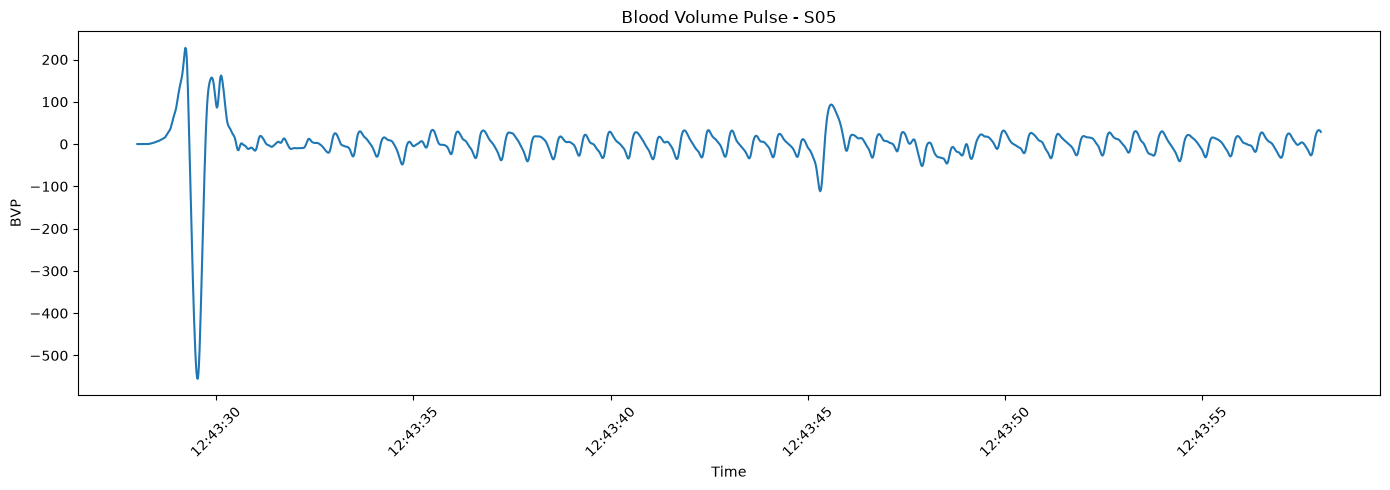

In [21]:
bvp_30 = bvp_clean[
    bvp_clean["timestamp"] <=
    bvp_clean["timestamp"].iloc[0] +
    pd.Timedelta(seconds=30)
]

plt.figure(figsize=(14, 5))

plt.plot(
    bvp_30["timestamp"],
    bvp_30["BVP"]
)

plt.xlabel("Time")
plt.ylabel("BVP")
plt.title("Blood Volume Pulse - S05")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
bvp_path = (
    DATA_PATH +
    "/Wearable_Dataset/ANAEROBIC/S05/BVP.csv"
)

bvp_clean = load_sensor_csv(bvp_path, "BVP")

print(bvp_clean.head())
print()
print("Shape:", bvp_clean.shape)
print()
print(bvp_clean["BVP"].describe())

                   timestamp  BVP
0 2013-02-23 12:43:28.000000 -0.0
1 2013-02-23 12:43:28.015625 -0.0
2 2013-02-23 12:43:28.031250 -0.0
3 2013-02-23 12:43:28.046875 -0.0
4 2013-02-23 12:43:28.062500 -0.0

Shape: (72589, 2)

count    72589.000000
mean         0.004841
std         49.010805
min       -643.810000
25%        -21.680000
50%          0.560000
75%         22.370000
max        436.190000
Name: BVP, dtype: float64


In [19]:
print("HR")
print(hr_clean["HR"].describe())

print("\nEDA")
print(eda_clean["EDA"].describe())

print("\nACC")
print(acc_clean[["ACC_X", "ACC_Y", "ACC_Z", "ACC_MAG"]].describe())

HR
count    1125.000000
mean      105.716764
std        10.845151
min        48.000000
25%        97.770000
50%       104.100000
75%       112.080000
max       131.500000
Name: HR, dtype: float64

EDA
count    4536.000000
mean       41.501456
std        18.581407
min         0.000000
25%        36.254459
50%        48.000366
75%        56.899231
max        63.785847
Name: EDA, dtype: float64

ACC
              ACC_X         ACC_Y         ACC_Z       ACC_MAG
count  36294.000000  36294.000000  36294.000000  36294.000000
mean      30.088086     36.444371     37.892241     64.276741
std       17.476613      9.351471      9.594937      4.768618
min     -128.000000    -85.000000    -54.000000     16.309506
25%       25.000000     33.000000     35.000000     63.031738
50%       34.000000     36.000000     40.000000     63.835727
75%       40.000000     41.000000     43.000000     64.876806
max      127.000000    127.000000    127.000000    185.415749


In [18]:
print("Temperature statistics:")
print(temp_clean["TEMP"].describe())
print("\nUnique temperature values:")
print(temp_clean["TEMP"].value_counts().head(20))
print("\nMinimum:", temp_clean["TEMP"].min())
print("Maximum:", temp_clean["TEMP"].max())
print(
    temp_clean[
        (temp_clean["TEMP"] > 100) |
        (temp_clean["TEMP"] < 0)
    ].head(20)
)

Temperature statistics:
count    4536.000000
mean      142.847337
std        84.460120
min        34.750000
25%        35.370000
50%       208.750000
75%       209.050000
max       220.870000
Name: TEMP, dtype: float64

Unique temperature values:
TEMP
209.05    660
209.07    304
208.69    208
209.41    172
209.43    164
209.45    156
208.75    152
208.71    144
35.47     124
208.73    116
208.91    112
209.13    112
209.03    112
34.84      92
34.93      88
35.49      88
34.95      84
35.45      76
35.50      72
34.89      60
Name: count, dtype: int64

Minimum: 34.75
Maximum: 220.87
                 timestamp    TEMP
0  2013-02-23 12:43:28.000  208.95
1  2013-02-23 12:43:28.250  208.95
2  2013-02-23 12:43:28.500  208.95
3  2013-02-23 12:43:28.750  208.95
4  2013-02-23 12:43:29.000  208.95
5  2013-02-23 12:43:29.250  208.95
6  2013-02-23 12:43:29.500  208.95
7  2013-02-23 12:43:29.750  208.95
8  2013-02-23 12:43:30.000  208.97
9  2013-02-23 12:43:30.250  208.97
10 2013-02-23 12:43:30.50

                   timestamp  ACC_X  ACC_Y  ACC_Z    ACC_MAG
0 2013-02-23 12:43:28.000000   41.0   32.0   38.0  64.412732
1 2013-02-23 12:43:28.031250   43.0   30.0   37.0  64.171645
2 2013-02-23 12:43:28.062500   42.0   30.0   39.0  64.691576
3 2013-02-23 12:43:28.093750   45.0   33.0   34.0  65.345237
4 2013-02-23 12:43:28.125000   41.0   32.0   36.0  63.253458


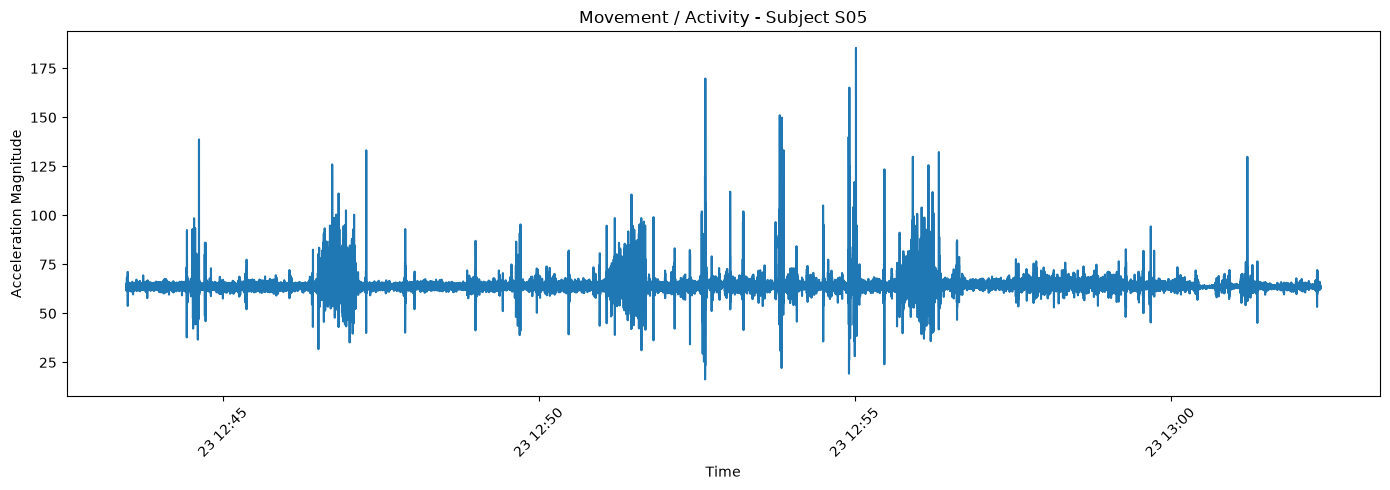

In [17]:
acc_clean["ACC_MAG"] = np.sqrt(
    acc_clean["ACC_X"]**2 +
    acc_clean["ACC_Y"]**2 +
    acc_clean["ACC_Z"]**2
)

print(acc_clean.head())

plt.figure(figsize=(14, 5))

plt.plot(
    acc_clean["timestamp"],
    acc_clean["ACC_MAG"]
)

plt.xlabel("Time")
plt.ylabel("Acceleration Magnitude")
plt.title("Movement / Activity - Subject S05")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

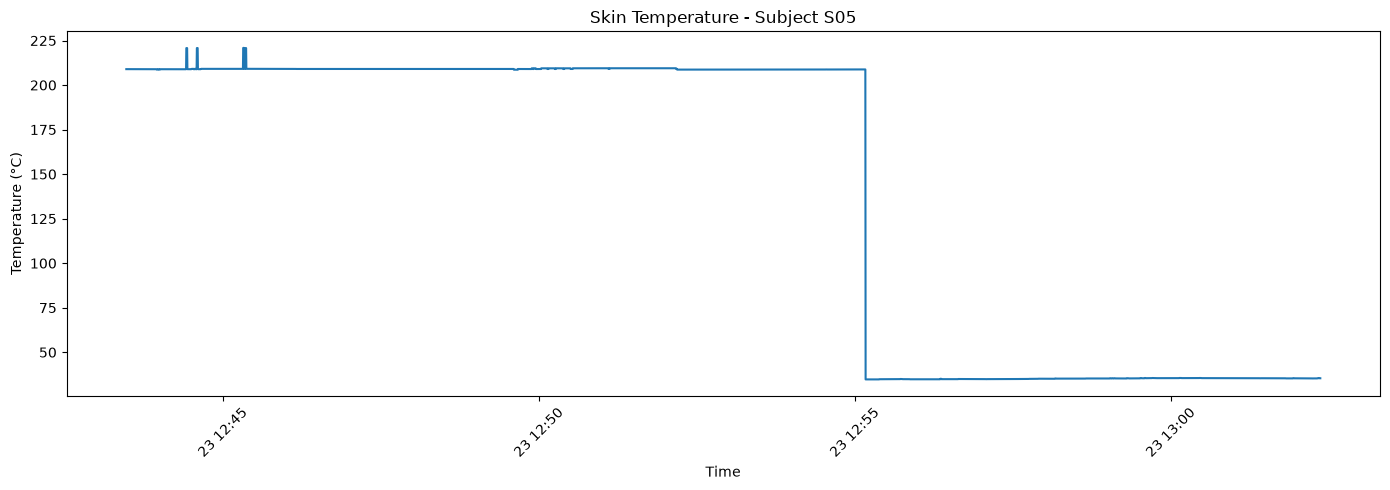

In [16]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 5))

plt.plot(
    temp_clean["timestamp"],
    temp_clean["TEMP"]
)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("Skin Temperature - Subject S05")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



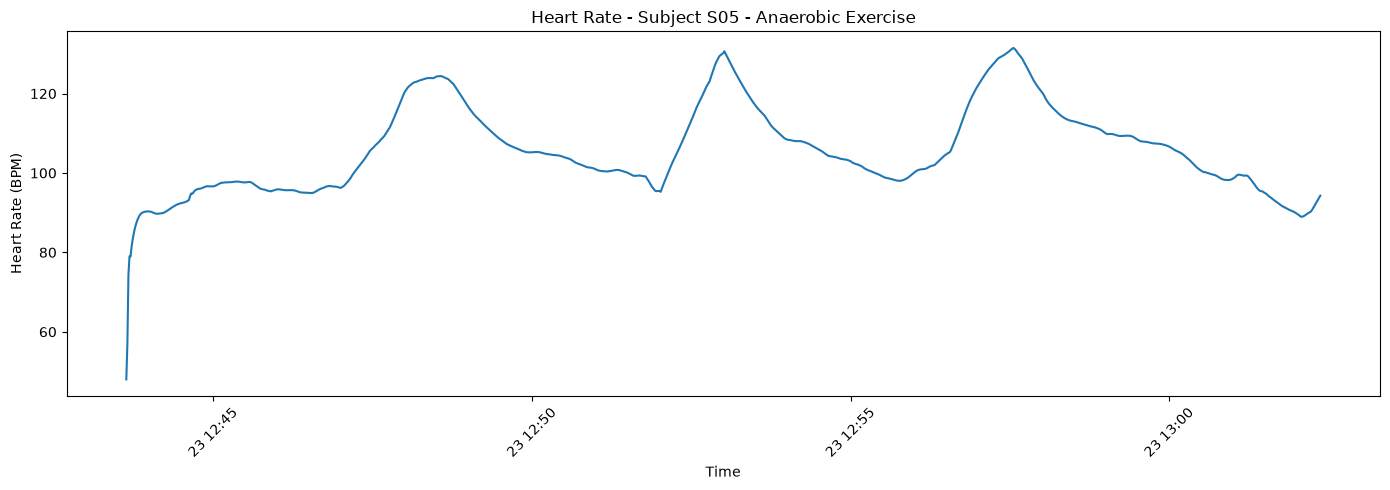

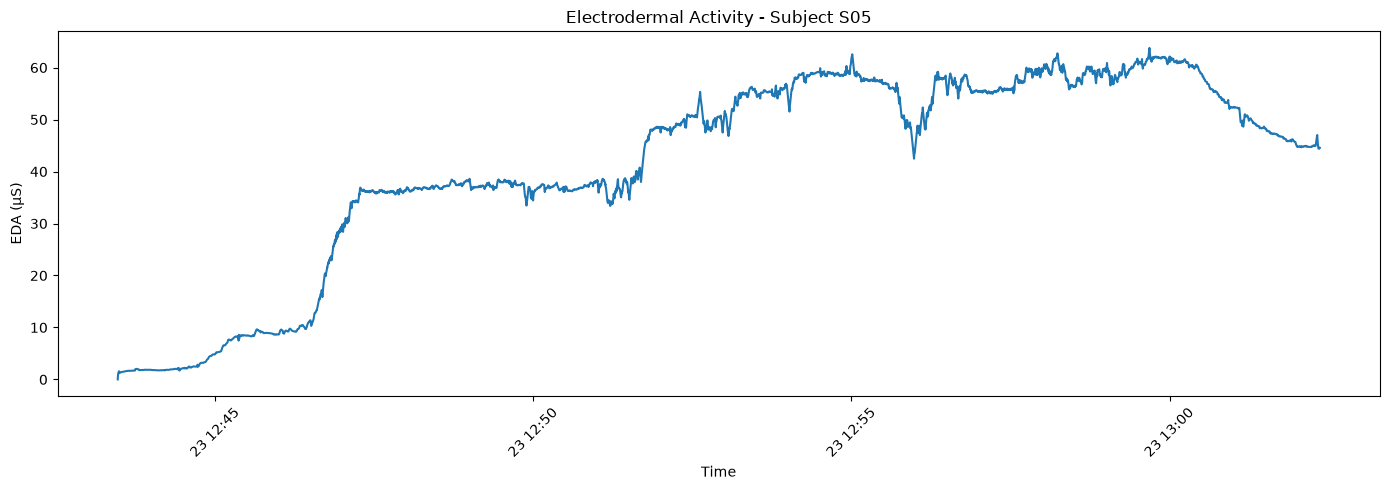

In [15]:

import matplotlib.pyplot as plt
plt.figure(figsize=(14, 5))

plt.plot(
    hr_clean["timestamp"],
    hr_clean["HR"]
)

plt.xlabel("Time")
plt.ylabel("Heart Rate (BPM)")
plt.title("Heart Rate - Subject S05 - Anaerobic Exercise")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 5))

plt.plot(
    eda_clean["timestamp"],
    eda_clean["EDA"]
)

plt.xlabel("Time")
plt.ylabel("EDA (µS)")
plt.title("Electrodermal Activity - Subject S05")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
acc_path = (
    DATA_PATH +
    "/Wearable_Dataset/ANAEROBIC/S05/ACC.csv"
)

acc_clean = load_sensor_csv(acc_path, "ACC")

print(acc_clean.head())
print()
print("Shape:", acc_clean.shape)

                   timestamp  ACC_X  ACC_Y  ACC_Z
0 2013-02-23 12:43:28.000000   41.0   32.0   38.0
1 2013-02-23 12:43:28.031250   43.0   30.0   37.0
2 2013-02-23 12:43:28.062500   42.0   30.0   39.0
3 2013-02-23 12:43:28.093750   45.0   33.0   34.0
4 2013-02-23 12:43:28.125000   41.0   32.0   36.0

Shape: (36294, 4)


In [13]:
temp_path = (
    DATA_PATH +
    "/Wearable_Dataset/ANAEROBIC/S05/TEMP.csv"
)

temp_clean = load_sensor_csv(temp_path, "TEMP")

print(temp_clean.head())
print()
print("Shape:", temp_clean.shape)


                timestamp    TEMP
0 2013-02-23 12:43:28.000  208.95
1 2013-02-23 12:43:28.250  208.95
2 2013-02-23 12:43:28.500  208.95
3 2013-02-23 12:43:28.750  208.95
4 2013-02-23 12:43:29.000  208.95

Shape: (4536, 2)


In [10]:
eda_path = (
    DATA_PATH +
    "/Wearable_Dataset/ANAEROBIC/S05/EDA.csv"
)

eda_clean = load_sensor_csv(eda_path, "EDA")

print(eda_clean.head())
print()
print("Shape:", eda_clean.shape)

                timestamp       EDA
0 2013-02-23 12:43:28.000  0.000000
1 2013-02-23 12:43:28.250  0.836457
2 2013-02-23 12:43:28.500  1.183860
3 2013-02-23 12:43:28.750  1.392723
4 2013-02-23 12:43:29.000  1.446523

Shape: (4536, 2)


In [12]:
DATA_PATH = "../data/raw/wearable"
hr_path = (
    DATA_PATH +
    "/Wearable_Dataset/ANAEROBIC/S05/HR.csv"
)

hr_clean = load_sensor_csv(hr_path, "HR")

print(hr_clean.head(10))
print()
print("Shape:", hr_clean.shape)
print()
print(hr_clean.dtypes)

            timestamp     HR
0 2013-02-23 12:43:38  48.00
1 2013-02-23 12:43:39  57.00
2 2013-02-23 12:43:40  74.33
3 2013-02-23 12:43:41  79.00
4 2013-02-23 12:43:42  79.00
5 2013-02-23 12:43:43  81.50
6 2013-02-23 12:43:44  83.29
7 2013-02-23 12:43:45  84.75
8 2013-02-23 12:43:46  86.00
9 2013-02-23 12:43:47  87.00

Shape: (1125, 2)

timestamp    datetime64[us]
HR                  float64
dtype: object


In [11]:
import csv
import pandas as pd
import numpy as np


def load_sensor_csv(file_path, sensor_type):
    """
    Load a wearable sensor CSV and convert it into a clean DataFrame.

    Parameters
    ----------
    file_path : str
        Path to the CSV file.

    sensor_type : str
        One of:
        HR, EDA, TEMP, BVP, IBI, ACC

    Returns
    -------
    pandas.DataFrame
    """

    with open(file_path, "r") as f:
        rows = list(csv.reader(f))

    # First row contains the starting timestamp
    start_time = pd.to_datetime(rows[0][0])

    # --------------------------------------------------
    # ACC has three columns: X, Y, Z
    # --------------------------------------------------
    
    if sensor_type == "ACC":
        values = np.array(
            [[float(x) for x in row[:3]] for row in rows[2:]],
            dtype=float
        )

        timestamps = pd.date_range(
            start=start_time,
            periods=len(values),
            freq=pd.Timedelta(seconds=1/32)
        )

        df = pd.DataFrame(
            values,
            columns=["ACC_X", "ACC_Y", "ACC_Z"]
        )
        df.insert(0, "timestamp", timestamps)
        return df


    # --------------------------------------------------
    # Other sensors have one value per row
    # --------------------------------------------------

    values = np.array(
        [float(row[0]) for row in rows[2:]],
        dtype=float
    )

    # Sampling frequencies from the dataset
    sampling_rates = {
        "HR": 1,
        "EDA": 4,
        "TEMP": 4,
        "BVP": 64,
        "IBI": None
    }

    rate = sampling_rates[sensor_type]

    if rate is not None:

        timestamps = pd.date_range(
            start=start_time,
            periods=len(values),
            freq=pd.Timedelta(seconds=1/rate)
        )

        df = pd.DataFrame({
            "timestamp": timestamps,
            sensor_type: values
        })

    else:
        # IBI has no fixed sampling frequency
        df = pd.DataFrame({
            "IBI": values
        })

    return df